# Can LLMs Deliberate? 

## Benchmarking Deliberative Capabilities in Multi-Agent LLM Simulations


---

# 0. Setup

In [91]:
# Imports

import os
import ast
import re
from pathlib import Path
import pandas as pd
import json as json_module
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.spatial.distance import pdist
from statsmodels.stats.multitest import multipletests
import warnings
from itertools import combinations
from collections import defaultdict

warnings.filterwarnings('ignore')

In [92]:
# Font Setup

import matplotlib as mpl
from matplotlib import font_manager as fm

FONT_PATH = "/usr/share/fonts/opentype/urw-base35/NimbusRoman-Regular.otf"

# 1) Prevent Type 3 in PDF/PS
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"]  = 42

# 2) Register the font with Matplotlib
fm.fontManager.addfont(FONT_PATH)

# 3) Use it as the default serif font
nimbus_name = fm.FontProperties(fname=FONT_PATH).get_name()  # should resolve now
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [nimbus_name],
})

In [3]:
# Plot Settings

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [4]:
# Project config + canonical labels

PROJECT_ROOT = Path(os.environ.get("DELIB_SIM_ROOT"))

TOPIC_COL = "topic"
MODEL_COL = "model_label"
COND_COL  = "condition_label"

# Data paths
AQUA_SCORES_PATH = PROJECT_ROOT / "delib_sim" / "data" / "simulation_results" / "aqua_scores.csv"
FINAL_DATA_DIR   = PROJECT_ROOT / "delib_sim" / "data" / "simulation_results" 
HUMAN_DATA_PATH  = PROJECT_ROOT / "delib_sim" / "data" / "human_data" / "human_data.csv"
EUROPOLIS_PATH   = PROJECT_ROOT / "delib_sim" / "external" / "AQuA" / "output" / "europolis" / "europolis_inference.csv"

# Output paths
FIGURES_DIR = PROJECT_ROOT / "analysis" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# Canonical condition labels
CONDITION_CANON = {
    "control_1": "No Treatment",
    "control_2": "Basic Treatment",
    "treatment": "Normative Treatment",
}

CONDITION_COLORS = {
    "No Treatment": "#7f8c8d",
    "Basic Treatment": "#3498db",
    "Normative Treatment": "#9b59b6",
    "Human": "#2ecc71",
}

CONDITIONS = {
    "Control": "No Treatment",
    "Basic": "Basic Treatment",
    "Normative": "Normative Treatment",
}

PAIRWISE = [
    ("Normative vs No Treatment", CONDITIONS["Normative"], CONDITIONS["Control"]),
    ("Basic vs No Treatment", CONDITIONS["Basic"], CONDITIONS["Control"]),
    ("Normative vs Basic Treatment", CONDITIONS["Normative"], CONDITIONS["Basic"]),
]

TOPIC_COL_CANDIDATES = ["topic_label", "topic", "issue", "issue_label"]

# Canonical model labels
MODEL_CANON = {
    # Claude/Anthropic
    "claude-opus-4.5": "Claude Opus 4.5",
    "anthropic": "Claude Opus 4.5",

    # DeepSeek
    "deepseek-v3.2-exp-no-reasoning": "DeepSeek-NR",
    "deepseek-v3.2-exp-reasoning": "DeepSeek-R",

    # Google/Gemini
    "gemini-3-pro-preview-no-reasoning": "Gemini-3-NR",
    "gemini-3-pro-preview-reasoning": "Gemini-3-R",
    "google-no-reasoning": "Gemini-3-NR",
    "google-reasoning": "Gemini-3-R",

    # OpenAI
    "gpt-5.1-no-reasoning": "GPT-5.1-NR",
    "gpt-5.1-reasoning": "GPT-5.1-R",
    "openai-no-reasoning": "GPT-5.1-NR",
    "openai-reasoning": "GPT-5.1-R",

    # Moonshot/Kimi
    "kimi-k2-thinking-no-reasoning": "Kimi-K2-NR",
    "kimi-k2-thinking-reasoning": "Kimi-K2-R",
    "moonshotai-no-reasoning": "Kimi-K2-NR",
    "moonshotai-reasoning": "Kimi-K2-R",

    # Mixed
    "mixed-no-reasoning": "Mixed-NR",
    "mixed-reasoning": "Mixed-R",
}


def map_model_canon(raw: str | None) -> str | None:
    """
    Map arbitrary model key / folder name into the canonical labels used in the paper.
    """
    if raw is None or pd.isna(raw):
        return None

    # exact match first
    if raw in MODEL_CANON:
        return MODEL_CANON[raw]

    s = str(raw).lower()
    is_nr = ("no-reasoning" in s) or ("no_reasoning" in s)

    if ("claude" in s) or ("anthropic" in s):
        return "Claude Opus 4.5"
    if "deepseek" in s:
        return "DeepSeek-NR" if is_nr else "DeepSeek-R"
    if ("gemini" in s) or ("google" in s):
        return "Gemini-3-NR" if is_nr else "Gemini-3-R"
    if ("gpt" in s) or ("openai" in s):
        return "GPT-5.1-NR" if is_nr else "GPT-5.1-R"
    if ("kimi" in s) or ("moonshot" in s):
        return "Kimi-K2-NR" if is_nr else "Kimi-K2-R"
    if "mixed" in s:
        return "Mixed-NR" if is_nr else "Mixed-R"

    return str(raw)

def canon_condition_label(dirname: str) -> str:
    """
    Map a filesystem condition folder name to a canonical condition label.
    Uses substring matching (so 'control_1', 'control_1_x', etc. all work).
    """
    s = str(dirname).lower()
    for key, canon in CONDITION_CANON.items():
        if key in s:
            return canon
    return dirname 

In [5]:
# Statistical helpers

BOOT_B = 20000            # block bootstrap draws (final: 20000)
BOOT_B_PARAM = 2000       # block parametric bootstrap draws (final: 2000)     
PERM_B = 50000            # blocked permutation draws (final: 50000)
RNG_SEED = 42


def topic_cluster_mean_ci(
    df: pd.DataFrame,
    value_col: str,
    topic_col: str = "topic",
    conf: float = 0.95,
    B: int = BOOT_B,
    seed: int = RNG_SEED,
):
    """
    Mean aggregated at topic-level (cluster-robust by design):
      - estimate = average of topic means
      - design-based CI uses t-interval over topic means
      - bootstrap CI resamples topics with replacement
    """
    subset = df[[topic_col, value_col]].dropna()
    if subset.empty:
        return dict(
            mean=np.nan, n_clusters=0,
            se_design=np.nan, ci_design=(np.nan, np.nan),
            ci_boot=(np.nan, np.nan),
            series=pd.Series(dtype=float),
        )

    topic_means = subset.groupby(topic_col)[value_col].mean()
    n = len(topic_means)
    mean_val = float(topic_means.mean())

    # design-based CI (t over topic means)
    se_design = float(topic_means.std(ddof=1) / np.sqrt(n)) if n > 1 else np.nan
    alpha = 1 - conf
    tcrit = stats.t.ppf(1 - alpha / 2, df=n - 1) if n > 1 else np.nan
    ci_design = (mean_val - tcrit * se_design, mean_val + tcrit * se_design) if n > 1 else (np.nan, np.nan)

    # bootstrap CI (resample topics)
    rng = np.random.default_rng(seed)
    boot_draws = rng.choice(topic_means.to_numpy(), size=(B, n), replace=True).mean(axis=1) if n > 0 else np.array([np.nan])
    ci_boot = tuple(np.percentile(boot_draws, [2.5, 97.5])) if n > 0 else (np.nan, np.nan)

    return dict(
        mean=mean_val,
        n_clusters=n,
        se_design=se_design,
        ci_design=ci_design,
        ci_boot=ci_boot,
        series=topic_means,
    )

def _draw_cluster_weights(n_clusters, rng, weight_type="webb"):
    """
    Cluster-level weights for wild bootstrap.
    - 'rademacher': +/- 1 with prob 0.5
    - 'webb': 6-point distribution recommended for very few clusters
      values: +/-sqrt(3/2), +/-1, +/-sqrt(1/2), each with prob 1/6
    """
    if weight_type.lower() in ["rademacher", "rademacher2", "rade"]:
        return rng.choice([-1.0, 1.0], size=n_clusters, replace=True)

    if weight_type.lower() in ["webb", "webb6", "sixpoint", "6point"]:
        vals = np.array([
            -np.sqrt(3/2), -1.0, -np.sqrt(1/2),
             np.sqrt(1/2),  1.0,  np.sqrt(3/2)
        ], dtype=float)
        return rng.choice(vals, size=n_clusters, replace=True)

    raise ValueError("weight_type must be one of {'webb','rademacher'}")


def wild_cluster_bootstrap_pvalue(
    df,
    formula_unrestricted="post ~ pre + is_llm",
    formula_restricted="post ~ pre",
    cluster_col="topic",
    coef_name="is_llm",
    B=BOOT_B,
    weight_type="webb",
    seed=0,
    two_sided=True,
):
    """
    Wild cluster bootstrap-t p-value for H0: coef_name = 0.
    Uses restricted residuals (under H0) + refit unrestricted each bootstrap.
    """
    df = df.copy()

    # Make cluster ids dense 0..G-1
    clusters, cluster_ids = np.unique(df[cluster_col].values, return_inverse=True)
    G = len(clusters)

    # Fit observed (unrestricted) model with cluster-robust SEs
    fit_u = smf.ols(formula_unrestricted, data=df).fit(
        cov_type="cluster", cov_kwds={"groups": cluster_ids}
    )
    if coef_name not in fit_u.params.index:
        raise ValueError(f"coef_name='{coef_name}' not in model params: {fit_u.params.index.tolist()}")

    t_obs = fit_u.tvalues[coef_name]

    # Fit restricted model (H0)
    fit_r = smf.ols(formula_restricted, data=df).fit()
    yhat_r = fit_r.fittedvalues.values
    resid_r = fit_r.resid.values

    rng = np.random.default_rng(seed)

    t_star = np.empty(B, dtype=float)

    for b in range(B):
        w = _draw_cluster_weights(G, rng, weight_type=weight_type)
        # Apply cluster weight to each observation's residual
        y_star = yhat_r + resid_r * w[cluster_ids]

        df["_y_star"] = y_star
        fit_b = smf.ols(formula_unrestricted.replace("post__", "_y_star"), data=df).fit(
            cov_type="cluster", cov_kwds={"groups": cluster_ids}
        )
        t_star[b] = fit_b.tvalues[coef_name]

    if two_sided:
        p = (np.sum(np.abs(t_star) >= np.abs(t_obs)) + 1.0) / (B + 1.0)
    else:
        # one-sided in direction of t_obs
        if t_obs >= 0:
            p = (np.sum(t_star >= t_obs) + 1.0) / (B + 1.0)
        else:
            p = (np.sum(t_star <= t_obs) + 1.0) / (B + 1.0)

    return {
        "B": B,
        "clusters": G,
        "weight_type": weight_type,
        "t_obs": float(t_obs),
        "coef_obs": float(fit_u.params[coef_name]),
        "se_obs": float(fit_u.bse[coef_name]),
        "p_value": float(p),
    }


def wild_cluster_bootstrap_ci(
    df,
    formula_unrestricted="post ~ pre + is_llm",
    cluster_col="topic",
    coef_name="is_llm",
    B=BOOT_B,
    weight_type="webb",
    seed=1,
    alpha=0.05,
):
    """
    Wild cluster bootstrap-t confidence interval for coef_name.
    Uses unrestricted residuals (recommended for CI).

    Procedure:
      1) Fit unrestricted model, get coef_hat, se_hat, fitted, residuals.
      2) For each b: y* = yhat + resid * w_cluster; refit unrestricted with cluster-robust SEs
         compute t_b = (coef_b - coef_hat) / se_b
      3) CI = [coef_hat - q_{1-alpha/2}(t_b)*se_hat, coef_hat - q_{alpha/2}(t_b)*se_hat]
    """
    df = df.copy()

    clusters, cluster_ids = np.unique(df[cluster_col].values, return_inverse=True)
    G = len(clusters)

    # Fit observed (unrestricted) model with cluster-robust SEs
    fit_u = smf.ols(formula_unrestricted, data=df).fit(
        cov_type="cluster", cov_kwds={"groups": cluster_ids}
    )
    coef_hat = float(fit_u.params[coef_name])
    se_hat = float(fit_u.bse[coef_name])

    # Unrestricted fitted values + residuals (from plain OLS fit, not clustered—residuals are the same)
    fit_plain = smf.ols(formula_unrestricted, data=df).fit()
    yhat = fit_plain.fittedvalues.values
    resid = fit_plain.resid.values

    rng = np.random.default_rng(seed)

    t_b = np.empty(B, dtype=float)

    for b in range(B):
        w = _draw_cluster_weights(G, rng, weight_type=weight_type)
        y_star = yhat + resid * w[cluster_ids]

        df["_y_star"] = y_star
        fit_b = smf.ols(formula_unrestricted.replace("post__", "_y_star"), data=df).fit(
            cov_type="cluster", cov_kwds={"groups": cluster_ids}
        )

        coef_b = float(fit_b.params[coef_name])
        se_b = float(fit_b.bse[coef_name])
        # guard against extremely small SEs
        if se_b <= 1e-12 or np.isnan(se_b):
            t_b[b] = np.nan
        else:
            t_b[b] = (coef_b - coef_hat) / se_b

    t_b = t_b[~np.isnan(t_b)]
    if len(t_b) < 0.9 * B:
        print(f"Warning: dropped many bootstrap draws due to invalid SEs ({B - len(t_b)} drops).")

    q_lo = np.quantile(t_b, alpha / 2)
    q_hi = np.quantile(t_b, 1 - alpha / 2)

    ci_low = coef_hat - q_hi * se_hat
    ci_high = coef_hat - q_lo * se_hat

    return {
        "B": B,
        "clusters": G,
        "weight_type": weight_type,
        "coef_hat": coef_hat,
        "se_hat": se_hat,
        "alpha": alpha,
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "t_quantiles": (float(q_lo), float(q_hi)),
    }


## AQuA

In [6]:
# Standalone AQuA loader + cleaning + canonical labels

# -----------------------------
# 0) Paths
# -----------------------------
try:
    AQUA_SCORES_PATH
except NameError:
    raise NameError("Define AQUA_SCORES_PATH (Path or str) before running this cell.")

try:
    EUROPOLIS_PATH
except NameError:
    # If you have PROJECT_ROOT in scope, this will work; otherwise define EUROPOLIS_PATH directly.
    try:
        EUROPOLIS_PATH = PROJECT_ROOT / "delib_sim" / "external" / "AQuA" / "output" / "europolis" / "europolis_inference.csv"
    except NameError:
        raise NameError("Define EUROPOLIS_PATH (Path or str), or define PROJECT_ROOT so EUROPOLIS_PATH can be inferred.")


# -----------------------------
# 2) Load CSV
# -----------------------------
aqua_df = pd.read_csv(AQUA_SCORES_PATH)


print("Loaded AQuA CSV rows:", len(aqua_df))
print("Columns:", list(aqua_df.columns))


# -----------------------------
# 3) Parse quality_indices -> dict + per-dimension columns
# -----------------------------
QUALITY_DIMS = [
    "relevance", "fact", "opinion", "justification", "solproposal",
    "addknowledge", "question", "refusers", "refmedium", "refcontents",
    "refpersonal", "refformat", "address", "respect", "screaming",
    "vulgar", "insult", "sarcasm", "discrimination", "storytelling",
]

def parse_quality_indices(s):
    if s is None or pd.isna(s) or str(s).strip() == "":
        return {}
    try:
        return ast.literal_eval(s)
    except Exception:
        return {}

aqua_df["quality_dict"] = aqua_df["quality_indices"].apply(parse_quality_indices)
for dim in QUALITY_DIMS:
    aqua_df[f"dim_{dim}"] = aqua_df["quality_dict"].apply(lambda d: d.get(dim, np.nan))


# -----------------------------
# 4) Robust extraction helpers
# -----------------------------
# condition: capture control_1 / control_2 / treatment from any string
RE_COND = re.compile(r"(?:^|[/_])condition_(control_1|control_2|treatment)(?:[/_]|$)")

# topic: capture topic_<...> allowing underscores until next "/" (or end)
RE_TOPIC = re.compile(r"(?:^|[/_])topic_([^/]+?)(?:/|$)")

# model_full from transcript_path:
# example:
#   .../model_deepseek/deepseek-v3.2-exp-no-reasoning_condition_control_2_topic_ccps/...
# capture folder between .../model_xxx/ and _condition_
RE_MODEL_FULL = re.compile(r"(?:^|/)model_[^/]+/([^/]+?)(?:_condition_|/deliberation_transcript)")

def _join_row_strings(row, cols):
    parts = []
    for c in cols:
        v = row.get(c, None)
        if pd.notna(v):
            parts.append(str(v).lower())
    return " | ".join(parts)

def extract_condition_raw(row) -> str | None:
    s = _join_row_strings(row, ["condition", "study_timestamp", "transcript_path"])
    m = RE_COND.search(s)
    if m:
        return m.group(1)
    # Sometimes the CSV has a clean condition column already
    v = row.get("condition", None)
    if pd.notna(v) and str(v).strip() != "":
        vv = str(v).strip().lower()
        if vv in {"control_1", "control_2", "treatment"}:
            return vv
    return None

def extract_topic_best(row) -> str | None:
    # Prefer transcript_path ALWAYS (topic column is sometimes truncated/legacy)
    tp = row.get("transcript_path", None)
    if pd.notna(tp):
        m = RE_TOPIC.search(str(tp))
        if m:
            return m.group(1)

    # Fallback: model_full-ish strings
    for c in ["model_full", "model_full_from_path", "study_timestamp"]:
        v = row.get(c, None)
        if pd.notna(v):
            m = RE_TOPIC.search(str(v))
            if m:
                return m.group(1)

    # Last resort: existing topic column (may be truncated)
    t = row.get("topic", None)
    if pd.notna(t) and str(t).strip() != "" and str(t).lower() != "none":
        return str(t).strip()

    return None

def extract_model_full_from_path(row) -> str | None:
    tp = row.get("transcript_path", None)
    if tp is None or pd.isna(tp):
        return None
    m = RE_MODEL_FULL.search(str(tp))
    if m:
        return m.group(1)
    return None

def infer_reasoning_flag(row) -> bool | None:
    """
    False => NR
    True  => R
    None  => unknown
    Priority: study_timestamp > transcript_path > model_full-ish
    """
    s = _join_row_strings(row, ["study_timestamp", "transcript_path", "model_full", "model_full_from_path", "model_key"])

    # NR markers FIRST (critical: "no_reasoning" contains "reasoning")
    if ("no_reasoning" in s) or ("no-reasoning" in s) or ("no reasoning" in s):
        return False
    if ("mixed_no_reasoning" in s) or ("mixed-no-reasoning" in s):
        return False

    # R markers
    if ("mixed_reasoning" in s) or ("mixed-reasoning" in s):
        return True
    if re.search(r"(?:^|[-_/ ])reasoning(?:$|[-_/ ])", s):
        return True

    return None

def fix_model_full(row) -> str | None:
    """
    Build model_full_fixed that encodes mixed reasoning correctly.
    For non-mixed: prefer model_full_from_path; else model_full; else model_key.
    For mixed: if folder name is ambiguous (e.g., 'mixed_models_condition_*'), use inferred reasoning.
    """
    base = None
    for c in ["model_full_from_path", "model_full", "model_key"]:
        v = row.get(c, None)
        if pd.notna(v) and str(v).strip() != "":
            base = str(v).strip()
            break
    if base is None:
        return None

    s = base.lower()

    # Detect mixed variants robustly
    is_mixed = ("mixed" in s) or ("mixed_models" in s) or (str(row.get("model_key", "")).lower() == "mixed")
    if is_mixed:
        r = row.get("is_reasoning_inferred", None)
        if r is False:
            return "mixed-no-reasoning"
        if r is True:
            return "mixed-reasoning"
        # If still unknown, try to infer from base string itself
        if ("no_reasoning" in s) or ("no-reasoning" in s):
            return "mixed-no-reasoning"
        if ("reasoning" in s):
            return "mixed-reasoning"
        return base

    return base


# -----------------------------
# 5) Apply extraction: condition/topic/model
# -----------------------------
# condition raw + DRI-aligned condition label
aqua_df["condition_raw"] = aqua_df.apply(extract_condition_raw, axis=1)
aqua_df["condition_label"] = aqua_df["condition_raw"].map(CONDITION_CANON)

# model_full from path
aqua_df["model_full_from_path"] = aqua_df.apply(extract_model_full_from_path, axis=1)

# reasoning inference
aqua_df["is_reasoning_inferred"] = aqua_df.apply(infer_reasoning_flag, axis=1)

# build model_full_fixed and canonical model_label
aqua_df["model_full_fixed"] = aqua_df.apply(fix_model_full, axis=1)
aqua_df["model_label"] = aqua_df["model_full_fixed"].apply(map_model_canon)

# topic backfill: ALWAYS prefer transcript_path-derived topic (underscores allowed)
aqua_df["topic"] = aqua_df.apply(extract_topic_best, axis=1)


# -----------------------------
# 6) Filter valid
# -----------------------------
aqua_valid = aqua_df[
    aqua_df["aqua_score"].notna()
    & (aqua_df.get("is_error", False) != True)
].copy()


# -----------------------------
# 7) Sanity diagnostics
# -----------------------------
print("\nAQuA valid runs:", len(aqua_valid))

print("\nCondition_raw counts:", aqua_valid["condition_raw"].value_counts(dropna=False).to_dict())
print("condition_label counts:", aqua_valid["condition_label"].value_counts(dropna=False).to_dict())

print("\nReasoning inferred counts:", aqua_valid["is_reasoning_inferred"].value_counts(dropna=False).to_dict())

print("\nModel_label counts:")
print(aqua_valid["model_label"].value_counts(dropna=False).to_string())

print("\nTopic missing after fix:", int(aqua_valid["topic"].isna().sum()))
print("\nTopic counts (top 30):")
print(aqua_valid["topic"].value_counts(dropna=False).head(30).to_string())

TRUNCATED = {"swiss", "energy", "biobanking", "uppsala"}
bad = aqua_valid[aqua_valid["topic"].isin(TRUNCATED)]
print("\nRows still having truncated topics:", len(bad))
if len(bad) > 0:
    print(bad[["topic", "transcript_path", "model_full_fixed"]].head(25).to_string(index=False))

print("\nCross-tab: model_label × condition_label")
print(pd.crosstab(aqua_valid["model_label"], aqua_valid["condition_label"], dropna=False).to_string())


# -----------------------------
# 8) Europolis baseline
# -----------------------------
europolis_df = pd.read_csv(EUROPOLIS_PATH, sep="\t")
europolis_scores = europolis_df["score"].dropna()

print("\nLoaded Europolis human baseline:", len(europolis_scores), "comments")


Loaded AQuA CSV rows: 1320
Columns: ['study_timestamp', 'model_key', 'condition', 'topic', 'repetition', 'aqua_score', 'num_comments', 'num_turns', 'translation_method', 'transcript_path', 'assessment_timestamp', 'quality_indices', 'per_turn_scores', 'translation_applied', 'original_language', 'is_error', 'error']

AQuA valid runs: 1320

Condition_raw counts: {'control_2': 660, 'treatment': 660}
condition_label counts: {'Basic Treatment': 660, 'Normative Treatment': 660}

Reasoning inferred counts: {False: 600, True: 600, None: 120}

Model_label counts:
model_label
DeepSeek-NR        120
DeepSeek-R         120
Kimi-K2-NR         120
Kimi-K2-R          120
Gemini-3-NR        120
Gemini-3-R         120
GPT-5.1-NR         120
GPT-5.1-R          120
Claude Opus 4.5    120
Mixed-R            120
Mixed-NR           120

Topic missing after fix: 0

Topic counts (top 30):
topic
ccps              110
auscj             110
bep               110
biobanking_wa     110
energy_futures    110
fnqcj  

## DRI

In [7]:
# DRI definitions (alignment + calculation)

_C_RE = re.compile(r"^C(\d+)$")
_P_RE = re.compile(r"^P(\d+)$")


def _extract_indexed(d: dict, pat: re.Pattern) -> dict[int, float]:
    """
    Extract {index: value} from dict keys like C12 / P3.
    Skips non-matching keys and non-numeric/unparseable values.
    """
    out: dict[int, float] = {}
    if not isinstance(d, dict):
        return out

    for k, v in d.items():
        if not isinstance(k, str):
            continue
        m = pat.match(k)
        if not m:
            continue

        idx = int(m.group(1))
        if v is None:
            continue

        try:
            out[idx] = float(v)
        except (TypeError, ValueError):
            continue

    return out


def _build_aligned_matrices(participants_data: dict, require_min_items: int = 2):
    """
    Build aligned consideration + preference matrices.
    Alignment is STRICT INTERSECTION of item indices across valid participants.
    """
    meta = dict(
        n_total_pids=0,
        n_valid_pids=0,
        n_common_C=0,
        n_common_P=0,
        dropped_missing_C_or_P=0,
    )

    if not isinstance(participants_data, dict) or len(participants_data) < 2:
        return [], None, None, meta

    meta["n_total_pids"] = len(participants_data)

    q_idx, r_idx = {}, {}

    for pid, data in participants_data.items():
        if not isinstance(data, dict):
            continue

        cons = _extract_indexed(data.get("considerations", {}), _C_RE)
        prefs = _extract_indexed(data.get("preferences", {}), _P_RE)

        if cons and prefs:
            q_idx[pid] = cons
            r_idx[pid] = prefs

    valid_ids = sorted(set(q_idx.keys()) & set(r_idx.keys()))
    meta["n_valid_pids"] = len(valid_ids)
    meta["dropped_missing_C_or_P"] = meta["n_total_pids"] - meta["n_valid_pids"]

    if len(valid_ids) < 2:
        return [], None, None, meta

    common_c = set.intersection(*(set(q_idx[pid].keys()) for pid in valid_ids))
    common_p = set.intersection(*(set(r_idx[pid].keys()) for pid in valid_ids))

    meta["n_common_C"] = len(common_c)
    meta["n_common_P"] = len(common_p)

    if len(common_c) < require_min_items or len(common_p) < require_min_items:
        return [], None, None, meta

    common_c = sorted(common_c)
    common_p = sorted(common_p)

    Q_df = pd.DataFrame({pid: [q_idx[pid][i] for i in common_c] for pid in valid_ids})
    R_df = pd.DataFrame({pid: [r_idx[pid][j] for j in common_p] for pid in valid_ids})

    return valid_ids, Q_df, R_df, meta


class DRICalculator:
    """
    Computes group-level DRI using the DRI formula
    """

    @staticmethod
    def _dri(ic_df: pd.DataFrame) -> float:
        if ic_df.empty or ("R_corr" not in ic_df.columns) or ("Q_corr" not in ic_df.columns):
            return np.nan

        v1, v2 = ic_df["R_corr"], ic_df["Q_corr"]
        valid = v1.notna() & v2.notna()
        if not valid.any():
            return np.nan

        v1, v2 = v1[valid], v2[valid]
        lambda_val = 1 - (np.sqrt(2) / 2)
        mean_abs_diff = np.mean(np.abs((v1 - v2) / np.sqrt(2)))
        return 2 * (((1 - mean_abs_diff) - lambda_val) / (1 - lambda_val)) - 1

    @staticmethod
    def ic_dataframe(participants_data: dict, require_min_items: int = 2, return_meta: bool = False):
        valid_ids, Q_df, R_df, meta = _build_aligned_matrices(participants_data, require_min_items=require_min_items)
        if not valid_ids:
            out = pd.DataFrame()
            return (out, meta) if return_meta else out

        q_corr = Q_df.corr(method="spearman")
        r_corr = R_df.corr(method="spearman")

        pairs = list(combinations(valid_ids, 2))
        if not pairs:
            out = pd.DataFrame()
            return (out, meta) if return_meta else out

        ic_df = pd.DataFrame({
            "P1": [p1 for p1, _ in pairs],
            "P2": [p2 for _, p2 in pairs],
            "Q_corr": [q_corr.loc[p1, p2] for p1, p2 in pairs],
            "R_corr": [r_corr.loc[p1, p2] for p1, p2 in pairs],
        })

        return (ic_df, meta) if return_meta else ic_df

    def group_dri(self, participants_data: dict, require_min_items: int = 2, return_meta: bool = False):
        ic_df, meta = self.ic_dataframe(participants_data, require_min_items=require_min_items, return_meta=True)

        out = dict(dri=np.nan)
        if not ic_df.empty:
            out["dri"] = self._dri(ic_df)

        return (out, meta) if return_meta else out

In [8]:
# DRI Loaders (LLM + Human) and enrichment

def _relative_delta(delta: float, pre: float) -> float:
    """
    Normalized delta by headroom/floorroom:
      denom = (1 - pre) if improving, else (pre + 1)
    """
    if pd.isna(delta) or pd.isna(pre):
        return np.nan
    denom = (1 - pre) if delta >= 0 else (pre + 1)
    if denom <= 1e-4:
        return np.nan
    return float(delta / denom)


def enrich_dri_df(df: pd.DataFrame) -> pd.DataFrame:
    """
    Adds:
      - condition_label (if raw condition exists)
      - model_label (if raw model exists)
      - relative deltas (DRI)
      - headroom (based on pre-DRI)
    """
    out = df.copy()

    if "condition" in out.columns and "condition_label" not in out.columns:
        out["condition_label"] = out["condition"].map(CONDITION_CANON)

    if "model" in out.columns and "model_label" not in out.columns:
        out["model_label"] = out["model"].apply(map_model_canon)

    if "delta_dri" in out.columns and "pre_dri" in out.columns:
        out["delta_dri_relative"] = out.apply(
            lambda r: _relative_delta(r["delta_dri"], r["pre_dri"]), axis=1
        )

    if "pre_dri" in out.columns:
        out["headroom"] = 1 - out["pre_dri"]

    return out


def load_llm_dri_from_final_data(
    final_data_dir: Path = FINAL_DATA_DIR,
    require_min_items: int = 2,
    verbose: bool = True,
    max_error_examples: int = 10,
) -> pd.DataFrame:
    """
    Load simulation JSONs from final_data directory and compute pre/post/delta DRI.
    """
    calculator = DRICalculator()
    rows = []

    counters = dict(
        json_files_total=0,
        json_files_loaded=0,
        json_files_failed=0,
        iterations_total=0,
        iterations_skipped_missing_parsed=0,
        iterations_skipped_insufficient_participants=0,
        iterations_scored=0,
    )
    error_examples = []

    model_dirs = [d for d in final_data_dir.iterdir() if d.is_dir() and not d.name.startswith(".")]
    if verbose:
        print(f"Processing {len(model_dirs)} model directories...")

    def _build_participants(parsed_block: dict) -> dict:
        participants = {}
        for pid, resp in (parsed_block or {}).items():
            if not resp:
                continue
            cons = resp.get("consideration_ratings", {}) or {}
            prefs = resp.get("preference_rankings", {}) or {}
            if cons and prefs:
                participants[pid] = {"considerations": cons, "preferences": prefs}
        return participants

    for model_dir in sorted(model_dirs):
        model_name = model_dir.name
        if model_name in {"dqi_scores_summary.csv", "dqi_scores_summary.json"}:
            continue

        for topic_dir in [d for d in model_dir.iterdir() if d.is_dir()]:
            topic = topic_dir.name

            for condition_dir in [d for d in topic_dir.iterdir() if d.is_dir()]:
                condition = condition_dir.name

                for json_file in condition_dir.glob("simulation_results*.json"):
                    counters["json_files_total"] += 1

                    try:
                        with open(json_file, "r") as f:
                            sim_data = json_module.load(f)
                        counters["json_files_loaded"] += 1
                    except Exception as e:
                        counters["json_files_failed"] += 1
                        if len(error_examples) < max_error_examples:
                            error_examples.append((str(json_file), repr(e)))
                        continue

                    detailed = sim_data.get("detailed_results", [])
                    for iteration_data in detailed:
                        counters["iterations_total"] += 1

                        iteration = iteration_data.get("iteration", 0)

                        pre_block = (iteration_data.get("pre_deliberation", {}) or {}).get("parsed_responses", {}) or {}
                        post_block = (iteration_data.get("post_deliberation", {}) or {}).get("parsed_responses", {}) or {}

                        if not pre_block or not post_block:
                            counters["iterations_skipped_missing_parsed"] += 1
                            continue

                        pre_participants = _build_participants(pre_block)
                        post_participants = _build_participants(post_block)

                        if len(pre_participants) < 2 or len(post_participants) < 2:
                            counters["iterations_skipped_insufficient_participants"] += 1
                            continue

                        pre_dri, pre_meta = calculator.group_dri(pre_participants, require_min_items=require_min_items, return_meta=True)
                        post_dri, post_meta = calculator.group_dri(post_participants, require_min_items=require_min_items, return_meta=True)

                        counters["iterations_scored"] += 1

                        rows.append({
                            "source": "llm",
                            "model": model_name,
                            "topic": topic,
                            "condition": condition,
                            "iteration": iteration,

                            "pre_dri": pre_dri["dri"],
                            "post_dri": post_dri["dri"],
                            "delta_dri": post_dri["dri"] - pre_dri["dri"],

                            "n_participants_pre": len(pre_participants),
                            "n_participants_post": len(post_participants),

                            "n_common_C_pre": pre_meta.get("n_common_C", np.nan),
                            "n_common_P_pre": pre_meta.get("n_common_P", np.nan),
                            "n_common_C_post": post_meta.get("n_common_C", np.nan),
                            "n_common_P_post": post_meta.get("n_common_P", np.nan),
                        })

    df = pd.DataFrame(rows)

    if verbose:
        print("\nLLM load summary:")
        for k, v in counters.items():
            print(f"  {k:<40}: {v}")

        if error_examples:
            print("\nExample JSON load errors:")
            for path, err in error_examples:
                print(f"  - {path}: {err}")

        if not df.empty:
            print("\nLLM DRI NaN rates:")
            for col in ["pre_dri", "post_dri", "delta_dri"]:
                print(f"  {col:<20}: {df[col].isna().mean():.3%}")

    return df


def load_human_dri_from_csv(
    human_csv_path: Path = HUMAN_DATA_PATH,
    filter_topics: list[str] | None = None,
    require_min_items: int = 2,
    verbose: bool = True,
) -> pd.DataFrame:
    """
    Load human CSV and compute DRI per survey for Pre/Post, then delta.
    Returns one row per survey (with pre/post/delta).
    """
    if not human_csv_path.exists():
        raise FileNotFoundError(f"Human data file not found: {human_csv_path}")

    df = pd.read_csv(human_csv_path)

    # Normalize stage labels robustly
    df["stage"] = (
        df["stage"]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

    stage_map = {
        "Pre-Delib": "Pre-Delib",
        "pre-delib": "Pre-Delib",
        "Pre-delib": "Pre-Delib",
        "PRE-DELIB": "Pre-Delib",
        "Post-Delib": "Post-Delib",
        "post-delib": "Post-Delib",
        "Post-delib": "Post-Delib",
        "POST-DELIB": "Post-Delib",
    }
    df["stage"] = df["stage"].map(lambda x: stage_map.get(x, x))

    if filter_topics is not None:
        df = df[df["survey"].isin(filter_topics)]
        if verbose:
            print(f"Filtered human data to {len(filter_topics)} surveys; remaining rows: {len(df)}")

    calculator = DRICalculator()
    stage_rows = []

    for survey in df["survey"].dropna().unique():
        survey_df = df[df["survey"] == survey]

        for stage in ["Pre-Delib", "Post-Delib"]:
            stage_df = survey_df[survey_df["stage"] == stage]
            if len(stage_df) < 2:
                continue

            participants_data = {}
            for _, row in stage_df.iterrows():
                pid = f"p{row['pnum']}"

                # considerations C1..C50
                cons = {}
                for i in range(1, 51):
                    col = f"C{i}"
                    v = row.get(col, np.nan)
                    if pd.notna(v) and v != "NA":
                        try:
                            cons[col] = float(v)
                        except (TypeError, ValueError):
                            pass

                # preferences P1..P10
                prefs = {}
                for i in range(1, 11):
                    col = f"P{i}"
                    v = row.get(col, np.nan)
                    if pd.notna(v) and v != "NA":
                        try:
                            prefs[col] = float(v)
                        except (TypeError, ValueError):
                            pass

                if cons and prefs:
                    participants_data[pid] = {"considerations": cons, "preferences": prefs}

            if len(participants_data) >= 2:
                dri_scores, meta = calculator.group_dri(participants_data, require_min_items=require_min_items, return_meta=True)
                stage_rows.append({
                    "survey": survey,
                    "study": survey_df["study"].iloc[0] if "study" in survey_df.columns and len(survey_df) else np.nan,
                    "stage": stage,
                    "dri": dri_scores["dri"],
                    "n_participants": len(participants_data),
                    "n_common_C": meta.get("n_common_C", np.nan),
                    "n_common_P": meta.get("n_common_P", np.nan),
                })

    stage_df = pd.DataFrame(stage_rows)

    # Collapse to one row per survey with pre/post/delta
    out_rows = []
    for survey in stage_df["survey"].dropna().unique():
        tmp = stage_df[stage_df["survey"] == survey]
        pre = tmp[tmp["stage"] == "Pre-Delib"]
        post = tmp[tmp["stage"] == "Post-Delib"]

        if len(pre) == 0 or len(post) == 0:
            continue

        out_rows.append({
            "source": "human",
            "survey": survey,
            "study": pre["study"].iloc[0],

            "pre_dri": pre["dri"].iloc[0],
            "post_dri": post["dri"].iloc[0],
            "delta_dri": post["dri"].iloc[0] - pre["dri"].iloc[0],

            "n_participants": pre["n_participants"].iloc[0],

            "n_common_C_pre": pre["n_common_C"].iloc[0],
            "n_common_P_pre": pre["n_common_P"].iloc[0],
            "n_common_C_post": post["n_common_C"].iloc[0],
            "n_common_P_post": post["n_common_P"].iloc[0],
        })

    out = pd.DataFrame(out_rows)

    if verbose:
        print("\nHuman load summary:")
        print(f"  surveys found: {df['survey'].nunique()}")
        print(f"  surveys with pre+post DRI: {len(out)}")
        if not out.empty:
            print("\nHuman DRI NaN rates:")
            for col in ["pre_dri", "post_dri", "delta_dri"]:
                print(f"  {col:<20}: {out[col].isna().mean():.3%}")

    return out


In [9]:
# Load DRI

print("Loading and calculating DRI scores from final_data...")
print("=" * 60)

llm_df = load_llm_dri_from_final_data(require_min_items=2, verbose=True)
llm_df = enrich_dri_df(llm_df)

llm_topics = sorted(llm_df["topic"].dropna().unique().tolist())
print(f"\nLLM topics ({len(llm_topics)}): {llm_topics}")

human_df = load_human_dri_from_csv(filter_topics=llm_topics, require_min_items=2, verbose=True)
human_df = enrich_dri_df(human_df)

print("\nDataset overview")
print("-" * 60)
print(f"Human studies: {len(human_df)}")
print(f"LLM simulations: {len(llm_df)}")
print(f"  Models: {llm_df['model_label'].nunique()}")
print(f"  Topics: {llm_df['topic'].nunique()}")
print(f"  Conditions: {sorted(llm_df['condition_label'].dropna().unique().tolist())}")


# Load raw human responses 
llm_topics_seen = set() 
model_dirs = [d for d in FINAL_DATA_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")] 
for model_dir in sorted(model_dirs): 
    model_name = model_dir.name 
    if model_name in ["dqi_scores_summary.csv", "dqi_scores_summary.json"]: 
        continue 
    for topic_dir in model_dir.iterdir(): 
        if not topic_dir.is_dir(): 
            continue 
        topic_name = topic_dir.name 
        llm_topics_seen.add(topic_name)

human_raw = pd.read_csv(HUMAN_DATA_PATH)
human_raw_filtered = human_raw[human_raw['survey'].isin(llm_topics_seen)].copy()


Loading and calculating DRI scores from final_data...
Processing 11 model directories...

LLM load summary:
  json_files_total                        : 396
  json_files_loaded                       : 396
  json_files_failed                       : 0
  iterations_total                        : 1980
  iterations_skipped_missing_parsed       : 0
  iterations_skipped_insufficient_participants: 0
  iterations_scored                       : 1980

LLM DRI NaN rates:
  pre_dri             : 0.000%
  post_dri            : 0.000%
  delta_dri           : 0.000%

LLM topics (12): ['acp', 'auscj', 'bep', 'biobanking_wa', 'ccps', 'energy_futures', 'fnqcj', 'forestera', 'fremantle', 'swiss_health', 'uppsala_speaks', 'zukunft']
Filtered human data to 12 surveys; remaining rows: 814

Human load summary:
  surveys found: 12
  surveys with pre+post DRI: 12

Human DRI NaN rates:
  pre_dri             : 0.000%
  post_dri            : 0.000%
  delta_dri           : 0.000%

Dataset overview
-----------------

In [10]:
# Get Raw Human Response Data
HUMAN_DATA_PATH = PROJECT_ROOT / "delib_sim/data/human_data/human_data.csv"
human_raw = pd.read_csv(HUMAN_DATA_PATH)

# Define llm_topics_seen from llm_df (recommended)
topic_col_candidates = ["topic", "topic_label", "issue", "issue_label", "survey"]
LLM_TOPIC_COL = next((c for c in topic_col_candidates if c in llm_df.columns), None)
if LLM_TOPIC_COL is None:
    raise ValueError(f"Could not infer LLM topic column from {topic_col_candidates}. Available: {list(llm_df.columns)[:50]}")

llm_topics_seen = set(llm_df[LLM_TOPIC_COL].dropna().astype(str).unique().tolist())
print(f"llm_topics_seen: {len(llm_topics_seen)} topics (from llm_df[{LLM_TOPIC_COL!r}])")

# Ensure topics are compared as strings (folder names are strings)
llm_topics_seen_str = set(map(str, llm_topics_seen))

human_raw_filtered = human_raw[human_raw["survey"].astype(str).isin(llm_topics_seen_str)].copy()

#    Normalize stage -> stage_canon
#    Your downstream code expects stage_canon with exactly: "Pre-Delib" / "Post-Delib"
human_raw_filtered["stage_norm"] = (
    human_raw_filtered["stage"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
)

STAGE_CANON = {
    "pre-delib": "Pre-Delib",
    "pre delib": "Pre-Delib",
    "pre-deliberation": "Pre-Delib",
    "pre deliberation": "Pre-Delib",
    "predelib": "Pre-Delib",
    "pre": "Pre-Delib",

    "post-delib": "Post-Delib",
    "post delib": "Post-Delib",
    "post-deliberation": "Post-Delib",
    "post deliberation": "Post-Delib",
    "postdelib": "Post-Delib",
    "post": "Post-Delib",
}

human_raw_filtered["stage_canon"] = human_raw_filtered["stage_norm"].map(STAGE_CANON)

# Fallback: if mapping missed some labels, try a heuristic
miss = human_raw_filtered["stage_canon"].isna()
if miss.any():
    s = human_raw_filtered.loc[miss, "stage_norm"]
    human_raw_filtered.loc[miss & s.str.contains("pre", na=False), "stage_canon"] = "Pre-Delib"
    human_raw_filtered.loc[miss & s.str.contains("post", na=False), "stage_canon"] = "Post-Delib"

# Keep only rows with recognized stage_canon
human_raw_filtered = human_raw_filtered[human_raw_filtered["stage_canon"].isin(["Pre-Delib", "Post-Delib"])].copy()

#    Identify C/P columns (numeric item columns only)
#    Your MC code expects c_cols + p_cols already defined.
c_cols = [c for c in human_raw_filtered.columns if c.startswith("C") and c[1:].isdigit()]
p_cols = [c for c in human_raw_filtered.columns if c.startswith("P") and c[1:].isdigit()]

#    Ensure pnum exists + numeric (pairing uses pnum)
if "pnum" not in human_raw_filtered.columns:
    raise ValueError("human_raw_filtered is missing 'pnum' column required for pairing pre/post.")
human_raw_filtered["pnum"] = pd.to_numeric(human_raw_filtered["pnum"], errors="coerce").astype("Int64")

#    Coerce item columns to numeric (optional but avoids dtype surprises later)
for col in (c_cols + p_cols):
    human_raw_filtered[col] = pd.to_numeric(human_raw_filtered[col], errors="coerce")

#    Quick sanity prints (helps catch stage label issues immediately)
print(f"[human_raw_filtered] rows={len(human_raw_filtered):,}")
print(f"[human_raw_filtered] topics={human_raw_filtered['survey'].nunique()}  (LLM topics seen={len(llm_topics_seen_str)})")
print("[human_raw_filtered] stage_canon counts:")
print(human_raw_filtered["stage_canon"].value_counts(dropna=False))
print(f"[human_raw_filtered] #C cols={len(c_cols)}, #P cols={len(p_cols)}")

llm_topics_seen: 12 topics (from llm_df['topic'])
[human_raw_filtered] rows=814
[human_raw_filtered] topics=12  (LLM topics seen=12)
[human_raw_filtered] stage_canon counts:
stage_canon
Pre-Delib     407
Post-Delib    407
Name: count, dtype: int64
[human_raw_filtered] #C cols=50, #P cols=10


---

# 1. Topic Dependence Diagnostic

In [11]:
# Initial Definitions

def topic_icc_anova(
    df: pd.DataFrame,
    outcome: str,
    topic_col: str,
) -> dict:
    """
    Topic ICC via one-way random-effects ANOVA estimator (ICC(1)).
    Works best when cluster sizes are roughly balanced.

    ICC = (MS_between - MS_within) / (MS_between + (kbar - 1) * MS_within)
    where kbar = average cluster size.
    """
    d = df.dropna(subset=[outcome, topic_col]).copy()
    d = d[np.isfinite(d[outcome].to_numpy())]

    grouped = d.groupby(topic_col)[outcome]
    n_topics = grouped.ngroups
    sizes = grouped.size().to_numpy()
    kbar = sizes.mean()

    means = grouped.mean()
    overall = d[outcome].mean()

    # Sum of squares
    ss_between = np.sum(sizes * (means - overall) ** 2)
    ss_within = np.sum(grouped.apply(lambda x: np.sum((x - x.mean()) ** 2)).to_numpy())

    df_between = n_topics - 1
    df_within = int(d.shape[0] - n_topics)

    ms_between = ss_between / df_between if df_between > 0 else np.nan
    ms_within = ss_within / df_within if df_within > 0 else np.nan

    icc = (ms_between - ms_within) / (ms_between + (kbar - 1) * ms_within) if np.isfinite(ms_between) and np.isfinite(ms_within) else np.nan

    return {
        "outcome": outcome,
        "topic_col": topic_col,
        "n_obs": int(d.shape[0]),
        "n_topics": int(n_topics),
        "kbar": float(kbar),
        "ms_between": float(ms_between),
        "ms_within": float(ms_within),
        "icc_topic": float(icc),
    }


def bootstrap_topic_icc(
    df: pd.DataFrame,
    outcome: str,
    topic_col: str,
    covariates: list[str] | None = None,
    B: int = BOOT_B,
    seed: int = RNG_SEED,
    method: str = "anova",  
) -> dict:
    """
    Topic-resampled bootstrap CI for ICC:
    - Resample topics with replacement
    - Keep all rows within selected topics (with multiplicity)
    """
    rng = np.random.default_rng(seed)
    topics = df[topic_col].dropna().unique()
    topics = np.array(topics)

    iccs = np.empty(B, dtype=float)
    for b in range(B):
        sampled = rng.choice(topics, size=len(topics), replace=True)
        # concatenate blocks (topics) with multiplicity
        d_b = pd.concat([df[df[topic_col] == t] for t in sampled], ignore_index=True)

        try:
            if method == "anova":
                iccs[b] = topic_icc_anova(d_b, outcome, topic_col)["icc_topic"]
            else:
                raise ValueError("method must be 'anova'")
        except Exception:
            iccs[b] = np.nan

    iccs = iccs[np.isfinite(iccs)]
    ci_low, ci_high = np.percentile(iccs, [2.5, 97.5]) if iccs.size else (np.nan, np.nan)

    return {
        "outcome": outcome,
        "topic_col": topic_col,
        "method": method,
        "B": int(B),
        "n_boot_ok": int(iccs.size),
        "icc_boot_mean": float(np.nanmean(iccs)) if iccs.size else np.nan,
        "ci95_low": float(ci_low),
        "ci95_high": float(ci_high),
        "icc_samples": iccs, 
    }

## AQuA

In [12]:
# Topic ICC for AQuA (raw + residual after FE for model+condition) + bootstrap CI

OUTCOME = "aqua_score"

# -----------------------------
# 1) Raw topic ICC (AQuA)
# -----------------------------
res_raw = topic_icc_anova(aqua_valid, OUTCOME, topic_col=TOPIC_COL)
print("[AQuA] Raw ICC(topic):", res_raw["icc_topic"])
boot_raw = bootstrap_topic_icc(aqua_valid, OUTCOME, topic_col=TOPIC_COL, B=BOOT_B, seed=RNG_SEED, method="anova")
print("[AQuA] Raw ICC(topic) bootstrap mean:", boot_raw["icc_boot_mean"])
print("[AQuA] Raw ICC(topic) 95% CI:", boot_raw["ci95_low"], boot_raw["ci95_high"])

# -----------------------------
# 2) Residual topic ICC after FE(model + condition)
# -----------------------------
d = aqua_valid.dropna(subset=[OUTCOME, TOPIC_COL, MODEL_COL, COND_COL]).copy()
d = d[np.isfinite(d[OUTCOME].to_numpy())]

fe = smf.ols(f"{OUTCOME} ~ C({MODEL_COL}) + C({COND_COL})", data=d).fit()
d["__resid__"] = fe.resid

res_resid = topic_icc_anova(d, "__resid__", topic_col=TOPIC_COL)
print("[AQuA] Residual ICC(topic) after FE(model+condition):", res_resid["icc_topic"])

boot_resid = bootstrap_topic_icc(d, "__resid__", topic_col=TOPIC_COL, B=BOOT_B, seed=RNG_SEED, method="anova")
print("[AQuA] Residual ICC(topic) bootstrap mean:", boot_resid["icc_boot_mean"])
print("[AQuA] Residual ICC(topic) 95% CI:", boot_resid["ci95_low"], boot_resid["ci95_high"])


[AQuA] Raw ICC(topic): 0.0346333708592781


[AQuA] Raw ICC(topic) bootstrap mean: 0.03611036678170309
[AQuA] Raw ICC(topic) 95% CI: 0.009222886810378857 0.07138528138183413
[AQuA] Residual ICC(topic) after FE(model+condition): 0.03650163623116865
[AQuA] Residual ICC(topic) bootstrap mean: 0.03782858068109863
[AQuA] Residual ICC(topic) 95% CI: 0.010007098308319829 0.07386054569138514


## DRI

In [13]:
# Topic ICC for ΔDRI (raw + residual after FE for model+condition) + bootstrap CI

OUTCOME = "delta_dri"

# -----------------------------
# 1) Raw topic ICC (ΔDRI)
# -----------------------------
res_raw = topic_icc_anova(llm_df, OUTCOME, topic_col=TOPIC_COL)
print("[ΔDRI] Raw ICC(topic):", res_raw["icc_topic"])
boot_raw = bootstrap_topic_icc(llm_df, OUTCOME, topic_col=TOPIC_COL, B=BOOT_B, seed=RNG_SEED, method="anova")
print("[ΔDRI] Raw ICC(topic) bootstrap mean:", boot_raw["icc_boot_mean"])
print("[ΔDRI] Raw ICC(topic) 95% CI:", boot_raw["ci95_low"], boot_raw["ci95_high"])

# -----------------------------
# 2) Residual topic ICC after FE(model + condition)
# -----------------------------
d = llm_df.dropna(subset=[OUTCOME, TOPIC_COL, MODEL_COL, COND_COL]).copy()
d = d[np.isfinite(d[OUTCOME].to_numpy())]

fe = smf.ols(f"{OUTCOME} ~ C({MODEL_COL}) + C({COND_COL})", data=d).fit()
d["__resid__"] = fe.resid

res_resid = topic_icc_anova(d, "__resid__", topic_col=TOPIC_COL)
print("[ΔDRI] Residual ICC(topic) after FE(model+condition):", res_resid["icc_topic"])

boot_resid = bootstrap_topic_icc(d, "__resid__", topic_col=TOPIC_COL, B=BOOT_B, seed=RNG_SEED, method="anova")
print("[ΔDRI] Residual ICC(topic) bootstrap mean:", boot_resid["icc_boot_mean"])
print("[ΔDRI] Residual ICC(topic) 95% CI:", boot_resid["ci95_low"], boot_resid["ci95_high"])


[ΔDRI] Raw ICC(topic): 0.1052355762333071
[ΔDRI] Raw ICC(topic) bootstrap mean: 0.08053182771380925
[ΔDRI] Raw ICC(topic) 95% CI: -0.0005570419287464301 0.15375902642785721
[ΔDRI] Residual ICC(topic) after FE(model+condition): 0.10731372283366875
[ΔDRI] Residual ICC(topic) bootstrap mean: 0.08263806522384873
[ΔDRI] Residual ICC(topic) 95% CI: -0.0006206954647047213 0.1596240779794725


---

# 2. AQuA - Discourse Quality

In [14]:
# Mean AQuA Scores by Condition
#   + Normative vs Basic: topic×model-blocked permutation inference (LLM-only)
#   + Normative vs Human, Basic vs Human: simple permutation vs europolis_scores


print("=" * 60)
print("TABLE 1: Mean AQuA Scores by Condition")
print("=" * 60)

# -----------------------------
# Config
# -----------------------------
OUTCOME   = "aqua_score"

COND_NORM  = "Normative Treatment"
COND_BASIC = "Basic Treatment"

# -----------------------------
# Helpers
# -----------------------------
def _finite(x):
    """Return finite numpy array."""
    x = np.asarray(x, dtype=float)
    return x[np.isfinite(x)]

def _desc(df, label):
    x = _finite(df[OUTCOME].to_numpy()) if len(df) else np.array([])
    return {
        "Condition": label,
        "Mean AQuA": float(np.mean(x)) if len(x) else np.nan,
        "SD": float(np.std(x, ddof=1)) if len(x) > 1 else np.nan,
        "N": int(len(x)),
    }

def holm_adjust(pvals):
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m, dtype=float)
    prev = 0.0
    for k, idx in enumerate(order):
        ap = (m - k) * pvals[idx]
        ap = max(ap, prev)
        prev = ap
        adj[idx] = min(ap, 1.0)
    return adj


# =========================================================
# (A) Descriptives
# =========================================================
rows = []

for cond in [COND_NORM, COND_BASIC]:
    sub = aqua_valid[aqua_valid[COND_COL] == cond]
    if len(sub) > 0:
        rows.append(_desc(sub, cond))

# Human row
eu = _finite(europolis_scores)
rows.append({
    "Condition": "Human (Europolis)",
    "Mean AQuA": float(np.mean(eu)) if len(eu) else np.nan,
    "SD": float(np.std(eu, ddof=1)) if len(eu) > 1 else np.nan,
    "N": int(len(eu)),
})

table1_df = pd.DataFrame(rows)
print(table1_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))


# =========================================================
# (B1) LLM-only: topic×model-blocked ATE + blocked permutation p-value
# =========================================================
def _block_effects(df, cond_a, cond_b):
    d = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    d = d.dropna(subset=[OUTCOME, TOPIC_COL, MODEL_COL, COND_COL])
    d = d[np.isfinite(d[OUTCOME].to_numpy())]

    g = (d.groupby([TOPIC_COL, MODEL_COL, COND_COL])[OUTCOME]
           .agg(["mean", "count"])
           .rename(columns={"mean": "m", "count": "n"}))

    wide_m = g["m"].unstack(COND_COL)
    wide_n = g["n"].unstack(COND_COL)

    if cond_a not in wide_m.columns or cond_b not in wide_m.columns:
        return pd.DataFrame()

    keep = wide_m[[cond_a, cond_b]].dropna()
    wide_m = wide_m.loc[keep.index]
    wide_n = wide_n.loc[keep.index]

    out = pd.DataFrame({
        "mean_a": wide_m[cond_a],
        "mean_b": wide_m[cond_b],
        "n_a": wide_n[cond_a].astype(int),
        "n_b": wide_n[cond_b].astype(int),
    }, index=wide_m.index)

    out["diff"] = out["mean_a"] - out["mean_b"]
    out = out.reset_index()
    return out

def ate_topic_model_blocked(df, cond_a, cond_b):
    blocks = _block_effects(df, cond_a, cond_b)
    if len(blocks) == 0:
        return np.nan, blocks
    return float(blocks["diff"].mean()), blocks

def blocked_perm_pvalue(df, cond_a, cond_b, B=PERM_B, seed=RNG_SEED):
    rng = np.random.default_rng(seed)

    d = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    d = d.dropna(subset=[OUTCOME, TOPIC_COL, MODEL_COL, COND_COL])
    d = d[np.isfinite(d[OUTCOME].to_numpy())]

    # observed: mean over blocks of (mean_a - mean_b)
    diffs_obs = []
    block_specs = []  # (y_all, nA)
    for (t, m), sub in d.groupby([TOPIC_COL, MODEL_COL], sort=False):
        ya = sub.loc[sub[COND_COL] == cond_a, OUTCOME].to_numpy()
        yb = sub.loc[sub[COND_COL] == cond_b, OUTCOME].to_numpy()
        if len(ya) == 0 or len(yb) == 0:
            continue

        diffs_obs.append(float(np.mean(ya) - np.mean(yb)))

        y_all = sub[OUTCOME].to_numpy()
        nA = int(np.sum(sub[COND_COL].to_numpy() == cond_a))
        block_specs.append((y_all, nA))

    if len(diffs_obs) == 0:
        return np.nan, {"t_obs": np.nan, "n_blocks": 0}

    t_obs = float(np.mean(diffs_obs))

    # permute within blocks
    t_perm = np.empty(B, dtype=float)
    for b in range(B):
        diffs_b = []
        for y_all, nA in block_specs:
            idx = rng.permutation(len(y_all))
            ya = y_all[idx[:nA]]
            yb = y_all[idx[nA:]]
            diffs_b.append(float(np.mean(ya) - np.mean(yb)))
        t_perm[b] = float(np.mean(diffs_b))

    p = (np.sum(np.abs(t_perm) >= abs(t_obs)) + 1) / (B + 1)
    return float(p), {"t_obs": t_obs, "n_blocks": len(block_specs)}


# =========================================================
# (B2) Human comparisons: simple permutation test on mean difference
# =========================================================
def perm_test_mean_diff(x, y, B=PERM_B, seed=RNG_SEED):
    """
    Two-sided permutation test for mean(y) - mean(x).
    x = human, y = LLM condition (run-level).
    """
    rng = np.random.default_rng(seed)
    x = _finite(x)
    y = _finite(y)
    if len(x) == 0 or len(y) == 0:
        return np.nan, np.nan

    t_obs = float(np.mean(y) - np.mean(x))
    pooled = np.concatenate([x, y])
    nx = len(x)

    t_perm = np.empty(B, dtype=float)
    for b in range(B):
        idx = rng.permutation(len(pooled))
        x_b = pooled[idx[:nx]]
        y_b = pooled[idx[nx:]]
        t_perm[b] = float(np.mean(y_b) - np.mean(x_b))

    p = (np.sum(np.abs(t_perm) >= abs(t_obs)) + 1) / (B + 1)
    return t_obs, float(p)


print("\n" + "=" * 60)
print("AQuA contrasts (dependence-aware where possible)")
print("=" * 60)

contrast_rows = []
pvals = []

# Normative vs Basic (LLM-only, blocked)
ate_nb, blocks_nb = ate_topic_model_blocked(aqua_valid, COND_NORM, COND_BASIC)
p_nb, meta_nb = blocked_perm_pvalue(aqua_valid, COND_NORM, COND_BASIC)
contrast_rows.append({
    "contrast": "Normative vs Basic (LLM)",
    "ATE": ate_nb,                         # Norm - Basic
    "p_perm": p_nb,
    "n_blocks(topic×model)": int(meta_nb.get("n_blocks", 0)),
    "n_topics": int(blocks_nb[TOPIC_COL].nunique()) if len(blocks_nb) else 0,
})
pvals.append(p_nb)

# Normative vs Human (simple)
llm_norm_scores = aqua_valid.loc[aqua_valid[COND_COL] == COND_NORM, OUTCOME].to_numpy()
ate_nh, p_nh = perm_test_mean_diff(europolis_scores, llm_norm_scores)
contrast_rows.append({
    "contrast": "Normative vs Human",
    "ATE": ate_nh,                         # LLM - Human
    "p_perm": p_nh,
    "n_blocks(topic×model)": np.nan,
    "n_topics": np.nan,
})
pvals.append(p_nh)

# Basic vs Human (simple)
llm_basic_scores = aqua_valid.loc[aqua_valid[COND_COL] == COND_BASIC, OUTCOME].to_numpy()
ate_bh, p_bh = perm_test_mean_diff(europolis_scores, llm_basic_scores)
contrast_rows.append({
    "contrast": "Basic vs Human",
    "ATE": ate_bh,                         # LLM - Human
    "p_perm": p_bh,
    "n_blocks(topic×model)": np.nan,
    "n_topics": np.nan,
})
pvals.append(p_bh)

# Holm adjust across the three tests
p_holm = holm_adjust(pvals)
for r, ph in zip(contrast_rows, p_holm):
    r["p_holm"] = float(ph)

contrast_df = pd.DataFrame(contrast_rows)
print(contrast_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nNote:")
print("  • Normative vs Basic: topic×model-blocked permutation (dependence-aware).")
print("  • Human comparisons: simple permutation vs europolis_scores (run-level; not blocked).")


TABLE 1: Mean AQuA Scores by Condition
          Condition  Mean AQuA    SD   N
Normative Treatment      2.939 0.123 660
    Basic Treatment      2.939 0.130 660
  Human (Europolis)      2.980 0.431 910

AQuA contrasts (dependence-aware where possible)
                contrast       ATE   p_perm  n_blocks(topic×model)  n_topics   p_holm
Normative vs Basic (LLM) -0.000015 0.998320             132.000000 12.000000 0.998320
      Normative vs Human -0.040933 0.017260                    NaN       NaN 0.051779
          Basic vs Human -0.040918 0.018180                    NaN       NaN 0.051779

Note:
  • Normative vs Basic: topic×model-blocked permutation (dependence-aware).
  • Human comparisons: simple permutation vs europolis_scores (run-level; not blocked).


findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not foun

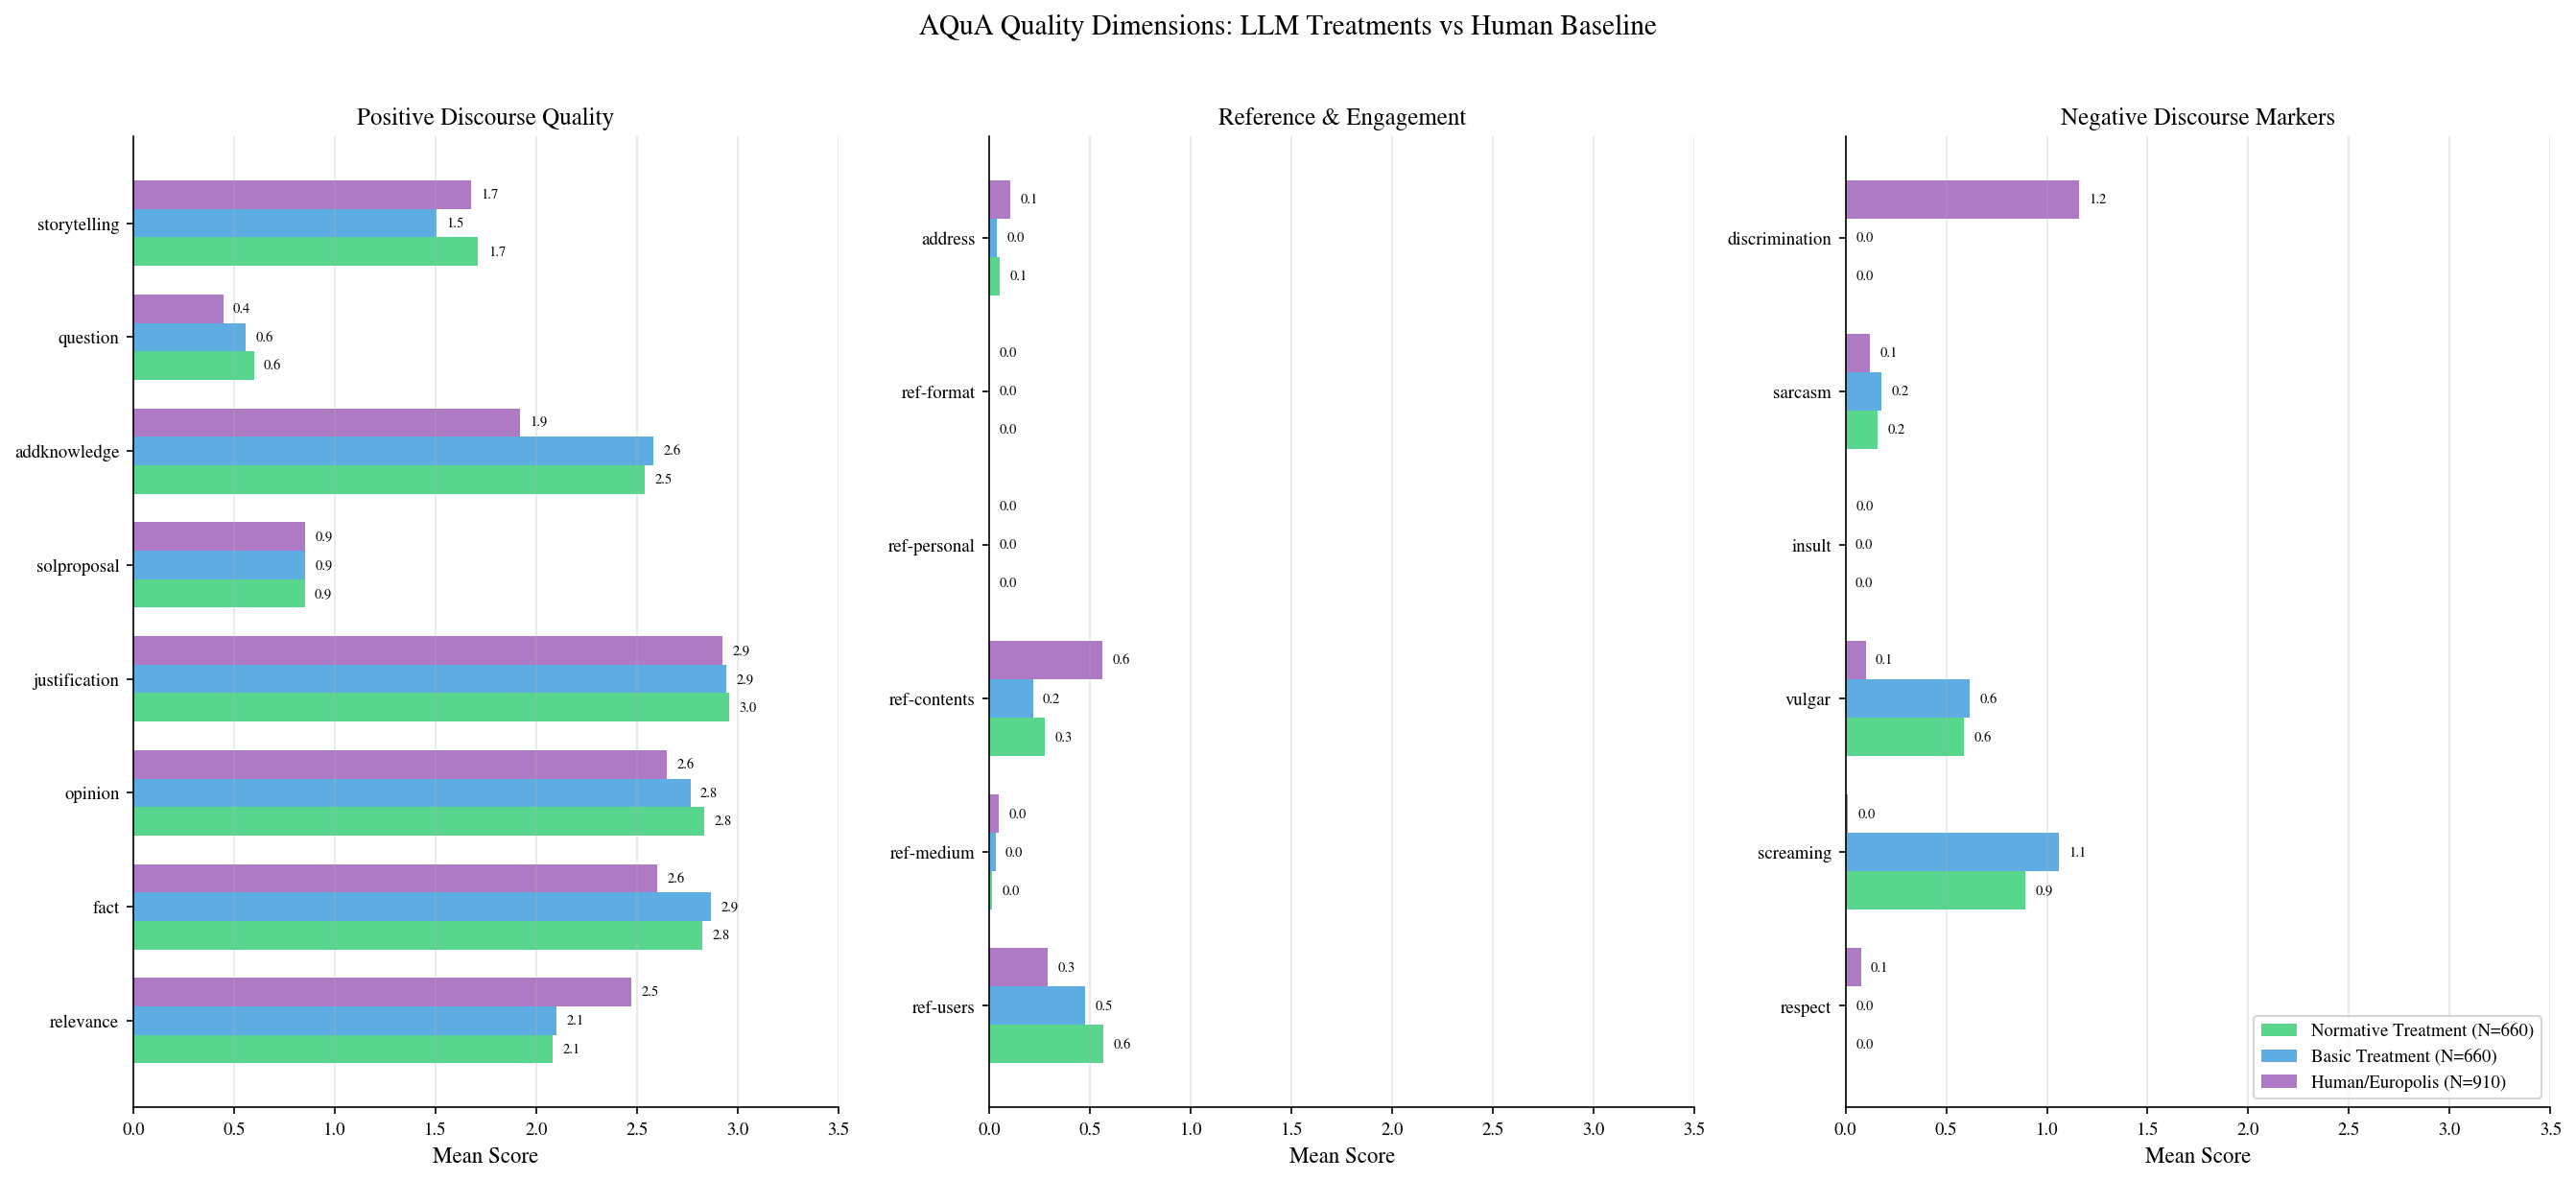

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/aqua_dimensions_comparison.png

AQuA DIMENSION MEANS BY CONDITION (LLM treatments vs Human baseline)
N Normative: 660 | N Basic: 660 | N Human: 910
------------------------------------------------------------------------------------------
                            Category  Normative  Basic  Human  Normative - Human  Basic - Human
relevance                   Positive      2.083  2.100  2.471             -0.388         -0.371
fact                        Positive      2.825  2.867  2.599              0.226          0.268
opinion                     Positive      2.834  2.765  2.647              0.187          0.117
justification               Positive      2.957  2.942  2.923              0.034          0.019
solproposal                 Positive      0.850  0.851  0.854             -0.003         -0.003
addknowledge                Positive      2.540  2.583  1.919              0.622          0.665
question         

In [94]:
# Figure AQuA Quality Dimensions - Comparison by Condition and Human Baseline
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

# Dimension categories
positive_dims = ['relevance', 'fact', 'opinion', 'justification', 
                 'solproposal', 'addknowledge', 'question', 'storytelling']
reference_dims = ['refusers', 'refmedium', 'refcontents', 
                  'refpersonal', 'refformat', 'address']
negative_dims = ['respect', 'screaming', 'vulgar', 'insult', 'sarcasm', 'discrimination']

# Split FSMT data by condition
aqua_treatment_norm = aqua_valid[aqua_valid['condition_label'] == 'Normative Treatment']
aqua_treatment_basic = aqua_valid[aqua_valid['condition_label'] == 'Basic Treatment']

# Colors for each dataset
colors = {
    'Normative Treatment': '#2ecc71',  # Green
    'Basic Treatment': '#3498db',       # Blue
    'Human (Europolis)': '#9b59b6'      # Purple
}

def get_means_for_dims(dims, data, prefix='dim_', suffix=''):
    """Get means for dimensions with flexible column naming"""
    means = []
    for d in dims:
        col = f'{prefix}{d}{suffix}'
        if col in data.columns:
            means.append(data[col].mean())
        else:
            means.append(np.nan)
    return means

def plot_grouped_bars(ax, dims, title):
    """Plot grouped horizontal bars for all three datasets"""
    y_pos = np.arange(len(dims))
    bar_height = 0.25
    
    # Get means for each dataset
    means_norm = get_means_for_dims(dims, aqua_treatment_norm, prefix='dim_')
    means_basic = get_means_for_dims(dims, aqua_treatment_basic, prefix='dim_')
    means_euro = get_means_for_dims(dims, europolis_df, prefix='', suffix='_ad')
    
    # Plot bars
    bars1 = ax.barh(y_pos - bar_height, means_norm, bar_height, 
                    label=f'Normative Treatment (N={len(aqua_treatment_norm)})',
                    color=colors['Normative Treatment'], alpha=0.8)
    bars2 = ax.barh(y_pos, means_basic, bar_height,
                    label=f'Basic Treatment (N={len(aqua_treatment_basic)})',
                    color=colors['Basic Treatment'], alpha=0.8)
    bars3 = ax.barh(y_pos + bar_height, means_euro, bar_height,
                    label=f'Human/Europolis (N={len(europolis_df)})',
                    color=colors['Human (Europolis)'], alpha=0.8)
    
    # Formatting
    ax.set_yticks(y_pos)
    ax.set_yticklabels([d.replace('ref', 'ref-') for d in dims])
    ax.set_xlabel('Mean Score')
    ax.set_title(title, fontsize=12)
    ax.set_xlim(0, 3.5)
    ax.grid(True, alpha=0.3, axis='x')
    
    # Add value labels
    for bars, means in [(bars1, means_norm), (bars2, means_basic), (bars3, means_euro)]:
        for bar, m in zip(bars, means):
            if not np.isnan(m):
                ax.text(m + 0.05, bar.get_y() + bar.get_height()/2, 
                       f'{m:.1f}', va='center', fontsize=7)

# Plot each category
plot_grouped_bars(axes[0], positive_dims, 'Positive Discourse Quality')
plot_grouped_bars(axes[1], reference_dims, 'Reference & Engagement')
plot_grouped_bars(axes[2], negative_dims, 'Negative Discourse Markers')

# Add legend to the first subplot
axes[2].legend(loc='lower right', fontsize=9)

plt.suptitle('AQuA Quality Dimensions: LLM Treatments vs Human Baseline', 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'aqua_dimensions_comparison.pdf', format='pdf')
plt.savefig(FIGURES_DIR / 'aqua_dimensions_comparison.png', format='png')
plt.show()
print(f"Saved: {FIGURES_DIR / 'aqua_dimensions_comparison.png'}")

# ---- Printed table: means by dimension and condition ----

all_dims = positive_dims + reference_dims + negative_dims

def means_series(dims, data, prefix='dim_', suffix=''):
    out = {}
    for d in dims:
        col = f"{prefix}{d}{suffix}"
        out[d] = data[col].mean() if col in data.columns else np.nan
    return pd.Series(out, name="mean")

# Compute mean vectors
norm_means  = means_series(all_dims, aqua_treatment_norm,  prefix="dim_")
basic_means = means_series(all_dims, aqua_treatment_basic, prefix="dim_")
human_means = means_series(all_dims, europolis_df,         prefix="", suffix="_ad")

# Build table
aqua_dim_tbl = pd.concat(
    [
        norm_means.rename("Normative"),
        basic_means.rename("Basic"),
        human_means.rename("Human"),
    ],
    axis=1,
)

# Optional deltas vs human (handy for interpretation)
aqua_dim_tbl["Normative - Human"] = aqua_dim_tbl["Normative"] - aqua_dim_tbl["Human"]
aqua_dim_tbl["Basic - Human"]     = aqua_dim_tbl["Basic"] - aqua_dim_tbl["Human"]

# Add category column + pretty ordering
def dim_category(d):
    if d in positive_dims: return "Positive"
    if d in reference_dims: return "Reference/Engagement"
    if d in negative_dims: return "Negative"
    return "Other"

aqua_dim_tbl.insert(0, "Category", [dim_category(d) for d in aqua_dim_tbl.index])

# Round for printing (keep full precision in the underlying df if needed)
print("\n" + "="*90)
print("AQuA DIMENSION MEANS BY CONDITION (LLM treatments vs Human baseline)")
print("="*90)
print(f"N Normative: {len(aqua_treatment_norm)} | N Basic: {len(aqua_treatment_basic)} | N Human: {len(europolis_df)}")
print("-"*90)
print(aqua_dim_tbl.round(3).to_string())
print("="*90)

# (Optional) Also save as CSV for paper appendix / reproducibility
out_csv = FIGURES_DIR / "aqua_dimensions_comparison_table.csv"
aqua_dim_tbl.to_csv(out_csv, index=True)
print(f"Saved table: {out_csv}")


---

# 3. DRI - Overall Treatment Effects

## ΔDRI by condition with blocked ModelxTopic-clustered inference

In [16]:
# POOLED (topic×model-blocked) TREATMENT COMPARISONS

# -----------------------------
# Helpers
# -----------------------------
def infer_topic_col(df: pd.DataFrame) -> str:
    topic_col = next((c for c in TOPIC_COL_CANDIDATES if c in df.columns), None)
    if topic_col is None:
        raise ValueError(
            f"No topic column found. Expected one of {TOPIC_COL_CANDIDATES}. "
            f"Available columns: {list(df.columns)}"
        )
    return topic_col


def _prep_subdf(df, outcome, cond_a, cond_b, topic_col):
    sub = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    sub = sub.dropna(subset=[outcome, COND_COL, MODEL_COL, topic_col])
    sub = sub[np.isfinite(sub[outcome].to_numpy())]
    return sub


def pooled_block_ate(df, outcome, cond_a, cond_b, topic_col):
    """
    Point estimate: average over topic×model blocks of (mean_a - mean_b).
    Returns:
      ate: float
      block_deltas: Series indexed by (topic, model)
    """
    sub = _prep_subdf(df, outcome, cond_a, cond_b, topic_col)

    means = (
        sub.groupby([topic_col, MODEL_COL, COND_COL])[outcome]
        .mean()
        .unstack(COND_COL)
    )
    means = means.dropna(subset=[cond_a, cond_b])  # keep only complete blocks

    block_deltas = means[cond_a] - means[cond_b]
    ate = block_deltas.mean()  # equal weight per (topic, model) block
    return ate, block_deltas


def topicxmodel_bootstrap_ci(block_deltas, B=BOOT_B, seed=RNG_SEED):
    """
    Topic×model block-resampled (cluster) bootstrap CI for pooled ATE:
    - Resample (topic, model) blocks with replacement
    - For each resample, take the mean of the sampled block deltas
    """
    rng = np.random.default_rng(seed)

    vals = block_deltas.to_numpy()
    n = vals.shape[0]
    if n == 0:
        return np.nan, np.nan, np.array([np.nan])

    boot_stats = np.empty(B, dtype=float)
    for b in range(B):
        samp = rng.choice(vals, size=n, replace=True)
        boot_stats[b] = np.nanmean(samp)

    ci_low, ci_high = np.nanpercentile(boot_stats, [2.5, 97.5])
    return ci_low, ci_high, boot_stats


def blocked_permutation_pvalue(df, outcome, cond_a, cond_b, topic_col, B=PERM_B, seed=RNG_SEED):
    """
    Blocked permutation test:
    within each (topic, model) block, permute treatment labels while preserving
    the original group sizes. Compute pooled ATE (equal weight per block).
    """
    rng = np.random.default_rng(seed)
    sub = _prep_subdf(df, outcome, cond_a, cond_b, topic_col)

    obs, _ = pooled_block_ate(sub, outcome, cond_a, cond_b, topic_col)

    blocks = []
    for (t, m), g in sub.groupby([topic_col, MODEL_COL]):
        ya = g.loc[g[COND_COL] == cond_a, outcome].to_numpy()
        yb = g.loc[g[COND_COL] == cond_b, outcome].to_numpy()
        if len(ya) == 0 or len(yb) == 0:
            continue
        y = np.concatenate([ya, yb])
        n_a = len(ya)
        blocks.append((y, n_a))

    if len(blocks) == 0:
        return np.nan, obs

    perm_stats = np.empty(B, dtype=float)
    for b in range(B):
        deltas = []
        for y, n_a in blocks:
            n = len(y)
            idx_a = rng.choice(n, size=n_a, replace=False)
            mask = np.zeros(n, dtype=bool)
            mask[idx_a] = True
            mean_a = y[mask].mean()
            mean_b = y[~mask].mean()
            deltas.append(mean_a - mean_b)
        perm_stats[b] = np.mean(deltas)

    p = (np.sum(np.abs(perm_stats) >= np.abs(obs)) + 1) / (B + 1)  # two-sided
    return p, obs


def pooled_comparison(df, outcome, name, cond_a, cond_b, topic_col,
                      perm_B=PERM_B, boot_B=BOOT_B, seed=RNG_SEED):
    ate, block_deltas = pooled_block_ate(df, outcome, cond_a, cond_b, topic_col)

    ci_low, ci_high, _ = topicxmodel_bootstrap_ci(
        block_deltas, B=boot_B, seed=RNG_SEED + 1
    )

    p_perm, obs = blocked_permutation_pvalue(
        df, outcome, cond_a, cond_b, topic_col, B=perm_B, seed=RNG_SEED + 2
    )

    # Diagnostic: topic-level aggregation (df = #topics-1)
    topic_deltas = block_deltas.groupby(level=0).mean()
    t_stat, p_topic = stats.ttest_1samp(topic_deltas.to_numpy(), 0.0, nan_policy="omit")

    return {
        "contrast": name,
        "outcome": outcome,
        "ATE_block_mean": ate,
        "CI95_block_boot_low": ci_low,
        "CI95_block_boot_high": ci_high,
        "p_perm_blocked": p_perm,
        "t_topic_level": t_stat,
        "p_topic_level": p_topic,
        "n_topics": int(topic_deltas.shape[0]),
        "n_blocks_topicxmodel": int(block_deltas.shape[0]),
    }


# -----------------------------
# Run pooled, blocked comparisons
# -----------------------------
topic_col = infer_topic_col(llm_df)

OUTCOMES = ["delta_dri"]


all_rows = []
for outcome in OUTCOMES:
    for cname, ca, cb in PAIRWISE:
        row = pooled_comparison(
            llm_df, outcome, cname, ca, cb, topic_col,
            perm_B=PERM_B, boot_B=BOOT_B, seed=RNG_SEED
        )
        all_rows.append(row)

pooled_results = pd.DataFrame(all_rows)

# Holm correction over the 3 pairwise tests PER OUTCOME (using permutation p-values)
pooled_results["p_perm_holm"] = np.nan
for outcome in pooled_results["outcome"].unique():
    mask = pooled_results["outcome"] == outcome
    pvals = pooled_results.loc[mask, "p_perm_blocked"].to_numpy()
    _, p_adj, _, _ = multipletests(pvals, method="holm")
    pooled_results.loc[mask, "p_perm_holm"] = p_adj

display_cols = [
    "outcome", "contrast",
    "ATE_block_mean", "CI95_block_boot_low", "CI95_block_boot_high",
    "p_perm_blocked", "p_perm_holm",
    "n_topics", "n_blocks_topicxmodel",
]

print("\nPOOLED (topic×model-blocked) TREATMENT COMPARISONS")
print("Point estimate = mean over topic×model blocks of within-block mean differences.")
print("p-value = blocked permutation within each topic×model block (preserving 5 vs 5).")
print("CI = topic×model block bootstrap (resample blocks with replacement; equal-weight blocks).")
print(pooled_results[display_cols].to_string(index=False))



POOLED (topic×model-blocked) TREATMENT COMPARISONS
Point estimate = mean over topic×model blocks of within-block mean differences.
p-value = blocked permutation within each topic×model block (preserving 5 vs 5).
CI = topic×model block bootstrap (resample blocks with replacement; equal-weight blocks).
  outcome                     contrast  ATE_block_mean  CI95_block_boot_low  CI95_block_boot_high  p_perm_blocked  p_perm_holm  n_topics  n_blocks_topicxmodel
delta_dri    Normative vs No Treatment        0.028957             0.003415              0.056842        0.004860     0.014580        12                   132
delta_dri        Basic vs No Treatment        0.018715            -0.006990              0.046429        0.079138     0.158277        12                   132
delta_dri Normative vs Basic Treatment        0.010242            -0.008286              0.029857        0.349313     0.349313        12                   132


## Hierarchical Mixed Model on all runs

In [18]:
# Hierarchical (mixed) model on ALL runs + parametric bootstrap CI
#
# Target:
#   - Fixed effects: Basic vs Control, Normative vs Control
#   - Random effects:
#       * (1 + treat_basic + treat_norm) by model  (random slopes by model)
#       * random intercept by topic

# -----------------------------
# Helpers: prepare design
# -----------------------------
def prep_llm_design(
    df: pd.DataFrame,
    outcome: str,
    topic_col: str = "topic",
    model_col: str = "model_label",
    cond_col: str = "condition_label",
    control_name: str = "No Treatment",
    basic_name: str = "Basic Treatment",
    normative_name: str = "Normative Treatment",
) -> pd.DataFrame:
    d = df[[outcome, topic_col, model_col, cond_col]].copy()
    d = d.dropna()
    d = d[np.isfinite(d[outcome].to_numpy())].copy()

    # Binary indicators vs control
    d["treat_basic"] = (d[cond_col] == basic_name).astype(int)
    d["treat_norm"]  = (d[cond_col] == normative_name).astype(int)

    # Keep only the 3 conditions of interest (drop any extra controls if present)
    keep = d[cond_col].isin([control_name, basic_name, normative_name])
    d = d.loc[keep].copy()

    return d


# -----------------------------
# (1) Frequentist mixed model (statsmodels MixedLM)
#     Random slopes by model; topic random intercept via vc_formula
# -----------------------------
def fit_mixedlm_allruns(
    df: pd.DataFrame,
    outcome: str,
    topic_col: str = "topic",
    model_col: str = "model_label",
    cond_col: str = "condition_label",
    control_name: str = "No Treatment",
    basic_name: str = "Basic Treatment",
    normative_name: str = "Normative Treatment",
    reml: bool = True,
):
    d = prep_llm_design(
        df, outcome,
        topic_col=topic_col, model_col=model_col, cond_col=cond_col,
        control_name=control_name, basic_name=basic_name, normative_name=normative_name
    )

    # MixedLM limitation: random slopes only for the "groups" factor.
    # We choose groups=model so we can estimate (1 + treat_basic + treat_norm | model).
    # We add topic as a *variance component* (random intercept) using vc_formula.
    md = smf.mixedlm(
        f"{outcome} ~ treat_basic + treat_norm",
        d,
        groups=d[model_col],
        re_formula="1 + treat_basic + treat_norm",
        vc_formula={ "topic": f"0 + C({topic_col})" },
    )

    res = md.fit(reml=reml, method="lbfgs", maxiter=500, disp=False)
    return res, d


# -----------------------------
# (2) Parametric bootstrap CI for fixed treatment effects
#     Simulate from fitted model, refit, collect fixed effects.
## -----------------------------
def parametric_bootstrap_fixed_effects(
    res,
    d: pd.DataFrame,
    outcome: str,
    topic_col: str = "topic",
    model_col: str = "model_label",
    B: int = BOOT_B_PARAM,
    seed: int = RNG_SEED,
):
    rng = np.random.default_rng(seed)

    # Fixed effect design matrix used by the fitted model
    X = res.model.exog
    beta_hat = res.fe_params.to_numpy()  
    fe_names = list(res.fe_params.index)

    # Random effects for groups=model: multivariate normal with cov_re
    cov_re = np.asarray(res.cov_re)  # shape (k_re, k_re), k_re=3 (intercept,basic,norm)
    k_re = cov_re.shape[0]

    # Topic variance component (random intercept by topic)
    vcomp = np.asarray(res.vcomp)
    var_topic = float(vcomp[0]) if vcomp.size > 0 else 0.0

    # Residual (observation-level) SD
    sigma = float(np.sqrt(res.scale))

    # Precompute index mappings
    model_ids = pd.Index(d[model_col].astype(str).unique())
    topic_ids = pd.Index(d[topic_col].astype(str).unique())

    model_index = d[model_col].astype(str).map({m: i for i, m in enumerate(model_ids)}).to_numpy()
    topic_index = d[topic_col].astype(str).map({t: i for i, t in enumerate(topic_ids)}).to_numpy()

    # Random-effects design matrix Z for model-level RE:
    Z = res.model.exog_re

    # Storage
    boot_betas = []
    n_fail = 0

    # Refit model object template (re-use the same formula structure)
    def _refit(sim_y):
        d_sim = d.copy()
        d_sim[outcome] = sim_y
        md_sim = smf.mixedlm(
            f"{outcome} ~ treat_basic + treat_norm",
            d_sim,
            groups=d_sim[model_col],
            re_formula="1 + treat_basic + treat_norm",
            vc_formula={ "topic": f"0 + C({topic_col})" },
        )
        return md_sim.fit(reml=True, method="lbfgs", maxiter=300, disp=False)

    for b in range(B):
        # Draw random effects
        # Model-level RE: one MVN draw per model
        u_model = rng.multivariate_normal(mean=np.zeros(k_re), cov=cov_re, size=len(model_ids))
        # Topic intercepts
        u_topic = rng.normal(loc=0.0, scale=np.sqrt(max(var_topic, 0.0)), size=len(topic_ids))
        # Residuals
        eps = rng.normal(loc=0.0, scale=sigma, size=len(d))

        # Linear predictor
        mu = X @ beta_hat + np.sum(Z * u_model[model_index, :], axis=1) + u_topic[topic_index]
        y_sim = mu + eps

        # Refit and store FE
        try:
            res_b = _refit(y_sim)
            boot_betas.append(res_b.fe_params.to_numpy())
        except Exception:
            n_fail += 1
            continue

    boot_betas = np.asarray(boot_betas)
    out = {"B": B, "n_ok": boot_betas.shape[0], "n_fail": n_fail, "fe_names": fe_names}

    if boot_betas.shape[0] == 0:
        out.update({"ci": None, "boot_betas": boot_betas})
        return out

    # Percentile CIs for each fixed effect
    ci = {}
    for j, name in enumerate(fe_names):
        lo, hi = np.percentile(boot_betas[:, j], [2.5, 97.5])
        ci[name] = {"ci95_low": float(lo), "ci95_high": float(hi), "boot_mean": float(boot_betas[:, j].mean())}

    out.update({"ci": ci, "boot_betas": boot_betas})
    return out


OUTCOME = "delta_dri"

# (A) Frequentist mixed model
res, d_used = fit_mixedlm_allruns(
    llm_df, OUTCOME,
    topic_col="topic",
    model_col="model_label",
    cond_col="condition_label",
    control_name="No Treatment",
    basic_name="Basic Treatment",
    normative_name="Normative Treatment",
    reml=True
)
print(res.summary())

# Parametric bootstrap CIs for the fixed treatment effects
boot = parametric_bootstrap_fixed_effects(
    res, d_used, OUTCOME,
    topic_col="topic",
    model_col="model_label",
    B=BOOT_B_PARAM, 
    seed=RNG_SEED
)

print("\nParametric bootstrap results:")
print("B =", boot["B"], "n_ok =", boot["n_ok"], "n_fail =", boot["n_fail"])
for name, info in boot["ci"].items():
    if name in ["treat_basic", "treat_norm"]:  # the treatment effects
        print(f"  {name}: boot_mean={info['boot_mean']:.6f}, CI95=[{info['ci95_low']:.6f}, {info['ci95_high']:.6f}]")



                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      delta_dri
No. Observations:      1980         Method:                  REML     
No. Groups:            11           Scale:                   0.0376   
Min. group size:       180          Log-Likelihood:          312.3402 
Max. group size:       180          Converged:               Yes      
Mean group size:       180.0                                          
----------------------------------------------------------------------
                             Coef.  Std.Err.   z   P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                     0.002    0.012 0.176 0.860 -0.022  0.026
treat_basic                   0.019    0.015 1.285 0.199 -0.010  0.047
treat_norm                    0.029    0.013 2.305 0.021  0.004  0.054
Group Var                     0.000    0.003                          
Group x treat_basic Cov

---

# 4. Heterogeneity Analyses

## Model-Level

### Overall Treatment Effects

In [ ]:
# Helpers
def prepare_filtered_df(df: pd.DataFrame, outcome_col: str, cond_a: str, cond_b: str, topic_col: str) -> pd.DataFrame:
    sub = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    sub = sub.dropna(subset=[MODEL_COL, COND_COL, topic_col, outcome_col])
    sub = sub[np.isfinite(sub[outcome_col].to_numpy())]
    return sub

def print_balance_diagnostics(df: pd.DataFrame, outcome_col: str, cond_a: str, cond_b: str, topic_col: str):
    counts = df.groupby([MODEL_COL, topic_col, COND_COL]).size().reset_index(name="n")
    piv = counts.pivot_table(index=[MODEL_COL, topic_col], columns=COND_COL, values="n", fill_value=0)

    # ensure both columns exist for diagnostics
    for col in [cond_a, cond_b]:
        if col not in piv.columns:
            piv[col] = 0

    missing_mask = (piv[[cond_a, cond_b]] == 0).any(axis=1)
    unique_counts = sorted(counts["n"].unique().tolist())

    print(
        f"Diagnostics ({outcome_col}): topics={df[topic_col].nunique()}, models={df[MODEL_COL].nunique()}, "
        f"unique runs per topic×condition={unique_counts}"
    )
    if missing_mask.any():
        print(f"Warning: {missing_mask.sum()} model×topic cells missing a condition; "
              f"topic deltas for those cells are dropped.")
    else:
        print("All model×topic cells have both conditions present after filtering.")

def compute_model_topic_effects(df: pd.DataFrame, outcome_col: str, cond_a: str, cond_b: str, topic_col: str,
                                boot_B: int = 10_000, seed: int = 0) -> pd.DataFrame:
    """
    For each model:
      - compute topic-level deltas: mean(cond_a) - mean(cond_b) within each topic
      - summarize across topics: mean, median, sd, %topics positive
      - CI via topic-resampled bootstrap on those topic deltas
    """
    rng = np.random.default_rng(seed)
    results = []

    for model in sorted(df[MODEL_COL].unique()):
        mdf = df[df[MODEL_COL] == model]

        # topic × condition means
        means = (
            mdf.groupby([topic_col, COND_COL])[outcome_col]
            .mean()
            .unstack(COND_COL)
        )

        # require both conditions in a topic for a delta
        if cond_a not in means.columns:
            means[cond_a] = np.nan
        if cond_b not in means.columns:
            means[cond_b] = np.nan

        deltas = (means[cond_a] - means[cond_b]).dropna()
        delta_arr = deltas.to_numpy()
        n_topics = delta_arr.size

        # run-level means for context (not used for inference)
        mean_a_run = mdf.loc[mdf[COND_COL] == cond_a, outcome_col].mean()
        mean_b_run = mdf.loc[mdf[COND_COL] == cond_b, outcome_col].mean()

        if n_topics == 0:
            results.append({
                "Model": model,
                "Mean_A_run": mean_a_run,
                "Mean_B_run": mean_b_run,
                "mean_diff_topic": np.nan,
                "CI_low": np.nan,
                "CI_high": np.nan,
                "median_diff_topic": np.nan,
                "sd_diff_topic": np.nan,
                "pct_topics_pos": np.nan,
                "N_topics": 0,
            })
            continue

        mean_diff = float(delta_arr.mean())
        median_diff = float(np.median(delta_arr))
        sd_diff = float(np.std(delta_arr, ddof=1)) if n_topics > 1 else np.nan
        pct_pos = float(np.mean(delta_arr > 0.0))

        # topic bootstrap CI (resample topic deltas)
        boot = rng.choice(delta_arr, size=(boot_B, n_topics), replace=True).mean(axis=1)
        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

        results.append({
            "Model": model,
            "Mean_A_run": mean_a_run,
            "Mean_B_run": mean_b_run,
            "mean_diff_topic": mean_diff,
            "CI_low": float(ci_low),
            "CI_high": float(ci_high),
            "median_diff_topic": median_diff,
            "sd_diff_topic": sd_diff,
            "pct_topics_pos": pct_pos,
            "N_topics": int(n_topics),
        })

    res_df = pd.DataFrame(results).sort_values("mean_diff_topic", ascending=False)
    return res_df

In [61]:
# Model-level treatment effects with topic-aware uncertainty (absolute ΔDRI)

print("=" * 92)
print("Model-Level Treatment Effects (Topic-averaged; bootstrap CIs; + Holm)")
print("mean_diff = average over topics of within-topic mean differences (A - B) for each model.")
print(f"CI = topic-resampled bootstrap over topic-level deltas (B={BOOT_B}).")
print("Tests = one-sample t-test over topic deltas per model; Holm correction across models (per contrast).")
print("=" * 92)

OUTCOME_COL = "delta_dri"

# -----------------------------
# Helpers (new)
# -----------------------------
def add_model_holm_significance(
    sub: pd.DataFrame,
    model_res: pd.DataFrame,
    outcome_col: str,
    cond_a: str,
    cond_b: str,
    topic_col: str,
) -> pd.DataFrame:
    """
    Adds:
      - p_model_raw: one-sample t-test over topic deltas per model
      - p_model_holm: Holm-adjusted p across models
      - sig_model_holm: boolean rejection at alpha=0.05
      - sig_topic: alias for plotting style if you want (optional)
    """
    out = model_res.copy()

    p_raw = []
    n_used = []

    for model in out["Model"].tolist():
        mdf = sub[sub[MODEL_COL] == model]

        means = (
            mdf.groupby([topic_col, COND_COL])[outcome_col]
            .mean()
            .unstack(COND_COL)
        )
        if cond_a not in means.columns:
            means[cond_a] = np.nan
        if cond_b not in means.columns:
            means[cond_b] = np.nan

        deltas = (means[cond_a] - means[cond_b]).dropna().to_numpy()
        deltas = deltas[np.isfinite(deltas)]
        n = int(deltas.size)
        n_used.append(n)

        # Need >=2 topics and some variance for a t-test
        if n >= 2 and np.std(deltas, ddof=1) > 0:
            p = float(stats.ttest_1samp(deltas, popmean=0.0, alternative="two-sided").pvalue)
        else:
            p = np.nan
        p_raw.append(p)

    out["N_topics_test"] = n_used
    out["p_model_raw"] = p_raw

    mask = pd.notnull(out["p_model_raw"])
    out["p_model_holm"] = np.nan
    out["sig_model_holm"] = False

    if mask.any():
        rej, p_holm, _, _ = multipletests(out.loc[mask, "p_model_raw"].to_numpy(), alpha=0.05, method="holm")
        out.loc[mask, "p_model_holm"] = p_holm
        out.loc[mask, "sig_model_holm"] = rej

    return out


# -----------------------------
# Run table(s)
# -----------------------------
topic_col = infer_topic_col(llm_df)

for title, cond_a, cond_b in PAIRWISE:
    print("\n" + "=" * 92)
    print(f"TABLE 4 ({title}): Model-Level Effects on {OUTCOME_COL}")
    print(f"Conditions: A='{cond_a}' vs B='{cond_b}'")
    print("=" * 92)

    sub = prepare_filtered_df(llm_df, OUTCOME_COL, cond_a, cond_b, topic_col)
    print_balance_diagnostics(sub, OUTCOME_COL, cond_a, cond_b, topic_col)

    model_res = compute_model_topic_effects(
        sub, OUTCOME_COL, cond_a, cond_b, topic_col,
        boot_B=BOOT_B, seed=RNG_SEED
    )

    # ---- add Holm-corrected significance across models ----
    model_res = add_model_holm_significance(sub, model_res, OUTCOME_COL, cond_a, cond_b, topic_col)

    # Print main table (now with p-values + Holm)
    print(
        f"\n{'Model':<18} {'mean_diff':<10} {'CI_low':<9} {'CI_high':<9} "
        f"{'median':<10} {'sd':<9} {'%topics>0':<11} {'N_topics':<8} "
        f"{'p_raw':<10} {'p_holm':<10} {'sig':<4}"
    )
    print("-" * 92)
    for _, row in model_res.iterrows():
        pct = row["pct_topics_pos"]
        pct_str = f"{pct*100:>7.1f}%" if pd.notnull(pct) else "   nan  "
        sig_str = "yes" if bool(row["sig_model_holm"]) else "no"
        print(
            f"{row['Model']:<18} {fmt_or_nan(row['mean_diff_topic']):<10} "
            f"{fmt_or_nan(row['CI_low']):<9} {fmt_or_nan(row['CI_high']):<9} "
            f"{fmt_or_nan(row['median_diff_topic']):<10} {fmt_or_nan(row['sd_diff_topic']):<9} "
            f"{pct_str:<11} {int(row['N_topics']):<8} "
            f"{fmt_or_nan(row['p_model_raw'], digits=4):<10} {fmt_or_nan(row['p_model_holm'], digits=4):<10} {sig_str:<4}"
        )

    print("\nNotes:")
    print("- mean_diff: average over topics of within-topic mean differences (A - B) for this model.")
    print(f"- CI: topic-resampled bootstrap over topic deltas (B={BOOT_B}).")
    print("- p_raw: two-sided one-sample t-test over topic deltas for each model (H0: mean delta = 0).")
    print("- p_holm/sig: Holm correction across models within this contrast (alpha=0.05).")

Model-Level Treatment Effects (Topic-averaged; bootstrap CIs; + Holm)
mean_diff = average over topics of within-topic mean differences (A - B) for each model.
CI = topic-resampled bootstrap over topic-level deltas (B=20000).
Tests = one-sample t-test over topic deltas per model; Holm correction across models (per contrast).

TABLE 4 (Normative vs No Treatment): Model-Level Effects on delta_dri
Conditions: A='Normative Treatment' vs B='No Treatment'
Diagnostics (delta_dri): topics=12, models=11, unique runs per topic×condition=[5]
All model×topic cells have both conditions present after filtering.

Model              mean_diff  CI_low    CI_high   median     sd        %topics>0   N_topics p_raw      p_holm     sig 
--------------------------------------------------------------------------------------------
Mixed-R            0.0825     -0.0106   0.2187    0.0269     0.2204       66.7%    12       0.2212     1.0000     no  
Kimi-K2-NR         0.0791     -0.0126   0.1894    0.0382     0.1

In [68]:
# Model-level PRE and POST DRI (topic-averaged; topic-bootstrap CIs)

print("=" * 92)
print("Model-Level PRE/POST DRI Levels (Topic-averaged; topic-bootstrap CIs)")
print(f"CI = topic-resampled bootstrap over topic-level means (B={BOOT_B}).")
print("=" * 92)

# -----------------------------
# 1) pick pre/post columns robustly
# -----------------------------
def _pick_pre_post_cols(df: pd.DataFrame):
    candidates_pre  = ["pre_dri", "dri_pre", "preDRI", "DRI_pre", "pre"]
    candidates_post = ["post_dri", "dri_post", "postDRI", "DRI_post", "post"]
    pre_col = next((c for c in candidates_pre  if c in df.columns), None)
    post_col = next((c for c in candidates_post if c in df.columns), None)
    if pre_col is None or post_col is None:
        raise ValueError(
            "Could not infer pre/post DRI columns. "
            f"Looked for pre in {candidates_pre} and post in {candidates_post}. "
            f"Available columns: {list(df.columns)}"
        )
    return pre_col, post_col

PRE_COL, POST_COL = _pick_pre_post_cols(llm_df)
topic_col = infer_topic_col(llm_df)

# -----------------------------
# 2) topic-bootstrap helper for a single series of topic means
# -----------------------------
def _topic_boot_ci(topic_means: pd.Series, B: int, seed: int):
    """topic_means: index=topic, values=topic-level mean. Returns (mean, lo, hi)."""
    x = topic_means.dropna().to_numpy()
    n = int(x.size)
    if n == 0:
        return np.nan, np.nan, np.nan, 0
    if n == 1:
        m = float(x[0])
        return m, m, m, 1

    rng = np.random.default_rng(seed)
    boots = np.empty(B, dtype=float)
    for b in range(B):
        idx = rng.integers(0, n, size=n)   # resample topics with replacement
        boots[b] = float(np.mean(x[idx]))
    m = float(np.mean(x))
    lo, hi = np.quantile(boots, [0.025, 0.975])
    return m, float(lo), float(hi), n

# -----------------------------
# 3) compute (Model × Condition) topic-averaged PRE/POST with CIs
# -----------------------------
rows = []

# Use all conditions present (or swap this for a fixed ordered list if you prefer)
conds = sorted([c for c in llm_df[COND_COL].dropna().unique().tolist()])

for model in sorted(llm_df[MODEL_COL].dropna().unique().tolist()):
    for cond in conds:
        mdf = llm_df[(llm_df[MODEL_COL] == model) & (llm_df[COND_COL] == cond)].copy()

        # Topic-level means (equal-weight topics afterwards)
        pre_topic = mdf.groupby(topic_col)[PRE_COL].mean()
        post_topic = mdf.groupby(topic_col)[POST_COL].mean()

        # bootstrap CIs
        pre_m, pre_lo, pre_hi, n_pre = _topic_boot_ci(pre_topic, B=BOOT_B, seed=RNG_SEED + 101)
        post_m, post_lo, post_hi, n_post = _topic_boot_ci(post_topic, B=BOOT_B, seed=RNG_SEED + 202)

        rows.append({
            "Model": model,
            "Condition": cond,
            "pre_mean_topic": pre_m,
            "pre_CI_low": pre_lo,
            "pre_CI_high": pre_hi,
            "post_mean_topic": post_m,
            "post_CI_low": post_lo,
            "post_CI_high": post_hi,
            "N_topics_pre": n_pre,
            "N_topics_post": n_post,
        })

levels_res = pd.DataFrame(rows)

# -----------------------------
# 4) pretty print
# -----------------------------
print(
    f"\n{'Model':<18} {'Condition':<20} "
    f"{'pre_mean':<9} {'pre_lo':<9} {'pre_hi':<9} "
    f"{'post_mean':<9} {'post_lo':<9} {'post_hi':<9} "
    f"{'N_t_pre':<8} {'N_t_post':<8}"
)
print("-" * 92)

for _, r in levels_res.sort_values(["Condition", "Model"]).iterrows():
    print(
        f"{r['Model']:<18} {str(r['Condition']):<20} "
        f"{fmt_or_nan(r['pre_mean_topic']):<9} {fmt_or_nan(r['pre_CI_low']):<9} {fmt_or_nan(r['pre_CI_high']):<9} "
        f"{fmt_or_nan(r['post_mean_topic']):<9} {fmt_or_nan(r['post_CI_low']):<9} {fmt_or_nan(r['post_CI_high']):<9} "
        f"{int(r['N_topics_pre']):<8} {int(r['N_topics_post']):<8}"
    )

print("\nNotes:")
print("- pre/post means are topic-equal-weight averages of within-topic means (per Model×Condition).")
print(f"- CIs are topic-resampled bootstrap over topic-level means (B={BOOT_B}).")
print(f"- Using PRE_COL='{PRE_COL}', POST_COL='{POST_COL}', topic_col='{topic_col}'.")


Model-Level PRE/POST DRI Levels (Topic-averaged; topic-bootstrap CIs)
CI = topic-resampled bootstrap over topic-level means (B=20000).

Model              Condition            pre_mean  pre_lo    pre_hi    post_mean post_lo   post_hi   N_t_pre  N_t_post
--------------------------------------------------------------------------------------------
Claude Opus 4.5    Basic Treatment      0.8002    0.5397    0.9561    0.9086    0.8346    0.9587    12       12      
DeepSeek-NR        Basic Treatment      0.7614    0.6283    0.8738    0.7939    0.6894    0.8687    12       12      
DeepSeek-R         Basic Treatment      0.7373    0.5835    0.8457    0.7634    0.6597    0.8472    12       12      
GPT-5.1-NR         Basic Treatment      0.8692    0.8111    0.9175    0.9167    0.8901    0.9397    12       12      
GPT-5.1-R          Basic Treatment      0.9021    0.8750    0.9265    0.9074    0.8811    0.9301    12       12      
Gemini-3-NR        Basic Treatment      0.8609    0.7900    0.9

findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
find

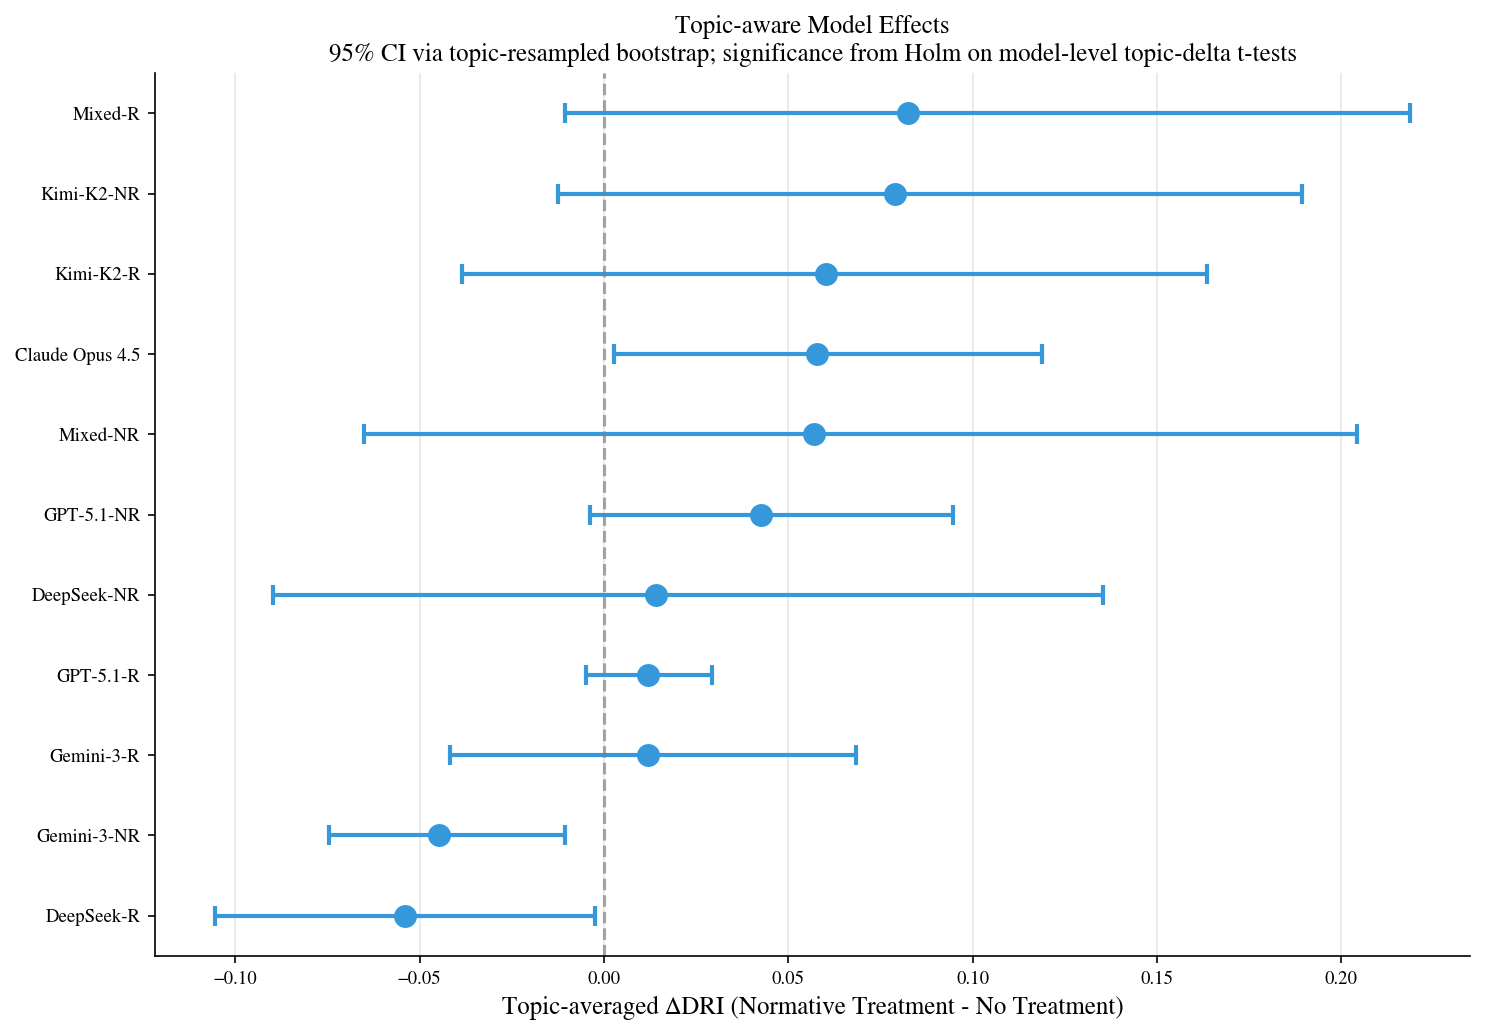

In [93]:
# Figure Topic-aware forest plot of treatment effects (absolute ΔDRI)


model_effects_res = {}

for title, cond_a, cond_b in PAIRWISE:
    sub = prepare_filtered_df(llm_df, OUTCOME_COL, cond_a, cond_b, topic_col)

    model_res = compute_model_topic_effects(
        sub, OUTCOME_COL, cond_a, cond_b, topic_col,
        boot_B=BOOT_B, seed=RNG_SEED
    )

    model_res = add_model_holm_significance(sub, model_res, OUTCOME_COL, cond_a, cond_b, topic_col)

    # store everything you need for plotting
    model_effects_res[title] = {
        "cond_a": cond_a,
        "cond_b": cond_b,
        "table": model_res.copy()
    }

# --- plot explicitly the contrast you want ---
title = "Normative vs No Treatment"
cond_a = model_effects_res[title]["cond_a"]
cond_b = model_effects_res[title]["cond_b"]
plot_df = model_effects_res[title]["table"].copy()

plot_df = plot_df[pd.notnull(plot_df["mean_diff_topic"])].sort_values("mean_diff_topic").reset_index(drop=True)

y_pos = np.arange(len(plot_df))
sig_col = "sig_model_holm"
colors = ["#2ecc71" if bool(x) else "#3498db" for x in plot_df.get(sig_col, [False]*len(plot_df))]

fig, ax = plt.subplots(figsize=(10, 7))
for i, row in plot_df.iterrows():
    m = row["mean_diff_topic"]
    lo = row["CI_low"] if pd.notnull(row["CI_low"]) else m
    hi = row["CI_high"] if pd.notnull(row["CI_high"]) else m
    ax.errorbar(
        m, i,
        xerr=[[m - lo], [hi - m]],
        fmt="o", markersize=10, capsize=5, capthick=2,
        color=colors[i], ecolor=colors[i], linewidth=2
    )

ax.axvline(x=0, color="gray", linestyle="--", linewidth=1.5, alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Model"])
ax.set_xlabel(f"Topic-averaged ΔDRI ({cond_a} - {cond_b})", fontsize=12)
ax.set_title(
    "Topic-aware Model Effects\n"
    "95% CI via topic-resampled bootstrap; significance from Holm on model-level topic-delta t-tests",
    fontsize=12
)
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'model_forest_plot.pdf', format='pdf')
plt.savefig(FIGURES_DIR / 'model_forest_plot.png', format='png')
plt.show()


### Reasoning Effect

In [21]:
# Reasoning vs Non-Reasoning (descriptive, topic-aware) under Normative Treatment
print("=" * 92)
print("Reasoning vs Non-Reasoning (Topic-aware; Normative Treatment only)")
print("Estimand: average over topics of (mean ΔDRI_R - mean ΔDRI_NR) within topic.")
print(f"CI: topic-resampled bootstrap over topic-level differences (B={BOOT_B}).")
print("Descriptive only.")
print("=" * 92)

OUTCOME_COL = "delta_dri"

# New condition naming
NORM_COND = "Normative Treatment"

# Topic column inference
topic_col_candidates = ["topic_label", "topic", "issue", "issue_label"]
topic_col = next((c for c in topic_col_candidates if c in llm_df.columns), None)
if topic_col is None:
    raise ValueError(
        f"No topic column found. Expected one of {topic_col_candidates}. "
        f"Available columns: {list(llm_df.columns)}"
    )

# Identify reasoning vs non-reasoning via suffix
llm_df = llm_df.copy()
llm_df["is_reasoning"] = llm_df[MODEL_COL].str.contains(r"-R$", regex=True)
llm_df["is_non_reasoning"] = llm_df[MODEL_COL].str.contains(r"-NR$", regex=True)

# Model family mapping (keep simple; adjust if you add families)
def get_family(model: str) -> str:
    if "DeepSeek" in model:
        return "DeepSeek"
    if "Gemini" in model:
        return "Gemini-3"
    if "GPT" in model:
        return "GPT-5.1"
    if "Kimi" in model:
        return "Kimi-K2"
    if "Mixed" in model:
        return "Mixed"
    if "Claude" in model:
        return "Claude-4.5"
    return "Other"

llm_df["model_family"] = llm_df[MODEL_COL].apply(get_family)

# Filter to Normative Treatment and clean outcome
df = llm_df[llm_df[COND_COL] == NORM_COND].copy()
df = df.dropna(subset=[OUTCOME_COL, topic_col, MODEL_COL])
df = df[np.isfinite(df[OUTCOME_COL].to_numpy())]

rng = np.random.default_rng(RNG_SEED)

def topic_aware_r_minus_nr(df_sub: pd.DataFrame) -> dict:
    """
    Compute topic-level (R - NR) differences and summarize.
    """
    # Mean per topic within R and NR
    by = df_sub.groupby([topic_col]).apply(
        lambda g: pd.Series({
            "mean_R": g.loc[g["is_reasoning"], OUTCOME_COL].mean(),
            "mean_NR": g.loc[g["is_non_reasoning"], OUTCOME_COL].mean(),
            "n_R": int(g["is_reasoning"].sum()),
            "n_NR": int(g["is_non_reasoning"].sum()),
        })
    )

    # Keep topics where both groups exist (at least 1 obs each)
    mask = (by["n_R"] > 0) & (by["n_NR"] > 0)
    by = by.loc[mask].copy()

    diffs = (by["mean_R"] - by["mean_NR"]).dropna().to_numpy()
    n_topics = diffs.size

    if n_topics == 0:
        return {
            "n_topics": 0,
            "mean_diff": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "pct_topics_pos": np.nan,
            "sd_topics": np.nan,
        }

    mean_diff = float(diffs.mean())
    sd_topics = float(np.std(diffs, ddof=1)) if n_topics > 1 else np.nan
    pct_pos = float(np.mean(diffs > 0.0))

    boot = rng.choice(diffs, size=(BOOT_B, n_topics), replace=True).mean(axis=1)
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    return {
        "n_topics": int(n_topics),
        "mean_diff": mean_diff,
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "pct_topics_pos": pct_pos,
        "sd_topics": sd_topics,
    }

# -----------------------------
# Overall (topic-aware)
# -----------------------------
overall = topic_aware_r_minus_nr(df)
print("\nOverall (across families):")
print(f"  Topics with both R and NR present: {overall['n_topics']}")
print(f"  Mean (R - NR): {overall['mean_diff']:.4f}")
print(f"  95% CI (topic bootstrap): [{overall['ci_low']:.4f}, {overall['ci_high']:.4f}]")
print(f"  %topics where R > NR: {overall['pct_topics_pos']*100:.1f}%"
      if pd.notnull(overall["pct_topics_pos"]) else "  %topics where R > NR: nan")
print(f"  SD of topic diffs: {overall['sd_topics']:.4f}" if pd.notnull(overall["sd_topics"]) else "  SD of topic diffs: nan")

# -----------------------------
# Within-family (topic-aware)
# -----------------------------
print(f"\n{'Family':<14} {'n_topics':<8} {'Mean(R-NR)':<12} {'CI_low':<10} {'CI_high':<10} {'%topics>0':<10}")
print("-" * 72)

family_rows = []
for fam in sorted(df["model_family"].unique()):
    fam_df = df[df["model_family"] == fam]
    stats_f = topic_aware_r_minus_nr(fam_df)
    family_rows.append({"Family": fam, **stats_f})

    pct = stats_f["pct_topics_pos"]
    pct_str = f"{pct*100:>7.1f}%" if pd.notnull(pct) else "   nan  "

    print(f"{fam:<14} {stats_f['n_topics']:<8} "
          f"{stats_f['mean_diff'] if pd.notnull(stats_f['mean_diff']) else np.nan: <12.4f} "
          f"{stats_f['ci_low'] if pd.notnull(stats_f['ci_low']) else np.nan: <10.4f} "
          f"{stats_f['ci_high'] if pd.notnull(stats_f['ci_high']) else np.nan: <10.4f} "
          f"{pct_str:<10}")

reasoning_family_df = pd.DataFrame(family_rows)

# -----------------------------
# Run-level Welch tests (descriptive only)
# -----------------------------
do_welch = True
if do_welch:
    print("\nDescriptive run-level Welch tests (NOT for inference):")
    r_data = df.loc[df["is_reasoning"], OUTCOME_COL].to_numpy()
    nr_data = df.loc[df["is_non_reasoning"], OUTCOME_COL].to_numpy()
    r_data = r_data[np.isfinite(r_data)]
    nr_data = nr_data[np.isfinite(nr_data)]

    if r_data.size >= 2 and nr_data.size >= 2:
        t_stat, p_val = stats.ttest_ind(r_data, nr_data, equal_var=False)
        pooled_std = np.sqrt((np.var(r_data, ddof=1) + np.var(nr_data, ddof=1)) / 2)
        d = (np.mean(r_data) - np.mean(nr_data)) / pooled_std if pooled_std > 0 else np.nan
        print(f"  Reasoning N={r_data.size}, mean={np.mean(r_data):.4f}")
        print(f"  Non-Reasoning N={nr_data.size}, mean={np.mean(nr_data):.4f}")
        print(f"  Diff (R-NR) = {np.mean(r_data)-np.mean(nr_data):.4f}")
        print(f"  Welch t={t_stat:.2f}, p={p_val:.4g}, d={d:.2f}")
    else:
        print("  Insufficient data for Welch test.")


Reasoning vs Non-Reasoning (Topic-aware; Normative Treatment only)
Estimand: average over topics of (mean ΔDRI_R - mean ΔDRI_NR) within topic.
CI: topic-resampled bootstrap over topic-level differences (B=20000).
Descriptive only.

Overall (across families):
  Topics with both R and NR present: 12
  Mean (R - NR): 0.0101
  95% CI (topic bootstrap): [-0.0272, 0.0437]
  %topics where R > NR: 66.7%
  SD of topic diffs: 0.0655

Family         n_topics Mean(R-NR)   CI_low     CI_high    %topics>0 
------------------------------------------------------------------------
Claude-4.5     0        nan          nan        nan           nan    
DeepSeek       12       0.0286       -0.1319    0.1803        75.0%  
GPT-5.1        12       -0.0240      -0.0680    0.0113        50.0%  
Gemini-3       12       0.0183       -0.0180    0.0516        75.0%  
Kimi-K2        12       0.0102       -0.0468    0.0613        66.7%  
Mixed          12       0.0173       -0.0447    0.0821        58.3%  

Descript

findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following f

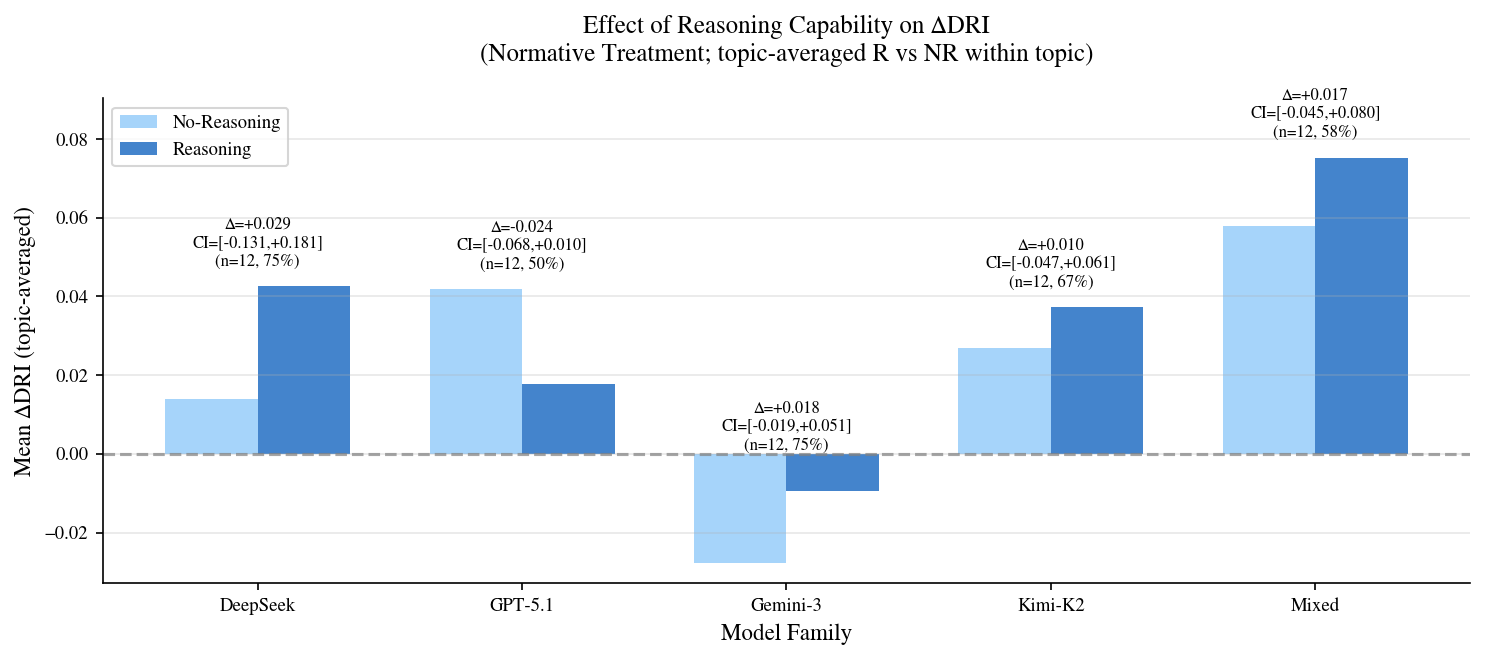

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/reasoning_effect.pdf


In [96]:
# Figure: Reasoning vs Non-Reasoning (topic-aware) — PLOT

rng = np.random.default_rng(RNG_SEED)

def topic_aware_r_nr_bars(df_sub: pd.DataFrame) -> dict:
    """
    Returns the quantities needed for the paired-bar plot (per family):

      - Reasoning:    topic-avg mean_R (over topics where both R & NR exist)
      - No-Reasoning: topic-avg mean_NR (same topics)
      - Δ:            topic-avg (mean_R - mean_NR)
      - CI_low/high:  topic-bootstrap CI over topic-level diffs
      - n_topics:     topics with both groups present
      - pct_topics_pos: share of topics where mean_R > mean_NR
    """
    by = df_sub.groupby([topic_col]).apply(
        lambda g: pd.Series({
            "mean_R": g.loc[g["is_reasoning"], OUTCOME_COL].mean(),
            "mean_NR": g.loc[g["is_non_reasoning"], OUTCOME_COL].mean(),
            "n_R": int(g["is_reasoning"].sum()),
            "n_NR": int(g["is_non_reasoning"].sum()),
        })
    )

    # Keep only topics where both exist
    mask = (by["n_R"] > 0) & (by["n_NR"] > 0)
    by = by.loc[mask].copy()

    if len(by) == 0:
        return {
            "n_topics": 0,
            "Reasoning": np.nan,
            "No-Reasoning": np.nan,
            "Δ": np.nan,
            "CI_low": np.nan,
            "CI_high": np.nan,
            "pct_topics_pos": np.nan,
        }

    # Topic-averaged means
    mean_R = float(by["mean_R"].mean())
    mean_NR = float(by["mean_NR"].mean())

    # Topic-level diffs + bootstrap CI
    diffs = (by["mean_R"] - by["mean_NR"]).to_numpy(dtype=float)
    n_topics = int(diffs.size)

    mean_diff = float(diffs.mean())
    pct_pos = float(np.mean(diffs > 0.0))

    boot = rng.choice(diffs, size=(BOOT_B, n_topics), replace=True).mean(axis=1)
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    return {
        "n_topics": n_topics,
        "Reasoning": mean_R,
        "No-Reasoning": mean_NR,
        "Δ": mean_diff,
        "CI_low": float(ci_low),
        "CI_high": float(ci_high),
        "pct_topics_pos": pct_pos,
    }


# -----------------------------
# Build plot_df FROM YOUR df
# -----------------------------
rows = []
for fam in sorted(df["model_family"].dropna().unique()):
    fam_df = df[df["model_family"] == fam]
    stats_f = topic_aware_r_nr_bars(fam_df)

    # Only keep families with at least 1 topic having both R and NR
    if stats_f["n_topics"] > 0:
        rows.append({"Family": fam, **stats_f})

plot_df = pd.DataFrame(rows).copy()

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(10, 5))

if len(plot_df) == 0:
    ax.text(
        0.5, 0.5,
        "No families with both R and NR present across topics.",
        ha="center", va="center", transform=ax.transAxes
    )
else:
    x = np.arange(len(plot_df))
    width = 0.35

    bars1 = ax.bar(
        x - width/2,
        plot_df["No-Reasoning"].to_numpy(dtype=float),
        width,
        label="No-Reasoning",
        color="#90CAF9",
        alpha=0.8
    )
    bars2 = ax.bar(
        x + width/2,
        plot_df["Reasoning"].to_numpy(dtype=float),
        width,
        label="Reasoning",
        color="#1565C0",
        alpha=0.8
    )

    ax.axhline(y=0, color="gray", linestyle="--", alpha=0.7)

    ax.set_xticks(x)
    ax.set_xticklabels(plot_df["Family"].to_list())
    ax.set_ylabel("Mean ΔDRI (topic-averaged)", fontsize=11)
    ax.set_xlabel("Model Family", fontsize=11)

    ax.set_title(
        "Effect of Reasoning Capability on ΔDRI\n"
        "(Normative Treatment; topic-averaged R vs NR within topic)",
        fontsize=12,
        pad=18,
    )

    ax.legend()
    ax.grid(True, alpha=0.3, axis="y")

    # Annotation positioning
    top_vals = np.nanmax(
        np.vstack([
            plot_df["Reasoning"].to_numpy(dtype=float),
            plot_df["No-Reasoning"].to_numpy(dtype=float)
        ]),
        axis=0
    )

    for i in range(len(plot_df)):
        diff = float(plot_df.loc[i, "Δ"])
        n_topics = int(plot_df.loc[i, "n_topics"])
        pct = float(plot_df.loc[i, "pct_topics_pos"])

        ci_low = float(plot_df.loc[i, "CI_low"])
        ci_high = float(plot_df.loc[i, "CI_high"])

        # If the tallest bar for this family is below 0, push label further up
        offset_pts = 18 if top_vals[i] < 0 else 8

        ax.annotate(
            f"Δ={diff:+.3f}\nCI=[{ci_low:+.3f},{ci_high:+.3f}]\n(n={n_topics}, {pct*100:.0f}%)",
            xy=(i, top_vals[i]),
            xytext=(0, offset_pts),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            clip_on=False
        )

    # Headroom
    y_min, y_max = ax.get_ylim()
    overall_top = float(np.nanmax(top_vals))
    headroom = 0.14 * (overall_top - y_min if overall_top > y_min else 1.0)
    ax.set_ylim(y_min, overall_top + headroom)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(FIGURES_DIR / "reasoning_effect.pdf", format="pdf")
plt.savefig(FIGURES_DIR / "reasoning_effect.png", format="png")
plt.show()

print(f"Saved: {FIGURES_DIR / 'reasoning_effect.pdf'}")


## Topic-Level

In [ ]:
# Topic-Level Treatment Effects

print("=" * 92)
print("TOPIC EFFECTS: Topic-Level Treatment Effects (model-aware; + Holm-corrected tests)")
print("Estimand per topic: average over models of within-(topic×model) mean diffs (A - B).")
print(f"CI: model-resampled bootstrap within topic (B={BOOT_B}).")
print("Tests: per-topic one-sample t-test of model-level deltas vs 0 (H0: mean delta = 0).")
print("Multiple testing: Holm correction across topics within each contrast.")
print("=" * 92)

OUTCOME_COL = "delta_dri"
topic_effects_res = {}

topic_col_candidates = ["topic_label", "topic", "issue", "issue_label"]
topic_col = next((c for c in topic_col_candidates if c in llm_df.columns), None)
if topic_col is None:
    raise ValueError(
        f"No topic column found. Expected one of {topic_col_candidates}. "
        f"Available columns: {list(llm_df.columns)}"
    )

rng = np.random.default_rng(RNG_SEED)

def prep(df, cond_a, cond_b):
    sub = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    sub = sub.dropna(subset=[OUTCOME_COL, COND_COL, MODEL_COL, topic_col])
    sub = sub[np.isfinite(sub[OUTCOME_COL].to_numpy())]
    return sub

def make_key(title, cond_a, cond_b):
    return f"{title} | A={cond_a} vs B={cond_b}"

def topic_effects(sub, cond_a, cond_b):
    """
    For each topic:
      - compute model-level block deltas: mean_A - mean_B within each model
      - aggregate across models: mean, median, sd, %models positive
      - CI: model-resampled bootstrap on model deltas (within topic)
      - p-value: one-sample t-test over model deltas vs 0 (two-sided)
      - Holm correction is applied outside this function (needs all topics)
    """
    rows = []
    for t in sorted(sub[topic_col].unique()):
        tdf = sub[sub[topic_col] == t]

        means = (
            tdf.groupby([MODEL_COL, COND_COL])[OUTCOME_COL]
            .mean()
            .unstack(COND_COL)
        )
        # ensure both condition columns exist
        if cond_a not in means.columns:
            means[cond_a] = np.nan
        if cond_b not in means.columns:
            means[cond_b] = np.nan

        deltas = (means[cond_a] - means[cond_b]).dropna()
        delta_arr = deltas.to_numpy()
        n_models = int(delta_arr.size)

        if n_models == 0:
            rows.append({
                "Topic": t,
                "mean_diff_models": np.nan,
                "CI_low": np.nan,
                "CI_high": np.nan,
                "median_diff_models": np.nan,
                "sd_diff_models": np.nan,
                "pct_models_pos": np.nan,
                "N_models": 0,
                "p_topic_raw": np.nan,
            })
            continue

        mean_diff = float(delta_arr.mean())
        median_diff = float(np.median(delta_arr))
        sd_diff = float(np.std(delta_arr, ddof=1)) if n_models > 1 else np.nan
        pct_pos = float(np.mean(delta_arr > 0.0))

        # bootstrap CI (resample models within topic)
        boot = rng.choice(delta_arr, size=(BOOT_B, n_models), replace=True).mean(axis=1)
        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

        # per-topic t-test across models (needs >=2 models)
        if n_models >= 2 and np.isfinite(sd_diff) and sd_diff > 0:
            p_raw = float(stats.ttest_1samp(delta_arr, popmean=0.0, alternative="two-sided").pvalue)
        else:
            # no variance or only one model -> no meaningful t-test
            p_raw = np.nan

        rows.append({
            "Topic": t,
            "mean_diff_models": mean_diff,
            "CI_low": float(ci_low),
            "CI_high": float(ci_high),
            "median_diff_models": median_diff,
            "sd_diff_models": sd_diff,
            "pct_models_pos": pct_pos,
            "N_models": n_models,
            "p_topic_raw": p_raw,
        })

    return pd.DataFrame(rows)

def fmt_or_nan(val, digits=4):
    return f"{val:.{digits}f}" if pd.notnull(val) else "nan"

def fmt_p(val, digits=4):
    return f"{val:.{digits}g}" if pd.notnull(val) else "nan"

for title, cond_a, cond_b in PAIRWISE:
    print("\n" + "=" * 92)
    print(f"TOPIC EFFECTS ({title})")
    print(f"Conditions: A='{cond_a}' vs B='{cond_b}'")
    print("=" * 92)

    sub = prep(llm_df, cond_a, cond_b)
    res = topic_effects(sub, cond_a, cond_b)

    # ---------- Holm correction across topics (within this contrast) ----------
    mask = pd.notnull(res["p_topic_raw"])
    if mask.any():
        rej, p_holm, _, _ = multipletests(res.loc[mask, "p_topic_raw"].to_numpy(), alpha=0.05, method="holm")
        res.loc[mask, "p_topic_holm"] = p_holm
        res.loc[mask, "sig_topic_holm"] = rej
    else:
        res["p_topic_holm"] = np.nan
        res["sig_topic_holm"] = False

    # convenience flag for plotting (and for earlier plotting code)
    res["sig_topic"] = res["sig_topic_holm"].fillna(False).astype(bool)

    # sort for printing (largest effects on top)
    res_print = res.sort_values("mean_diff_models", ascending=False).reset_index(drop=True)

    # store (copy to avoid accidental mutation later)
    key = make_key(title, cond_a, cond_b)
    topic_effects_res[key] = res_print.copy()

    # --------- PRINT ----------
    print(
        f"\n{'Topic':<22} {'mean_diff':<10} {'CI_low':<9} {'CI_high':<9} "
        f"{'median':<10} {'sd':<9} {'%models>0':<11} {'N':<4} "
        f"{'p_raw':<10} {'p_holm':<10} {'sig':<4}"
    )
    print("-" * 92)
    for _, row in res_print.iterrows():
        pct = row["pct_models_pos"]
        pct_str = f"{pct*100:>7.1f}%" if pd.notnull(pct) else "   nan  "
        sig = row["sig_topic_holm"]
        sig_str = "yes" if bool(sig) else "no"
        print(
            f"{str(row['Topic']):<22} {fmt_or_nan(row['mean_diff_models']):<10} "
            f"{fmt_or_nan(row['CI_low']):<9} {fmt_or_nan(row['CI_high']):<9} "
            f"{fmt_or_nan(row['median_diff_models']):<10} {fmt_or_nan(row['sd_diff_models']):<9} "
            f"{pct_str:<11} {int(row['N_models']):<4} "
            f"{fmt_p(row['p_topic_raw']):<10} {fmt_p(row['p_topic_holm']):<10} {sig_str:<4}"
        )

    print("\nNotes:")
    print("- mean_diff: average over models of within-(topic×model) mean differences (A - B) for this topic.")
    print(f"- CI: model-resampled bootstrap over model deltas within topic (B={BOOT_B}).")
    print("- p_raw: two-sided one-sample t-test across model deltas within topic (H0: mean delta = 0).")
    print("- p_holm/sig: Holm correction across topics within this contrast.")

print("\nStored topic-level tables in dict: topic_effects_res")
print("Keys:")
for k in topic_effects_res.keys():
    print(" -", k)


TOPIC EFFECTS: Topic-Level Treatment Effects (model-aware; + Holm-corrected tests)
Estimand per topic: average over models of within-(topic×model) mean diffs (A - B).
CI: model-resampled bootstrap within topic (B=20000).
Tests: per-topic one-sample t-test of model-level deltas vs 0 (H0: mean delta = 0).
Multiple testing: Holm correction across topics within each contrast.

TOPIC EFFECTS (Normative vs No Treatment)
Conditions: A='Normative Treatment' vs B='No Treatment'

Topic                  mean_diff  CI_low    CI_high   median     sd        %models>0   N    p_raw      p_holm     sig 
--------------------------------------------------------------------------------------------
fremantle              0.2423     0.0670    0.4237    0.1644     0.3192       72.7%    11   0.03048    0.3658     no  
auscj                  0.0832     0.0013    0.1868    0.0571     0.1651       72.7%    11   0.1257     1          no  
bep                    0.0453     -0.0071   0.1030    0.0012     0.0969    

In [46]:
# Data Preparation

def get_topic_effects_table(topic_effects_res, title_contains=None, cond_a=None, cond_b=None):
    """
    Retrieve a stored topic effects table from topic_effects_res dict.

    Matching priority:
      1) exact title substring match (title_contains)
      2) condition match (cond_a/cond_b) inside the key string
    """
    # 1) match by title substring
    if title_contains is not None:
        hits = [(k, v) for k, v in topic_effects_res.items() if title_contains in k]
        if len(hits) == 1:
            return hits[0][1]
        if len(hits) > 1:
            raise ValueError(f"Multiple matches for title_contains='{title_contains}': {[k for k,_ in hits]}")

    # 2) match by condition labels embedded in key
    if cond_a is not None and cond_b is not None:
        needle_a = f"A={cond_a}"
        needle_b = f"B={cond_b}"
        hits = [(k, v) for k, v in topic_effects_res.items() if (needle_a in k and needle_b in k)]
        if len(hits) == 1:
            return hits[0][1]
        if len(hits) > 1:
            raise ValueError(f"Multiple matches for A/B '{cond_a}' vs '{cond_b}': {[k for k,_ in hits]}")

    raise KeyError(
        "Could not find requested topic effects table. Available keys:\n"
        + "\n".join(f" - {k}" for k in topic_effects_res.keys())
    )

# Most direct: title match
res = get_topic_effects_table(topic_effects_res, title_contains="Normative vs No Treatment")

findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not 

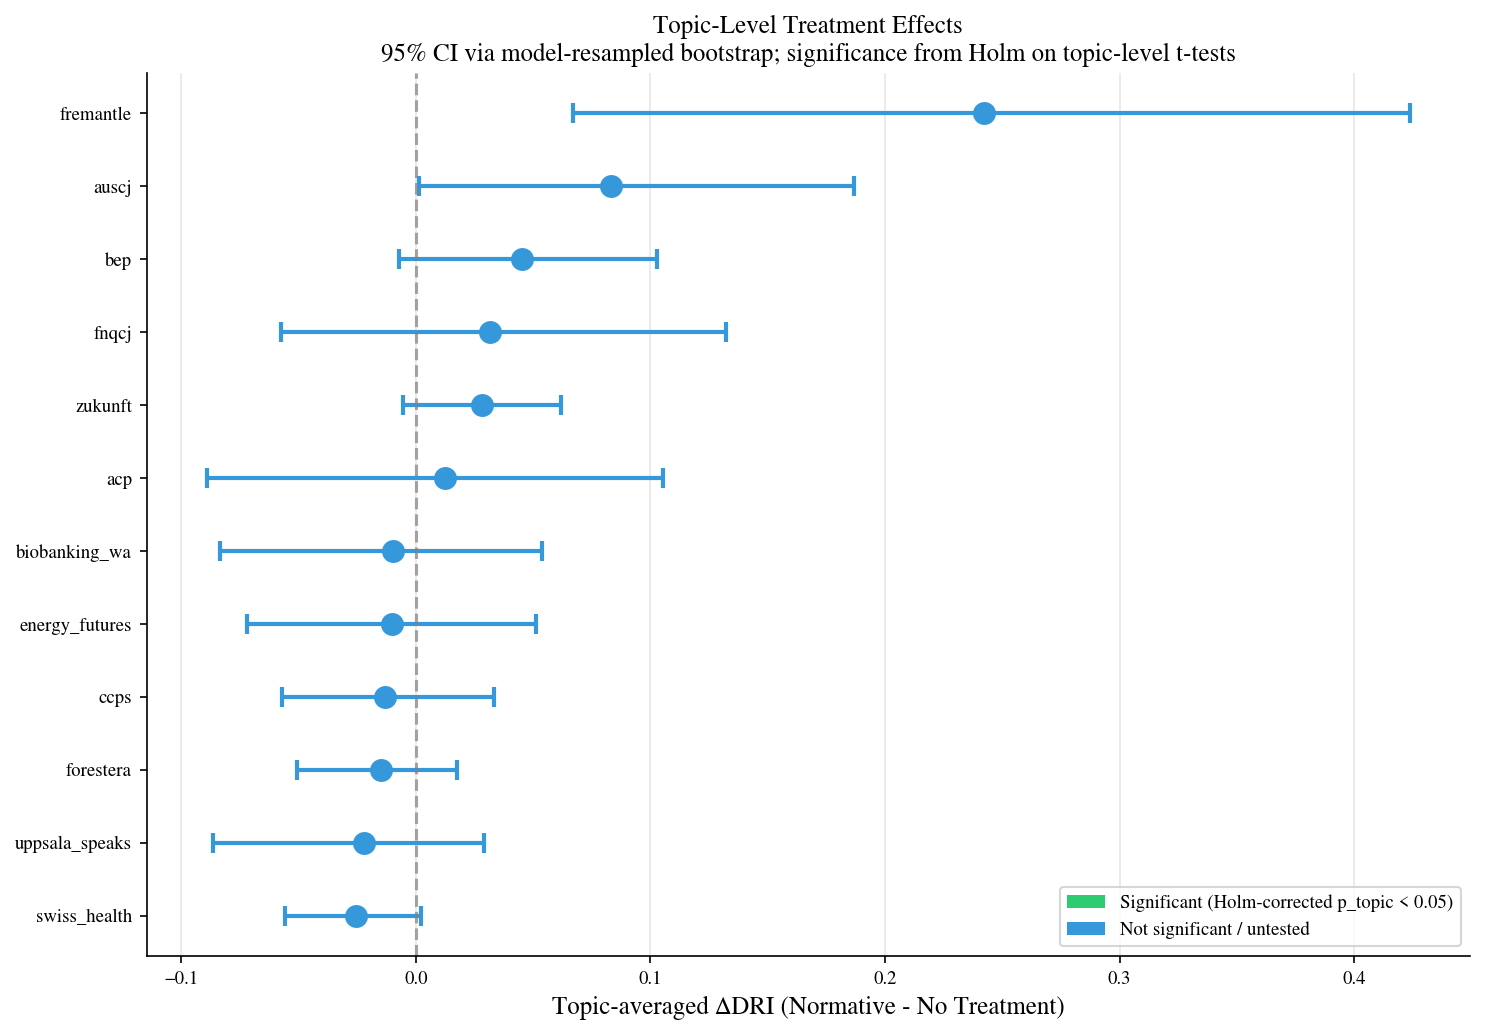

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/topic_effects_forest_holm.pdf


In [97]:
# Figure Topic-level treatment effects (model-averaged within topic; with bootstrap CI)

_first_title, _first_a, _first_b = PAIRWISE[0]
plot_key = make_key(_first_title, _first_a, _first_b)

plot_df = topic_effects_res[plot_key].copy()
plot_df = plot_df[pd.notnull(plot_df["mean_diff_models"])].copy()
plot_df = plot_df.sort_values("mean_diff_models", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 7))

if plot_df.empty:
    ax.text(0.5, 0.5, "No topic effects available to plot.", ha="center", va="center", transform=ax.transAxes)
else:
    y_pos = np.arange(len(plot_df))
    means = plot_df["mean_diff_models"].to_numpy()

    ci_low = plot_df["CI_low"].to_numpy()
    ci_high = plot_df["CI_high"].to_numpy()
    ci_low = np.where(np.isfinite(ci_low), ci_low, means)
    ci_high = np.where(np.isfinite(ci_high), ci_high, means)

    lower_err = means - ci_low
    upper_err = ci_high - means

    sig_flag = plot_df["sig_topic_holm"].fillna(False).astype(bool).to_numpy()
    colors = np.where(sig_flag, "#2ecc71", "#3498db")

    for i in range(len(plot_df)):
        ax.errorbar(
            means[i], i,
            xerr=[[lower_err[i]], [upper_err[i]]],
            fmt="o",
            markersize=10,
            capsize=5,
            capthick=2,
            color=colors[i],
            ecolor=colors[i],
            linewidth=2,
        )

    ax.axvline(x=0, color="gray", linestyle="--", linewidth=1.5, alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_df["Topic"].astype(str).to_list())

    ax.set_xlabel(f"Topic-averaged ΔDRI (Normative - No Treatment)", fontsize=12)
    ax.set_title(
        "Topic-Level Treatment Effects\n"
        "95% CI via model-resampled bootstrap; significance from Holm on topic-level t-tests",
        fontsize=12
    )

    legend_elements = [
        Patch(facecolor="#2ecc71", label="Significant (Holm-corrected p_topic < 0.05)"),
        Patch(facecolor="#3498db", label="Not significant / untested"),
    ]
    ax.legend(handles=legend_elements, loc="lower right")
    ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "topic_effects_forest_holm.pdf", format="pdf")
plt.savefig(FIGURES_DIR / "topic_effects_forest_holm.png", format="png")
plt.show()

print(f"Saved: {FIGURES_DIR / 'topic_effects_forest_holm.pdf'}")


---

# 5. LLM - Human Comparison

In [26]:
# Human vs LLM ΔDRI (topic-clustered, absolute)
print("=" * 92)
print("Human vs. LLM ΔDRI Comparison (absolute, topic-clustered)")
print("Uncertainty uses topic-level means with bootstrap CIs (topics/surveys are identical).")
print("=" * 92)

OUTCOME_COL = "delta_dri"
rng = np.random.default_rng(RNG_SEED)

# New condition names
COND_NORM = "Normative Treatment"
COND_BASIC = "Basic Treatment"
COND_NO = "No Treatment"

# Topic columns (as you stated: same topics/surveys)
HUM_TOPIC_COL = "survey"
LLM_TOPIC_COL = "topic"  # change if your llm df uses a different topic column name

def topic_row(label, df, value_col, topic_col):
    stats_row = topic_cluster_mean_ci(df, value_col, topic_col=topic_col, B=BOOT_B)
    ci_lo, ci_hi = stats_row["ci_boot"]
    ci_text = f"[{ci_lo:.3f}, {ci_hi:.3f}]" if np.isfinite(ci_lo) and np.isfinite(ci_hi) else "NA"
    return {
        "Source": label,
        "Mean ΔDRI": float(stats_row["mean"]),
        "Topics (clusters)": int(stats_row["n_clusters"]),
        "Bootstrap 95% CI": ci_text,
    }

# Rows: descriptive topic-clustered means
table6_rows = [
    topic_row("Human (real assemblies)", human_df, OUTCOME_COL, topic_col=HUM_TOPIC_COL),
    topic_row("LLM Normative Treatment", llm_df[llm_df["condition_label"] == COND_NORM], OUTCOME_COL, topic_col=LLM_TOPIC_COL),
    topic_row("LLM Basic Treatment",     llm_df[llm_df["condition_label"] == COND_BASIC], OUTCOME_COL, topic_col=LLM_TOPIC_COL),
    topic_row("LLM No Treatment",        llm_df[llm_df["condition_label"] == COND_NO], OUTCOME_COL, topic_col=LLM_TOPIC_COL),
]

table6_df = pd.DataFrame(table6_rows)
print(table6_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# Paired topic-level gap: Human - LLM Normative (same topics)
human_tm = human_df.groupby(HUM_TOPIC_COL)[OUTCOME_COL].mean()
llm_norm_tm = llm_df[llm_df["condition_label"] == COND_NORM].groupby(LLM_TOPIC_COL)[OUTCOME_COL].mean()

# Align on shared index (should be identical by your statement)
common = human_tm.index.intersection(llm_norm_tm.index)
paired = (human_tm.loc[common] - llm_norm_tm.loc[common]).dropna().to_numpy()

if paired.size > 0:
    boot = rng.choice(paired, size=(BOOT_B, paired.size), replace=True).mean(axis=1)
    ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

    print("\nPaired topic-level gap (Human - LLM Normative):")
    print(f"  Topics: {paired.size}")
    print(f"  Mean gap: {paired.mean():.3f}")
    print(f"  95% CI (topic bootstrap): [{ci_lo:.3f}, {ci_hi:.3f}]")
else:
    print("\nPaired gap not computed (no overlapping topic means).")

# LLM as percentage of human (descriptive)
llm_norm_mean = table6_rows[1]["Mean ΔDRI"]
human_mean = table6_rows[0]["Mean ΔDRI"]
if np.isfinite(human_mean) and human_mean != 0:
    print(f"\nLLM Normative as % of Human (topic-mean basis; descriptive): {100 * llm_norm_mean / human_mean:.1f}%")


Human vs. LLM ΔDRI Comparison (absolute, topic-clustered)
Uncertainty uses topic-level means with bootstrap CIs (topics/surveys are identical).
                 Source  Mean ΔDRI  Topics (clusters) Bootstrap 95% CI
Human (real assemblies)      0.099                 12   [0.026, 0.196]
LLM Normative Treatment      0.031                 12  [-0.007, 0.093]
    LLM Basic Treatment      0.021                 12  [-0.016, 0.077]
       LLM No Treatment      0.002                 12  [-0.012, 0.023]

Paired topic-level gap (Human - LLM Normative):
  Topics: 12
  Mean gap: 0.068
  95% CI (topic bootstrap): [-0.024, 0.176]

LLM Normative as % of Human (topic-mean basis; descriptive): 31.4%


In [27]:
# ΔDRI by topic — Human vs LLM (Normative & Basic), topic means
print("=" * 92)
print("ΔDRI by Topic — Human vs LLM (Normative & Basic)")
print("All values are topic means (so Human and LLM are on the same aggregation level).")
print("=" * 92)

OUTCOME_COL = "delta_dri"
HUM_TOPIC_COL = "survey"
LLM_TOPIC_COL = "topic"

COND_NORM = "Normative Treatment"
COND_BASIC = "Basic Treatment"

# Topic means
human_topic = human_df.groupby(HUM_TOPIC_COL)[OUTCOME_COL].mean().rename("Human")

llm_norm_topic = (
    llm_df[llm_df["condition_label"] == COND_NORM]
    .groupby(LLM_TOPIC_COL)[OUTCOME_COL].mean()
    .rename("LLM_Normative")
)

llm_basic_topic = (
    llm_df[llm_df["condition_label"] == COND_BASIC]
    .groupby(LLM_TOPIC_COL)[OUTCOME_COL].mean()
    .rename("LLM_Basic")
)

# Combine on shared topics (you said topics/surveys are identical)
comparison_df = (
    pd.concat([human_topic, llm_norm_topic, llm_basic_topic], axis=1)
    .reset_index()
    .rename(columns={HUM_TOPIC_COL: "Topic"})
)

# Winner based on available values (topic means)
def winner_row(r):
    vals = {
        "Human": r["Human"],
        "LLM (Normative)": r["LLM_Normative"],
        "LLM (Basic)": r["LLM_Basic"],
    }
    available = {k: v for k, v in vals.items() if pd.notna(v)}
    return max(available, key=available.get) if available else "N/A"

comparison_df["Winner"] = comparison_df.apply(winner_row, axis=1)

# Sort (choose your preferred sort key)
comparison_df = comparison_df.sort_values("Human", ascending=False)

# Print
print(f"\n{'index':<22} {'Human':>10} {'LLM-Norm':>12} {'LLM-Basic':>12} {'Winner':<16}")
print("-" * 78)
for _, r in comparison_df.iterrows():
    print(
        f"{str(r['index']):<22} "
        f"{r['Human']:>10.4f} "
        f"{(r['LLM_Normative'] if pd.notna(r['LLM_Normative']) else np.nan):>12.4f} "
        f"{(r['LLM_Basic'] if pd.notna(r['LLM_Basic']) else np.nan):>12.4f} "
        f"{r['Winner']:<16}"
    )

print("\nMeans across topics:")
print(f"  Mean (Human):         {comparison_df['Human'].mean():.4f}")
print(f"  Mean (LLM Normative): {comparison_df['LLM_Normative'].mean():.4f}")
print(f"  Mean (LLM Basic):     {comparison_df['LLM_Basic'].mean():.4f}")


ΔDRI by Topic — Human vs LLM (Normative & Basic)
All values are topic means (so Human and LLM are on the same aggregation level).

index                       Human     LLM-Norm    LLM-Basic Winner          
------------------------------------------------------------------------------
fnqcj                      0.5418       0.0083      -0.0232 Human           
uppsala_speaks             0.1980      -0.0192      -0.0273 Human           
fremantle                  0.1272       0.3481       0.2979 LLM (Normative) 
ccps                       0.1040      -0.0078       0.0203 Human           
zukunft                    0.0999       0.0171       0.0205 Human           
energy_futures             0.0750      -0.0094      -0.0482 Human           
forestera                  0.0601      -0.0195      -0.0310 Human           
auscj                      0.0450       0.0642      -0.0148 LLM (Normative) 
biobanking_wa              0.0326      -0.0136       0.0248 Human           
swiss_health        

findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not 

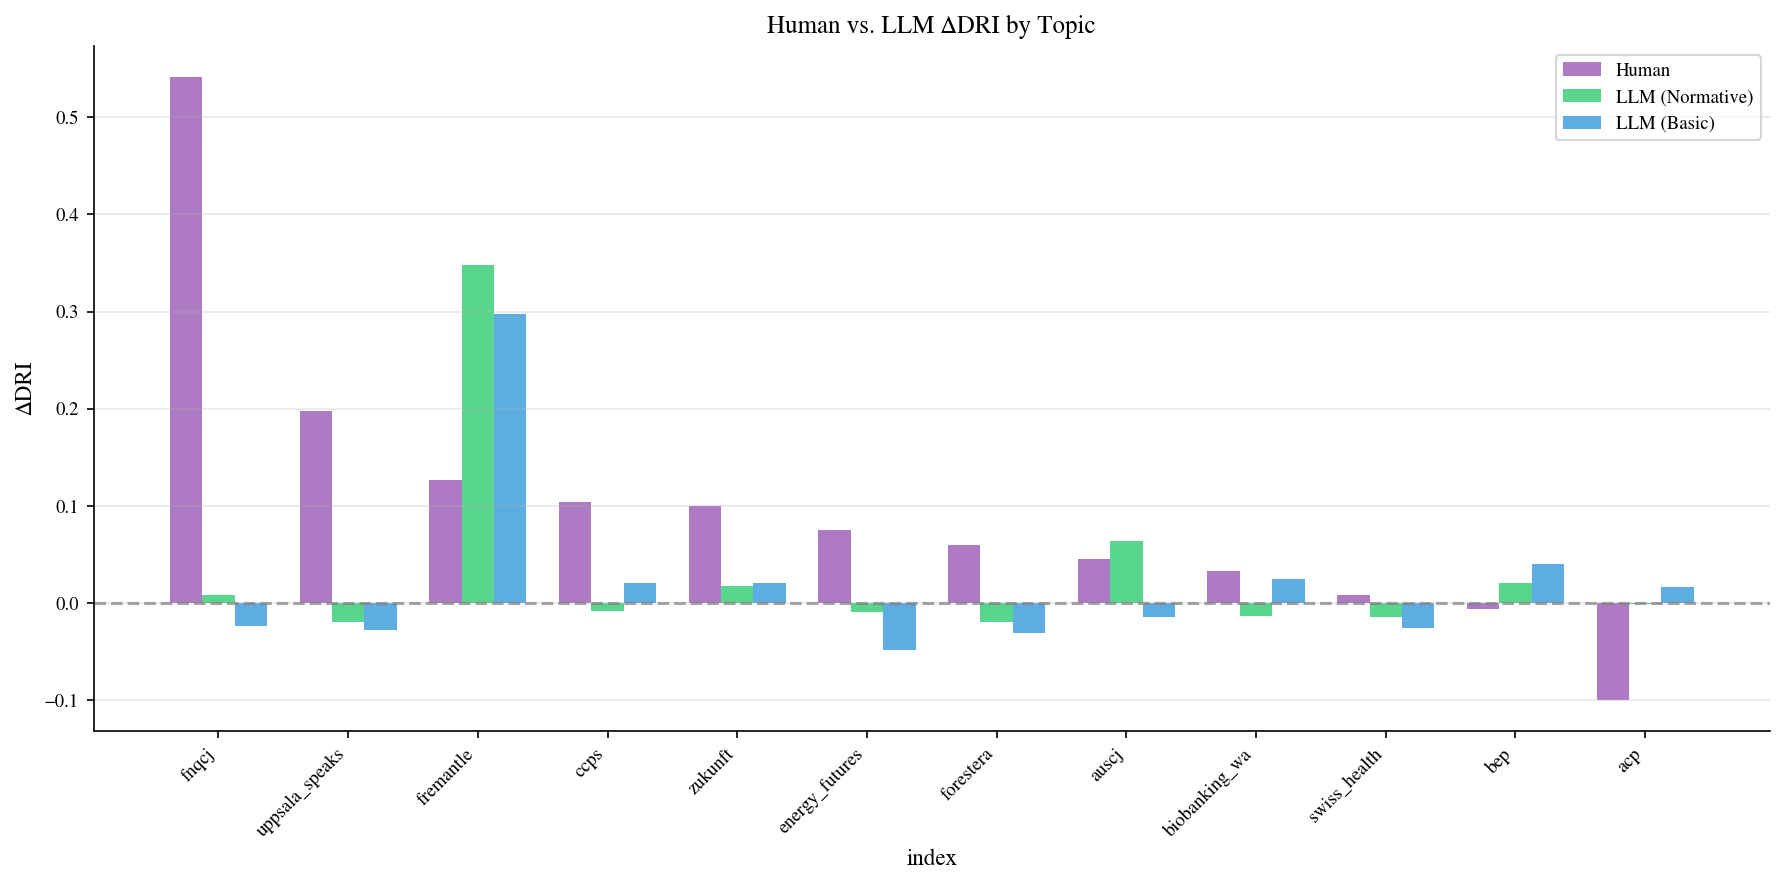

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/human_LLM_topic_comparison.pdf


In [98]:
# Figure Human vs. LLM comparison by topic
fig, ax = plt.subplots(figsize=(12, 6))

if len(comparison_df) > 0:
    x = np.arange(len(comparison_df))
    width = 0.25
    
    bars1 = ax.bar(x - width, comparison_df['Human'], width, 
                   label='Human', color='#9b59b6', alpha=0.8)
    bars2 = ax.bar(x, comparison_df['LLM_Normative'], width,
                   label='LLM (Normative)', color='#2ecc71', alpha=0.8)
    bars3 = ax.bar(x + width, comparison_df['LLM_Basic'], width,
                   label='LLM (Basic)', color='#3498db', alpha=0.8)
    
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df['index'], rotation=45, ha='right')
    ax.set_ylabel('ΔDRI', fontsize=11)
    ax.set_xlabel('index', fontsize=11)
    ax.set_title("Human vs. LLM ΔDRI by Topic", fontsize=12)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'human_LLM_topic_comparison.pdf', format='pdf')
plt.savefig(FIGURES_DIR / 'human_LLM_topic_comparison.png', format='png')
plt.show()
print(f"Saved: {FIGURES_DIR / 'human_LLM_topic_comparison.pdf'}")


findfont: Font family ['serif'] not found. Falling back to Helvetica.
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following f

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/dri_pre_post_paired_topicmeans_colored.png
Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/dri_pre_post_paired_topicmeans_colored.pdf


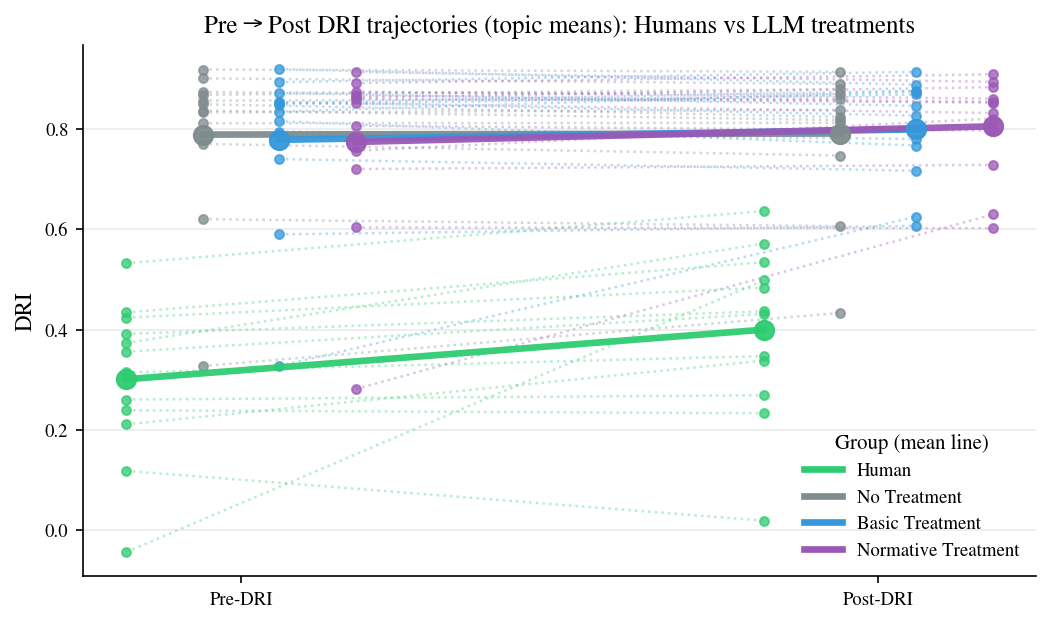

In [99]:
# Paired dot / slope plot: Pre-DRI → Post-DRI


# --- Guardrails: only use in-notebook data ---
missing = [name for name in ["llm_df", "human_df"] if name not in globals()]
if missing:
    raise NameError(
        f"Missing {missing} in the current notebook session. "
        "Run the earlier DRI loading cells to create llm_df and human_df first."
    )

# --- LLM: topic × treatment means ---
llm_topic = (
    llm_df.dropna(subset=["topic", "condition_label", "pre_dri", "post_dri"])
          .groupby(["condition_label", "topic"], as_index=False)[["pre_dri", "post_dri"]]
          .mean()
)
llm_topic["group"] = llm_topic["condition_label"].astype(str)

# --- Human: map survey -> topic (or use topic if already present) ---
human_topic = human_df.dropna(subset=["pre_dri", "post_dri"]).copy()
if "survey" in human_topic.columns:
    human_topic["topic"] = human_topic["survey"].astype(str)
elif "topic" not in human_topic.columns:
    raise KeyError("human_df needs either a 'survey' column or a 'topic' column.")
human_topic = human_topic[["topic", "pre_dri", "post_dri"]].copy()
human_topic["group"] = "Human"

plot_df = pd.concat(
    [
        human_topic[["group", "topic", "pre_dri", "post_dri"]],
        llm_topic[["group", "topic", "pre_dri", "post_dri"]],
    ],
    ignore_index=True
)

# Order groups (humans + canonical treatments)
group_order = ["Human", "No Treatment", "Basic Treatment", "Normative Treatment"]
group_order = [g for g in group_order if g in plot_df["group"].unique()]
# Append any unexpected groups
for g in sorted(set(plot_df["group"].unique()) - set(group_order)):
    group_order.append(g)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8.2, 4.6))

base_x = np.array([0.0, 1.0])  # pre, post
n_groups = len(group_order)
offsets = np.linspace(-0.18, 0.18, n_groups) if n_groups > 1 else np.array([0.0])

for i, g in enumerate(group_order):
    d = plot_df[plot_df["group"] == g].copy()
    if d.empty:
        continue

    color = CONDITION_COLORS.get(g, "#000000")  # fallback if an unexpected label appears
    x = base_x + offsets[i]

    # Thin dotted topic trajectories (same color)
    for _, r in d.iterrows():
        ax.plot(
            x, [r["pre_dri"], r["post_dri"]],
            linestyle=":",
            linewidth=1.2,
            alpha=0.35,
            color=color,
            zorder=1
        )
        ax.scatter(
            x, [r["pre_dri"], r["post_dri"]],
            s=18,
            alpha=0.75,
            color=color,
            zorder=2
        )

    # Thick solid group mean trajectory (same color)
    m_pre = float(d["pre_dri"].mean())
    m_post = float(d["post_dri"].mean())
    ax.plot(
        x, [m_pre, m_post],
        linestyle="-",
        linewidth=3.2,
        alpha=0.95,
        color=color,
        zorder=3
    )
    ax.scatter(
        x, [m_pre, m_post],
        s=85,
        alpha=0.95,
        color=color,
        zorder=4
    )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Pre-DRI", "Post-DRI"])
ax.set_ylabel("DRI")
ax.set_title("Pre → Post DRI trajectories (topic means): Humans vs LLM treatments")
ax.grid(True, axis="y", alpha=0.25)

# Legend: one entry per group (color-coded)
legend_handles = [
    Line2D([0], [0], color=CONDITION_COLORS.get(g, "#000000"), lw=3.2, linestyle="-", label=g)
    for g in group_order
]
ax.legend(handles=legend_handles, frameon=False, loc="best", title="Group (mean line)")

# Tight y-range around observed values (helps show ceiling effects)
ymin = float(np.nanmin(plot_df[["pre_dri", "post_dri"]].to_numpy()))
ymax = float(np.nanmax(plot_df[["pre_dri", "post_dri"]].to_numpy()))
pad = 0.05 * (ymax - ymin + 1e-9)
ax.set_ylim(ymin - pad, ymax + pad)

# Save if FIGURES_DIR exists (as in your notebook config)
if "FIGURES_DIR" in globals():
    out_png = FIGURES_DIR / "dri_pre_post_paired_topicmeans_colored.png"
    out_pdf = FIGURES_DIR / "dri_pre_post_paired_topicmeans_colored.pdf"
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    print(f"Saved: {out_png}")
    print(f"Saved: {out_pdf}")

plt.show()


## Pseudo-Experiment: Bootstrapping Groups of 5 from Human Data

In [30]:
# Pseudo-experiment: DISJOINT 5-person groups per topic
#    + matched subsampling of LLM runs per topic
# ---------------------------------------------------------


# Build participant-level human df with paired pre/post
def load_human_participants_from_csv(
    human_csv_path,
    filter_topics=None,
    verbose=True
):
    df = pd.read_csv(human_csv_path)

    # Normalize stage labels
    df["stage"] = (
        df["stage"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    )
    stage_map = {
        "Pre-Delib": "Pre-Delib", "pre-delib": "Pre-Delib", "Pre-delib": "Pre-Delib", "PRE-DELIB": "Pre-Delib",
        "Post-Delib": "Post-Delib", "post-delib": "Post-Delib", "Post-delib": "Post-Delib", "POST-DELIB": "Post-Delib",
    }
    df["stage"] = df["stage"].map(lambda x: stage_map.get(x, x))

    if filter_topics is not None:
        df = df[df["survey"].isin(filter_topics)].copy()

    # Parse each row into participant response dicts
    rows = []
    for _, row in df.iterrows():
        survey = row.get("survey")
        stage = row.get("stage")
        pnum = row.get("pnum")
        if pd.isna(survey) or pd.isna(stage) or pd.isna(pnum):
            continue

        considerations = {}
        for i in range(1, 51):
            col = f"C{i}"
            if col in df.columns and pd.notna(row.get(col)) and row.get(col) != "NA":
                try:
                    considerations[col] = float(row[col])
                except (ValueError, TypeError):
                    pass

        preferences = {}
        for i in range(1, 11):
            col = f"P{i}"
            if col in df.columns and pd.notna(row.get(col)) and row.get(col) != "NA":
                try:
                    preferences[col] = float(row[col])
                except (ValueError, TypeError):
                    pass

        # Keep only participants with both blocks present
        if considerations and preferences:
            rows.append({
                "survey": str(survey),
                "stage": str(stage),
                "pnum": int(pnum),
                "pid": f"p{int(pnum)}",
                "study": row.get("study", np.nan),
                "considerations": considerations,
                "preferences": preferences,
            })

    long_df = pd.DataFrame(rows)

    if verbose:
        print(f"[human] participant-stage rows with valid C/P: {len(long_df)}")
        if len(long_df):
            print(long_df["stage"].value_counts())

    # Pivot into paired pre/post rows per participant
    pre_df = long_df[long_df["stage"] == "Pre-Delib"].copy()
    post_df = long_df[long_df["stage"] == "Post-Delib"].copy()

    pre_df = pre_df.rename(columns={
        "considerations": "considerations_pre",
        "preferences": "preferences_pre",
        "pid": "pid_pre",
    })
    post_df = post_df.rename(columns={
        "considerations": "considerations_post",
        "preferences": "preferences_post",
        "pid": "pid_post",
    })

    # Pair by (survey, pnum): same participant observed pre and post
    paired = pre_df.merge(
        post_df[["survey", "pnum", "considerations_post", "preferences_post", "pid_post"]],
        on=["survey", "pnum"],
        how="inner",
        validate="one_to_one"
    )

    # Use one pid field
    paired["pid"] = paired["pid_pre"]
    paired = paired.drop(columns=["pid_pre", "pid_post"])

    if verbose:
        print(f"[human] paired participants with BOTH pre+post: {len(paired)}")
        by_topic = paired.groupby("survey").size().describe()
        print("[human] paired participants per topic (describe):")
        print(by_topic)

    return paired


def _canonical_condition_label(x: str) -> str:
    """Make condition labels robust to minor naming differences."""
    if x is None:
        return ""
    x = str(x).strip()
    aliases = {
        "Normative Treatment": "Treatment-Normative",
        "Basic Treatment": "Treatment-Basic",
        "Control": "No Treatment",
        "Treatment-Normative": "Normative Treatment",
        "Treatment-Basic": "Basic Treatment",
    }
    return aliases.get(x, x)

def _partition_indices_disjoint(rng: np.random.Generator, n: int, group_size: int, n_groups: int | None = None):
    """
    Randomly partition indices 0..n-1 into disjoint groups of size group_size.
    Returns a list of index arrays.
    """
    if n < group_size:
        return []
    if n_groups is None:
        n_groups = n // group_size
    else:
        n_groups = min(int(n_groups), n // group_size)

    perm = rng.permutation(n)
    take = perm[: n_groups * group_size]
    return [take[i*group_size:(i+1)*group_size] for i in range(n_groups)]

def draw_human_disjoint_groups(
    human_participant_df: pd.DataFrame,
    llm_slice_df: pd.DataFrame,
    group_size: int = 5,
    seed: int = 12345,
    require_min_items: int = 2,
    participant_bootstrap: bool = True,
    verbose: bool = False,
):
    """
    One pseudo-experiment draw:
      - For each topic: bootstrap participants (optional), then form disjoint groups of size 5.
      - Compute group-level pre/post/Δ DRI for each group (via DRICalculator).
      - For LLM: subsample runs within each topic to match #human groups in that topic for this draw.
    Returns:
      human_draw_df: group-level rows for humans in THIS draw
      llm_draw_df: matched subsample of LLM runs (same per-topic counts)
      diag: dict with diagnostics
    """
    rng = np.random.default_rng(seed)
    calc = DRICalculator()

    llm_slice_df = llm_slice_df.copy()
    llm_slice_df["topic"] = llm_slice_df["topic"].astype(str)

    topics = sorted(set(llm_slice_df["topic"]).intersection(set(human_participant_df["survey"].astype(str))))
    diag = {"topics_used": 0, "topics_skipped_no_groups": 0, "topic_group_counts": {}}

    human_rows = []
    llm_rows = []

    # Pre-index LLM rows by topic for faster sampling
    llm_by_topic = {t: llm_slice_df[llm_slice_df["topic"] == t].copy() for t in topics}

    for topic in topics:
        pool = human_participant_df[human_participant_df["survey"].astype(str) == str(topic)].copy()
        n_pool = len(pool)
        if n_pool < group_size:
            diag["topics_skipped_no_groups"] += 1
            continue

        # Participant bootstrap at the TOPIC level (recommended):
        # resample n_pool paired participants with replacement
        if participant_bootstrap:
            boot_idx = rng.integers(0, n_pool, size=n_pool)
            pool = pool.iloc[boot_idx].reset_index(drop=True)
            n_pool_eff = len(pool)
        else:
            pool = pool.reset_index(drop=True)
            n_pool_eff = n_pool

        # Disjoint partition into as many groups as possible
        groups = _partition_indices_disjoint(rng, n_pool_eff, group_size=group_size)
        if len(groups) == 0:
            diag["topics_skipped_no_groups"] += 1
            continue

        # Match LLM sample size to human group count in this draw (per topic)
        llm_topic = llm_by_topic[topic]
        if len(llm_topic) == 0:
            diag["topics_skipped_no_groups"] += 1
            continue

        k = min(len(groups), len(llm_topic))
        groups = groups[:k]

        # Subsample k LLM runs without replacement
        llm_pick = llm_topic.sample(n=k, replace=False, random_state=int(rng.integers(0, 2**31-1)))
        llm_pick = llm_pick.copy()

        diag["topics_used"] += 1
        diag["topic_group_counts"][topic] = k

        # --- Compute DRI per human group ---
        cons_pre = pool["considerations_pre"].values
        pref_pre = pool["preferences_pre"].values
        cons_post = pool["considerations_post"].values
        pref_post = pool["preferences_post"].values
        pids = pool["pid"].values

        for g_id, idx in enumerate(groups):
            pre_participants = {}
            post_participants = {}

            for j in idx:
                pid = str(pids[j])
                pre_participants[pid]  = {"considerations": cons_pre[j],  "preferences": pref_pre[j]}
                post_participants[pid] = {"considerations": cons_post[j], "preferences": pref_post[j]}

            pre_d, _  = calc.group_dri(pre_participants,  require_min_items=require_min_items, return_meta=True)
            post_d, _ = calc.group_dri(post_participants, require_min_items=require_min_items, return_meta=True)

            human_rows.append({
                "draw_id": 0,  # will be overwritten by caller in MC loop if desired
                "topic": str(topic),
                "pre__": pre_d["dri"],
                "post__": post_d["dri"],
                "delta__": post_d["dri"] - pre_d["dri"],
                "is_llm": 0,
                "source": "human_draw",
            })

        # --- Prepare matched LLM rows ---
        # Expect llm_slice_df already has pre_dri/post_dri columns; map to pre__/post__
        # If your columns differ (pre_dri_original, etc.), adjust here.
        if "pre_dri" in llm_pick.columns and "post_dri" in llm_pick.columns:
            llm_pick = llm_pick.rename(columns={"pre_dri": "pre__", "post_dri": "post__"})
        elif "pre_dri_original" in llm_pick.columns and "post_dri_original" in llm_pick.columns:
            llm_pick = llm_pick.rename(columns={"pre_dri_original": "pre__", "post_dri_original": "post__"})
        else:
            raise ValueError("LLM slice missing pre/post columns (expected pre_dri/post_dri or *_original).")

        llm_pick["delta__"] = llm_pick["post__"] - llm_pick["pre__"]
        llm_pick["is_llm"] = 1
        llm_pick["source"] = "llm_draw"
        llm_pick["topic"] = llm_pick["topic"].astype(str)

        llm_rows.append(llm_pick[["topic", "pre__", "post__", "delta__", "is_llm", "source"]])

    human_draw_df = pd.DataFrame(human_rows)
    llm_draw_df = pd.concat(llm_rows, ignore_index=True) if len(llm_rows) else pd.DataFrame(
        columns=["topic", "pre__", "post__", "delta__", "is_llm", "source"]
    )

    if verbose:
        print(f"[draw] topics_used={diag['topics_used']}, topics_skipped={diag['topics_skipped_no_groups']}")
        if len(human_draw_df):
            print("[draw] human groups:", len(human_draw_df), " | NaN delta:", human_draw_df["delta__"].isna().mean())
        if len(llm_draw_df):
            print("[draw] llm runs:", len(llm_draw_df), " | NaN delta:", llm_draw_df["delta__"].isna().mean())

    return human_draw_df, llm_draw_df, diag


# Inference: repeat draws, fit ANCOVA per draw, summarize coef dist

def mc_llm_vs_human_ancova(
    llm_df: pd.DataFrame,
    human_participant_df: pd.DataFrame,
    condition_label: str = "Normative Treatment",
    draws: int = BOOT_B_PARAM,
    group_size: int = 5,
    seed: int = RNG_SEED,
    require_min_items: int = 2,
    participant_bootstrap: bool = True,
    verbose_every: int = 200,
):
    """
    Monte Carlo pseudo-experiment:
      - Repeat: draw disjoint human groups per topic + matched LLM subsample.
      - Fit topic-FE ANCOVA within each draw.
      - Return distribution of is_llm coefficient (design-based / MC inference).

    Output includes:
      - coef distribution
      - percentile CI
      - MC p-value (two-sided, centered at 0)
      - draw diagnostics
    """
    llm_df = llm_df.copy()
    llm_df["topic"] = llm_df["topic"].astype(str)
    if "condition_label" in llm_df.columns:
        llm_df["condition_label"] = llm_df["condition_label"].map(_canonical_condition_label)

    condition_label = _canonical_condition_label(condition_label)
    llm_slice = llm_df[llm_df["condition_label"] == condition_label].copy()
    if len(llm_slice) == 0:
        raise ValueError(f"No LLM rows found for condition_label={condition_label!r}")

    # Ensure we have the expected pre/post fields in the LLM slice
    if not (("pre_dri" in llm_slice.columns and "post_dri" in llm_slice.columns) or
            ("pre_dri_original" in llm_slice.columns and "post_dri_original" in llm_slice.columns)):
        raise ValueError("LLM df must contain pre_dri/post_dri or pre_dri_original/post_dri_original columns.")

    rng_master = np.random.default_rng(seed)

    coefs = []
    diags = []

    formula_u = "post__ ~ pre__ + is_llm + C(topic)"

    for d in range(draws):
        draw_seed = int(rng_master.integers(0, 2**31 - 1))

        human_draw, llm_draw, diag = draw_human_disjoint_groups(
            human_participant_df=human_participant_df,
            llm_slice_df=llm_slice,
            group_size=group_size,
            seed=draw_seed,
            require_min_items=require_min_items,
            participant_bootstrap=participant_bootstrap,
            verbose=False,
        )

        # add draw id
        if len(human_draw):
            human_draw["draw_id"] = d
        if len(llm_draw):
            llm_draw["draw_id"] = d

        # Combine for regression (within-draw only)
        df_cmp = pd.concat([human_draw, llm_draw], ignore_index=True)

        # Need at least 2 topics to estimate topic FE sensibly
        if df_cmp["topic"].nunique() < 2:
            continue

        # Fit ANCOVA, cluster by topic (small clusters; we DO NOT use this SE for final inference)
        fit = smf.ols(formula_u, data=df_cmp).fit(
            cov_type="cluster", cov_kwds={"groups": df_cmp["topic"]}
        )

        if "is_llm" not in fit.params.index:
            continue

        coefs.append(float(fit.params["is_llm"]))
        diags.append({
            "draw_id": d,
            "topics_used": diag["topics_used"],
            "n_human_groups": int((df_cmp["is_llm"] == 0).sum()),
            "n_llm_runs": int((df_cmp["is_llm"] == 1).sum()),
        })

        if verbose_every and (d + 1) % verbose_every == 0:
            print(f"[mc] draw {d+1}/{draws}: collected_coefs={len(coefs)}")

    coefs = np.array(coefs, dtype=float)
    diag_df = pd.DataFrame(diags)

    if len(coefs) < max(50, draws // 10):
        print("[mc] Warning: few successful draws. Check topic pools and column mappings.")

    # Percentile CI + MC p-value (two-sided around 0)
    ci = (np.nanpercentile(coefs, 2.5), np.nanpercentile(coefs, 97.5))
    p_two = 2 * min(np.mean(coefs <= 0), np.mean(coefs >= 0))

    summary = {
        "condition_label": condition_label,
        "draws_requested": draws,
        "draws_used": int(len(coefs)),
        "coef_mean": float(np.nanmean(coefs)),
        "coef_median": float(np.nanmedian(coefs)),
        "coef_ci95": ci,
        "mc_p_two_sided_H0_is_llm_0": float(p_two),
    }

    return summary, coefs, diag_df


# Run

# Build participant-level paired data (your existing function)
human_participant_df = load_human_participants_from_csv(HUMAN_DATA_PATH, filter_topics=llm_topics, verbose=True)

# Run MC pseudo-experiment
summary, coef_dist, diag_df = mc_llm_vs_human_ancova(
    llm_df=llm_df,
    human_participant_df=human_participant_df,
    condition_label="Normative Treatment",   # robust to aliasing
    draws=BOOT_B_PARAM,                               
    group_size=5,
    seed=RNG_SEED,
    require_min_items=2,
    participant_bootstrap=True,               # recommended
    verbose_every=200,
)

print("\n[LLM vs Human] MC ANCOVA summary")
print(summary)

print("\n[LLM vs Human] Diagnostics (first rows)")
print(diag_df.head())

[human] participant-stage rows with valid C/P: 814
stage
Pre-Delib     407
Post-Delib    407
Name: count, dtype: int64
[human] paired participants with BOTH pre+post: 407
[human] paired participants per topic (describe):
count    12.000000
mean     33.916667
std      16.500459
min      11.000000
25%      22.250000
50%      30.000000
75%      45.750000
max      63.000000
dtype: float64
[mc] draw 200/2000: collected_coefs=200
[mc] draw 400/2000: collected_coefs=400
[mc] draw 600/2000: collected_coefs=600
[mc] draw 800/2000: collected_coefs=800
[mc] draw 1000/2000: collected_coefs=1000
[mc] draw 1200/2000: collected_coefs=1200
[mc] draw 1400/2000: collected_coefs=1400
[mc] draw 1600/2000: collected_coefs=1600
[mc] draw 1800/2000: collected_coefs=1800
[mc] draw 2000/2000: collected_coefs=2000

[LLM vs Human] MC ANCOVA summary
{'condition_label': 'Treatment-Normative', 'draws_requested': 2000, 'draws_used': 2000, 'coef_mean': 0.29952137109404803, 'coef_median': 0.30060159532755404, 'coef_ci

---

# 6. Ceiling Effects & Relative ΔDRI

## Establishing Ceiling Effects

In [31]:
# Ceiling effect regression by condition (topic-clustered for LLM)

print("=" * 92)
print("Ceiling Effect Regression (ΔDRI ~ pre-DRI)")
print("Interpretation: Negative β implies higher pre-DRI is associated with smaller ΔDRI (ceiling pattern).")
print("=" * 92)

PRE_COL = "pre_dri"
DELTA_COL = "delta_dri"
COND_COL = "condition_label"

CONDITIONS = ["No Treatment", "Basic Treatment", "Normative Treatment"]

# --- LLM topic column inference ---
topic_col_candidates = ["topic_label", "topic", "issue", "issue_label"]
LLM_TOPIC_COL = next((c for c in topic_col_candidates if c in llm_df.columns), None)
if LLM_TOPIC_COL is None:
    raise ValueError(
        f"No LLM topic column found. Expected one of {topic_col_candidates}. "
        f"Available columns: {list(llm_df.columns)}"
    )

def _canonical_condition_label(x: str) -> str:
    if x is None:
        return ""
    x = str(x).strip()
    aliases = {
        "Control": "No Treatment",
        "No Treatment": "No Treatment",
        "Basic Treatment": "Basic Treatment",
        "Normative Treatment": "Normative Treatment",
        "Treatment-Basic": "Basic Treatment",
        "Treatment-Normative": "Normative Treatment",
        "Control_1": "No Treatment",
        "Control_2": "No Treatment",
    }
    return aliases.get(x, x)

def _ensure_dri_cols_for_ceiling(df, topic_col):
    """
    Normalize to columns: topic, condition_label (if exists), pre_dri, delta_dri
    """
    out = df.copy()
    out["topic"] = out[topic_col].astype(str)

    if COND_COL in out.columns:
        out[COND_COL] = out[COND_COL].map(_canonical_condition_label)

    pre_col = next((c for c in ("pre_dri", "pre_dri_original", "pre__") if c in out.columns), None)
    if pre_col is None:
        raise KeyError(f"Could not find pre column. Tried ('pre_dri','pre_dri_original','pre__'). Available: {list(out.columns)[:30]}")
    out["pre_dri"] = pd.to_numeric(out[pre_col], errors="coerce")

    delta_col = next((c for c in ("delta_dri", "delta_dri_original", "delta__") if c in out.columns), None)
    if delta_col is not None:
        out["delta_dri"] = pd.to_numeric(out[delta_col], errors="coerce")
    else:
        post_col = next((c for c in ("post_dri", "post_dri_original", "post__") if c in out.columns), None)
        if post_col is None:
            raise KeyError("Could not find delta or post column to compute delta.")
        out["delta_dri"] = pd.to_numeric(out[post_col], errors="coerce") - out["pre_dri"]

    return out

def run_ceiling_regression_clustered(data, label, pre_col="pre_dri", delta_col="delta_dri", cluster_col="topic"):
    """
    OLS of delta on pre with cluster-robust SEs by cluster_col.
    """
    if pre_col not in data.columns or delta_col not in data.columns or cluster_col not in data.columns:
        return None

    clean = data[[pre_col, delta_col, cluster_col]].dropna().copy()
    clean = clean[np.isfinite(clean[pre_col].to_numpy()) & np.isfinite(clean[delta_col].to_numpy())]

    if len(clean) < 5:
        return None

    X = sm.add_constant(clean[pre_col])
    y = clean[delta_col]

    # If only 1 cluster, fall back to non-clustered (rare for topic-level human if N_topics=1)
    if clean[cluster_col].nunique() >= 2:
        fit = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": clean[cluster_col]})
        clusters = int(clean[cluster_col].nunique())
    else:
        fit = sm.OLS(y, X).fit()
        clusters = int(clean[cluster_col].nunique())

    return {
        "Condition": label,
        "β": float(fit.params[pre_col]),
        "SE": float(fit.bse[pre_col]),
        "R²": float(fit.rsquared),
        "p": float(fit.pvalues[pre_col]),
        "N": int(len(clean)),
        "Clusters": clusters,
        "_fit": fit,
    }

# ---------------------------------------------------------
# Human MC disjoint-group ceiling slope (unchanged)
# ---------------------------------------------------------

def _partition_disjoint(rng: np.random.Generator, n: int, group_size: int):
    if n < group_size:
        return []
    k = n // group_size
    perm = rng.permutation(n)
    take = perm[: k * group_size]
    return [take[i*group_size:(i+1)*group_size] for i in range(k)]

def mc_human_ceiling_beta(
    human_participant_df: pd.DataFrame,
    topics: list[str],
    draws: int = 500,
    group_size: int = 5,
    seed: int = RNG_SEED,
    require_min_items: int = 2,
    participant_bootstrap: bool = True,
):
    rng_master = np.random.default_rng(seed)
    calc = DRICalculator()

    pools = {}
    for t in topics:
        pool = human_participant_df[human_participant_df["survey"].astype(str) == str(t)].copy()
        if len(pool) >= group_size:
            pools[str(t)] = pool.reset_index(drop=True)

    if len(pools) == 0:
        raise ValueError("No human topics have enough paired participants for group_size.")

    betas, r2s, ns, clus = [], [], [], []

    for _ in range(draws):
        rng = np.random.default_rng(int(rng_master.integers(0, 2**31 - 1)))

        rows = []
        for t, pool in pools.items():
            n = len(pool)
            if n < group_size:
                continue

            if participant_bootstrap:
                boot_idx = rng.integers(0, n, size=n)
                pool_eff = pool.iloc[boot_idx].reset_index(drop=True)
            else:
                pool_eff = pool

            groups = _partition_disjoint(rng, len(pool_eff), group_size)
            if len(groups) == 0:
                continue

            cons_pre = pool_eff["considerations_pre"].values
            pref_pre = pool_eff["preferences_pre"].values
            cons_post = pool_eff["considerations_post"].values
            pref_post = pool_eff["preferences_post"].values
            pids = pool_eff["pid"].values

            for idx in groups:
                pre_participants, post_participants = {}, {}
                for j in idx:
                    pid = str(pids[j])
                    pre_participants[pid]  = {"considerations": cons_pre[j],  "preferences": pref_pre[j]}
                    post_participants[pid] = {"considerations": cons_post[j], "preferences": pref_post[j]}

                pre_d, _  = calc.group_dri(pre_participants,  require_min_items=require_min_items, return_meta=True)
                post_d, _ = calc.group_dri(post_participants, require_min_items=require_min_items, return_meta=True)

                pre_val = float(pre_d["dri"])
                post_val = float(post_d["dri"])
                if not (np.isfinite(pre_val) and np.isfinite(post_val)):
                    continue

                rows.append({"topic": str(t), "pre_dri": pre_val, "delta_dri": (post_val - pre_val)})

        df_draw = pd.DataFrame(rows)
        if len(df_draw) < 10 or df_draw["topic"].nunique() < 2:
            continue

        X = sm.add_constant(df_draw["pre_dri"])
        y = df_draw["delta_dri"]
        fit = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": df_draw["topic"]})

        beta = float(fit.params["pre_dri"])
        if np.isfinite(beta):
            betas.append(beta)
            r2s.append(float(fit.rsquared))
            ns.append(int(len(df_draw)))
            clus.append(int(df_draw["topic"].nunique()))

    betas = np.array(betas, dtype=float)
    if len(betas) == 0:
        raise ValueError("MC produced no valid draws for human ceiling regression.")

    ci = (float(np.percentile(betas, 2.5)), float(np.percentile(betas, 97.5)))
    p_two = 2 * min(np.mean(betas <= 0), np.mean(betas >= 0))

    summary = {
        "Condition": "Human (MC disjoint n=5)",
        "β": float(np.mean(betas)),
        "SE": float(np.std(betas, ddof=1)),  # across-draw SD (not regression SE)
        "R²": float(np.mean(r2s)) if len(r2s) else np.nan,
        "p": float(p_two),
        "N": int(np.round(np.mean(ns))) if len(ns) else np.nan,
        "Clusters": int(np.round(np.mean(clus))) if len(clus) else np.nan,
        "_ci95": ci,
        "_draws_used": int(len(betas)),
    }
    return summary, betas

# ---------------------------------------------------------
# NEW: Human classic N=12 topic-level row
# ---------------------------------------------------------

def human_classic_topic_level_ceiling_row(
    human_participant_df: pd.DataFrame,
    topics: list[str],
    require_min_items: int = 2,
):
    """
    One observation per topic:
      - compute pre_dri(topic) and delta_dri(topic) from ALL paired participants in that topic
      - run delta ~ pre across topics (N≈12)
    """
    calc = DRICalculator()
    rows = []

    for t in topics:
        pool = human_participant_df[human_participant_df["survey"].astype(str) == str(t)].copy()
        if len(pool) == 0:
            continue

        pre_participants, post_participants = {}, {}
        for _, r in pool.iterrows():
            pid = str(r["pid"])
            pre_participants[pid]  = {"considerations": r["considerations_pre"],  "preferences": r["preferences_pre"]}
            post_participants[pid] = {"considerations": r["considerations_post"], "preferences": r["preferences_post"]}

        pre_d, _  = calc.group_dri(pre_participants,  require_min_items=require_min_items, return_meta=True)
        post_d, _ = calc.group_dri(post_participants, require_min_items=require_min_items, return_meta=True)

        pre_val = float(pre_d["dri"])
        post_val = float(post_d["dri"])
        if not (np.isfinite(pre_val) and np.isfinite(post_val)):
            continue

        rows.append({"topic": str(t), "pre_dri": pre_val, "delta_dri": (post_val - pre_val), "n_paired": int(len(pool))})

    df_t = pd.DataFrame(rows)
    if len(df_t) < 5:
        return None, df_t

    # classic topic-level regression (no clustering needed; N is topics)
    X = sm.add_constant(df_t["pre_dri"])
    y = df_t["delta_dri"]
    fit = sm.OLS(y, X).fit()

    return ({
        "Condition": f"Human (classic N={df_t['topic'].nunique()} topics)",
        "β": float(fit.params["pre_dri"]),
        "SE": float(fit.bse["pre_dri"]),
        "R²": float(fit.rsquared),
        "p": float(fit.pvalues["pre_dri"]),
        "N": int(len(df_t)),
        "Clusters": int(df_t["topic"].nunique()),
        "_fit": fit,
    }, df_t)

# ---------------------------------------------------------
# Run LLM regressions + Human MC + Human classic
# ---------------------------------------------------------

ceiling_results = []

llm_ceiling = _ensure_dri_cols_for_ceiling(llm_df, topic_col=LLM_TOPIC_COL)

# LLM (All)
res_all = run_ceiling_regression_clustered(llm_ceiling, "LLM (All)")
if res_all:
    ceiling_results.append(res_all)

# LLM by condition
for cond in CONDITIONS:
    sub = llm_ceiling[llm_ceiling[COND_COL] == cond].copy()
    res = run_ceiling_regression_clustered(sub, cond)
    if res:
        ceiling_results.append(res)

# Align topics for human rows
llm_topics = sorted(llm_ceiling["topic"].dropna().astype(str).unique().tolist())
human_topics = sorted(set(human_participant_df["survey"].astype(str)).intersection(set(llm_topics)))

# Human MC disjoint groups
HUMAN_DRAWS = 2000
human_mc_row, human_beta_dist = mc_human_ceiling_beta(
    human_participant_df=human_participant_df,
    topics=human_topics,
    draws=HUMAN_DRAWS,
    group_size=5,
    seed=RNG_SEED,
    require_min_items=2,
    participant_bootstrap=True,
)
ceiling_results.append(human_mc_row)

# NEW: Human classic N=12 topic-level
human_classic_row, human_classic_topic_df = human_classic_topic_level_ceiling_row(
    human_participant_df=human_participant_df,
    topics=human_topics,
    require_min_items=2,
)
if human_classic_row:
    ceiling_results.append(human_classic_row)

# ---------------------------------------------------------
# Print table
# ---------------------------------------------------------
ceiling_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in ceiling_results])

print(f"\n{'Condition':<30} {'β':>10} {'SE':>10} {'R²':>8} {'p':>12} {'N':>6} {'Clusters':>10}")
print("-" * 98)
for _, row in ceiling_df.iterrows():
    p_val = row["p"]
    p_str = f"{p_val:.4g}" if (pd.notnull(p_val) and p_val >= 0.001) else ("<0.001" if pd.notnull(p_val) else "NA")
    print(
        f"{row['Condition']:<30} {row['β']:>10.3f} {row['SE']:>10.3f} {row['R²']:>8.2f} "
        f"{p_str:>12} {int(row['N']) if pd.notnull(row['N']) else 0:>6} "
        f"{int(row['Clusters']) if pd.notnull(row['Clusters']) else 0:>10}"
    )

# Human MC details (explicit CI)
print("\nHuman MC details:")
print(f"  draws_used={human_mc_row['_draws_used']}, 95% CI for β: {human_mc_row['_ci95']}")

# Human classic diagnostics
if human_classic_row:
    print("\nHuman classic (topic-level) diagnostics:")
    print(f"  N_topics={human_classic_topic_df['topic'].nunique()}, paired participants per topic (describe):")
    print(human_classic_topic_df['n_paired'].describe())

print("\nNotes:")
print("  - LLM rows: OLS(Δ ~ pre) with topic-clustered SEs (small-cluster caution with ~12 topics).")
print("  - Human (MC): β is the mean across pseudo-experiments using disjoint 5-person groups;")
print("               SE is across-draw SD; p is an MC two-sided sign p-value; CI reported separately.")
print("  - Human (classic): one observation per topic (≈12); standard OLS across topics (no pseudo-replication).")
print("  - For paper-grade inference with ~12 topics, prefer wild cluster bootstrap for LLM and report human classic as N=12 benchmark.")


Ceiling Effect Regression (ΔDRI ~ pre-DRI)
Interpretation: Negative β implies higher pre-DRI is associated with smaller ΔDRI (ceiling pattern).

Condition                               β         SE       R²            p      N   Clusters
--------------------------------------------------------------------------------------------------
LLM (All)                          -0.498      0.067     0.36       <0.001   1980         12
No Treatment                       -0.285      0.029     0.19       <0.001    660         12
Basic Treatment                    -0.616      0.114     0.43       <0.001    660         12
Normative Treatment                -0.585      0.077     0.48       <0.001    660         12
Human (MC disjoint n=5)            -0.672      0.118     0.31       <0.001     77         12
Human (classic N=12 topics)        -0.418      0.291     0.17        0.182     12         12

Human MC details:
  draws_used=2000, 95% CI for β: (-0.9058850926695557, -0.4420386197611421)

Human cla

## Relative ΔDRI

In [32]:
# Pooled (topic×model-blocked) Treatment Comparisons

# -----------------------------
# Helpers
# -----------------------------
def infer_topic_col(df: pd.DataFrame) -> str:
    topic_col = next((c for c in TOPIC_COL_CANDIDATES if c in df.columns), None)
    if topic_col is None:
        raise ValueError(
            f"No topic column found. Expected one of {TOPIC_COL_CANDIDATES}. "
            f"Available columns: {list(df.columns)}"
        )
    return topic_col


def _prep_subdf(df, outcome, cond_a, cond_b, topic_col):
    sub = df[df[COND_COL].isin([cond_a, cond_b])].copy()
    sub = sub.dropna(subset=[outcome, COND_COL, MODEL_COL, topic_col])
    # If relative outcome can be inf/NaN, enforce finiteness
    sub = sub[np.isfinite(sub[outcome].to_numpy())]
    return sub


def pooled_block_ate(df, outcome, cond_a, cond_b, topic_col):
    """
    Point estimate: average over topic×model blocks of (mean_a - mean_b).
    Returns:
      ate: float
      block_deltas: Series indexed by (topic, model)
    """
    sub = _prep_subdf(df, outcome, cond_a, cond_b, topic_col)

    means = (
        sub.groupby([topic_col, MODEL_COL, COND_COL])[outcome]
        .mean()
        .unstack(COND_COL)
    )
    # keep only blocks with both conditions
    means = means.dropna(subset=[cond_a, cond_b])

    block_deltas = means[cond_a] - means[cond_b]
    ate = block_deltas.mean()  # equal weight per (topic, model) block
    return ate, block_deltas


def topic_bootstrap_ci(block_deltas, topic_level=0, B=BOOT_B, seed=RNG_SEED):
    """
    Topic-resampled bootstrap CI for pooled ATE:
    - Resample topics with replacement
    - For each resample, average block deltas across all models within sampled topics
    """
    rng = np.random.default_rng(seed)

    idx = block_deltas.index
    topics = np.array(sorted(idx.get_level_values(topic_level).unique()))

    by_topic = {t: block_deltas.xs(t, level=topic_level) for t in topics}

    boot_stats = np.empty(B, dtype=float)
    for b in range(B):
        sampled_topics = rng.choice(topics, size=len(topics), replace=True)
        vals = []
        for t in sampled_topics:
            vals.append(by_topic[t].to_numpy())
        vals = np.concatenate(vals) if len(vals) else np.array([np.nan])
        boot_stats[b] = np.nanmean(vals)

    ci_low, ci_high = np.nanpercentile(boot_stats, [2.5, 97.5])
    return ci_low, ci_high, boot_stats


def blocked_permutation_pvalue(df, outcome, cond_a, cond_b, topic_col, B=PERM_B, seed=RNG_SEED):
    """
    Blocked permutation test:
    within each (topic, model) block, permute condition labels while preserving
    the original group sizes. Compute pooled ATE (equal weight per block).
    """
    rng = np.random.default_rng(seed)
    sub = _prep_subdf(df, outcome, cond_a, cond_b, topic_col)

    obs, _ = pooled_block_ate(sub, outcome, cond_a, cond_b, topic_col)

    blocks = []
    for (t, m), g in sub.groupby([topic_col, MODEL_COL]):
        ya = g.loc[g[COND_COL] == cond_a, outcome].to_numpy()
        yb = g.loc[g[COND_COL] == cond_b, outcome].to_numpy()
        if len(ya) == 0 or len(yb) == 0:
            continue
        y = np.concatenate([ya, yb])
        n_a = len(ya)
        blocks.append((y, n_a))

    if len(blocks) == 0:
        return np.nan, obs

    perm_stats = np.empty(B, dtype=float)
    for b in range(B):
        deltas = []
        for y, n_a in blocks:
            n = len(y)
            idx_a = rng.choice(n, size=n_a, replace=False)
            mask = np.zeros(n, dtype=bool)
            mask[idx_a] = True
            mean_a = y[mask].mean()
            mean_b = y[~mask].mean()
            deltas.append(mean_a - mean_b)
        perm_stats[b] = np.mean(deltas)

    p = (np.sum(np.abs(perm_stats) >= np.abs(obs)) + 1) / (B + 1)
    return p, obs


def pooled_comparison(df, outcome, name, cond_a, cond_b, topic_col,
                      perm_B=PERM_B, boot_B=BOOT_B, seed=RNG_SEED):
    ate, block_deltas = pooled_block_ate(df, outcome, cond_a, cond_b, topic_col)
    ci_low, ci_high, _ = topic_bootstrap_ci(block_deltas, B=BOOT_B, seed=RNG_SEED + 1)
    p_perm, _ = blocked_permutation_pvalue(df, outcome, cond_a, cond_b, topic_col,
                                           B=perm_B, seed=RNG_SEED + 2)

    # optional diagnostic (kept as in your original): topic-averaged block deltas
    topic_deltas = block_deltas.groupby(level=0).mean()
    t_stat, p_topic = stats.ttest_1samp(topic_deltas.to_numpy(), 0.0, nan_policy="omit")

    return {
        "contrast": name,
        "outcome": outcome,
        "ATE_block_mean": ate,
        "CI95_topic_boot_low": ci_low,
        "CI95_topic_boot_high": ci_high,
        "p_perm_blocked": p_perm,
        "t_topic_level": t_stat,
        "p_topic_level": p_topic,
        "n_topics": int(topic_deltas.shape[0]),
        "n_blocks_topicxmodel": int(block_deltas.shape[0]),
    }


# -----------------------------
# Run pooled, blocked comparisons
# -----------------------------
topic_col = infer_topic_col(llm_df)

OUTCOMES = ["delta_dri"]
if "delta_dri_relative" in llm_df.columns:
    OUTCOMES.append("delta_dri_relative")

all_rows = []
for outcome in OUTCOMES:
    for cname, ca, cb in PAIRWISE:
        row = pooled_comparison(
            llm_df, outcome, cname, ca, cb, topic_col,
            perm_B=PERM_B, boot_B=BOOT_B, seed=RNG_SEED
        )
        all_rows.append(row)

pooled_results = pd.DataFrame(all_rows)

# Holm correction over the 3 pairwise tests PER OUTCOME (using permutation p-values)
pooled_results["p_perm_holm"] = np.nan
for outcome in pooled_results["outcome"].unique():
    mask = pooled_results["outcome"] == outcome
    pvals = pooled_results.loc[mask, "p_perm_blocked"].to_numpy()
    _, p_adj, _, _ = multipletests(pvals, method="holm")
    pooled_results.loc[mask, "p_perm_holm"] = p_adj

display_cols = [
    "outcome", "contrast",
    "ATE_block_mean", "CI95_topic_boot_low", "CI95_topic_boot_high",
    "p_perm_blocked", "p_perm_holm",
    "n_topics", "n_blocks_topicxmodel",
]
print("\nPOOLED (topic×model-blocked) TREATMENT COMPARISONS")
print("Point estimate = mean over topic×model blocks of within-block mean differences.")
print("p-value = blocked permutation within each topic×model block (preserving 5 vs 5).")
print("CI = topic-resampled bootstrap (resample topics; keep all models within topic).")
print(pooled_results[display_cols].to_string(index=False))



POOLED (topic×model-blocked) TREATMENT COMPARISONS
Point estimate = mean over topic×model blocks of within-block mean differences.
p-value = blocked permutation within each topic×model block (preserving 5 vs 5).
CI = topic-resampled bootstrap (resample topics; keep all models within topic).
           outcome                     contrast  ATE_block_mean  CI95_topic_boot_low  CI95_topic_boot_high  p_perm_blocked  p_perm_holm  n_topics  n_blocks_topicxmodel
         delta_dri    Normative vs No Treatment        0.028957            -0.003752              0.075732        0.004860     0.014580        12                   132
         delta_dri        Basic vs No Treatment        0.018715            -0.011358              0.057463        0.079138     0.158277        12                   132
         delta_dri Normative vs Basic Treatment        0.010242            -0.007699              0.029731        0.349313     0.349313        12                   132
delta_dri_relative    Normative vs 

findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not 

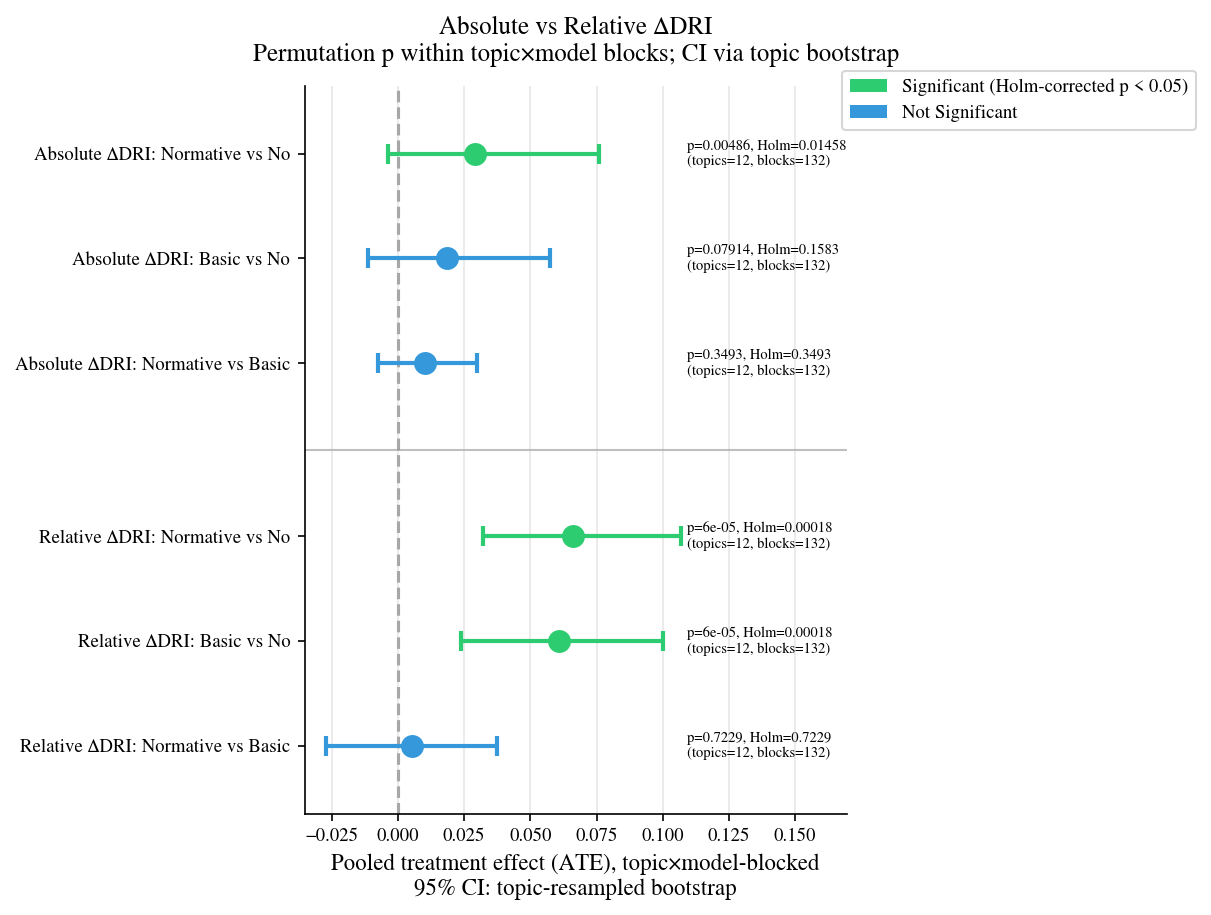

Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/abs_vs_rel_one_plot.pdf
Saved: /home/maurice/code/deliberation_simulator_final/analysis/figures/abs_vs_rel_one_plot.png


In [103]:
# Figure: Absolute + Relative ΔDRI in one plot


def _pick_ci_columns(d: pd.DataFrame):
    if {"CI95_topic_boot_low", "CI95_topic_boot_high"}.issubset(d.columns):
        return "CI95_topic_boot_low", "CI95_topic_boot_high", "topic-resampled bootstrap"
    if {"CI95_block_boot_low", "CI95_block_boot_high"}.issubset(d.columns):
        return "CI95_block_boot_low", "CI95_block_boot_high", "block-resampled bootstrap"
    raise ValueError(
        "No recognized CI columns found. Expected either:\n"
        "  - CI95_topic_boot_low / CI95_topic_boot_high\n"
        "  - CI95_block_boot_low / CI95_block_boot_high\n"
        f"Available columns: {list(d.columns)}"
    )


def plot_fig8_abs_rel_one_plot(
    pooled_tbl: pd.DataFrame,
    out_pdf,
    out_png,
    show_holm: bool = True,
):
    # -----------------------------
    # 1) Slice to the 2 outcomes + 3 contrasts you want
    # -----------------------------
    outcomes_keep = ["delta_dri", "delta_dri_relative"]

    rename_map = {
        "Normative vs No Treatment": "Normative vs No",
        "Basic vs No Treatment": "Basic vs No",
        "Normative vs Basic Treatment": "Normative vs Basic",
    }
    contrasts_keep = ["Normative vs No", "Basic vs No", "Normative vs Basic"]

    d = pooled_tbl[pooled_tbl["outcome"].isin(outcomes_keep)].copy()
    if d.empty:
        raise ValueError(f"No rows for outcomes={outcomes_keep} in pooled_tbl.")

    d["contrast"] = d["contrast"].astype(str).replace(rename_map)

    d = d[d["contrast"].isin(contrasts_keep)].copy()
    if d.empty:
        raise ValueError(
            f"After filtering contrasts {contrasts_keep}, no rows remain.\n"
            f"Available contrasts: {sorted(pooled_tbl['contrast'].dropna().astype(str).unique().tolist())}"
        )

    # Ensure all required combos exist
    missing = []
    for oc in outcomes_keep:
        for c in contrasts_keep:
            if not ((d["outcome"] == oc) & (d["contrast"] == c)).any():
                missing.append((oc, c))
    if missing:
        raise ValueError(f"Missing required (outcome, contrast) combos: {missing}")

    # -----------------------------
    # 2) Ordering: 3 absolute rows, then 3 relative rows
    # -----------------------------
    outcome_order = ["delta_dri", "delta_dri_relative"]
    outcome_label = {
        "delta_dri": "Absolute ΔDRI",
        "delta_dri_relative": "Relative ΔDRI",
    }

    d["outcome_cat"] = pd.Categorical(d["outcome"], categories=outcome_order, ordered=True)
    d["contrast_cat"] = pd.Categorical(d["contrast"], categories=contrasts_keep, ordered=True)
    d = d.sort_values(["outcome_cat", "contrast_cat"]).reset_index(drop=True)

    # Display label on y-axis (outcome + contrast)
    d["display_label"] = d.apply(
        lambda r: f"{outcome_label[str(r['outcome'])]}: {str(r['contrast'])}",
        axis=1
    )

    # -----------------------------
    # 3) Extract stats
    # -----------------------------
    if "ATE_block_mean" not in d.columns:
        raise ValueError("Missing required column: 'ATE_block_mean'")

    ci_low_col, ci_high_col, ci_label = _pick_ci_columns(d)

    ate = d["ATE_block_mean"].to_numpy(dtype=float)
    ci_low = d[ci_low_col].to_numpy(dtype=float)
    ci_high = d[ci_high_col].to_numpy(dtype=float)
    xerr = np.vstack([ate - ci_low, ci_high - ate])

    # Significance
    p_raw = d.get("p_perm_blocked", pd.Series(np.nan, index=d.index)).to_numpy(dtype=float)
    p_holm = d.get("p_perm_holm", pd.Series(np.nan, index=d.index)).to_numpy(dtype=float)

    if show_holm and np.isfinite(p_holm).any():
        sig = np.isfinite(p_holm) & (p_holm < 0.05)
        sig_label = "Significant (Holm-corrected p < 0.05)"
    else:
        sig = np.isfinite(p_raw) & (p_raw < 0.05)
        sig_label = "Significant (p < 0.05)"

    col_sig = "#2ecc71"
    col_nsig = "#3498db"
    colors = np.where(sig, col_sig, col_nsig)

    # -----------------------------
    # 4) Single-axis layout with a group gap between absolute and relative
    # -----------------------------
    y_spacing = 0.85
    group_gap = 0.55  # extra gap between the two outcome groups

    # 6 rows total: indices 0..5
    # Insert a small gap after row 2
    y = []
    for i in range(len(d)):
        base = i * y_spacing
        if i >= 3:
            base += group_gap
        y.append(base)
    y = np.array(y, dtype=float)

    # figure height enough for annotations
    fig_h = max(4.2, 0.70 * len(d) + 2.0)
    fig, ax = plt.subplots(figsize=(11.5, fig_h))

    # -----------------------------
    # 5) Plot
    # -----------------------------
    for i in range(len(d)):
        ax.errorbar(
            ate[i], y[i],
            xerr=xerr[:, [i]],
            fmt="o",
            markersize=10,
            capsize=5,
            capthick=2,
            linewidth=2,
            color=colors[i],
            ecolor=colors[i],
            zorder=3,
        )

    ax.axvline(x=0, color="gray", linestyle="--", linewidth=1.5, alpha=0.7, zorder=1)

    ax.set_yticks(y)
    ax.set_yticklabels(d["display_label"].tolist())

    ax.set_xlabel(
        "Pooled treatment effect (ATE), topic×model-blocked\n"
        f"95% CI: {ci_label}"
    )

    ax.set_title(
        "Absolute vs Relative ΔDRI\n"
        "Permutation p within topic×model blocks; CI via topic bootstrap",
        pad=12
    )

    ax.grid(True, axis="x", alpha=0.3, zorder=0)

    # Separator line between Absolute and Relative groups (between rows 2 and 3)
    sep_y = (y[2] + y[3]) / 2.0
    ax.axhline(sep_y, color="black", linewidth=1.0, alpha=0.25, zorder=0)

    # -----------------------------
    # 6) Annotations (p-values + topics/blocks)
    # -----------------------------
    span = (np.nanmax(ci_high) - np.nanmin(ci_low) + 1e-9)
    x_text = np.nanmax(ci_high) + 0.015 * span

    for i, row in enumerate(d.itertuples(index=False)):
        p_raw_i = getattr(row, "p_perm_blocked", np.nan)
        p_holm_i = getattr(row, "p_perm_holm", np.nan)

        if show_holm and np.isfinite(p_holm_i):
            p_str = f"p={p_raw_i:.4g}, Holm={p_holm_i:.4g}"
        else:
            p_str = f"p={p_raw_i:.4g}"

        n_topics = getattr(row, "n_topics", np.nan)
        n_blocks = getattr(row, "n_blocks_topicxmodel", np.nan)

        ax.text(
            x_text, y[i],
            f"{p_str}\n(topics={n_topics}, blocks={n_blocks})",
            va="center",
            fontsize=7,
            zorder=4,
        )

    # Limits (extra space right for annotations + legend)
    xmin = np.nanmin(ci_low) - 0.06 * span
    xmax = x_text + 0.45 * span
    ax.set_xlim(xmin, xmax)

    ax.set_ylim(y.min() - 0.55, y.max() + 0.55)
    ax.invert_yaxis()

    # Legend outside top-right
    legend_elements = [
        Patch(facecolor=col_sig, label=sig_label),
        Patch(facecolor=col_nsig, label="Not Significant"),
    ]
    ax.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        borderaxespad=-0.8
    )

    plt.tight_layout(rect=[0, 0, 0.72, 1])

    plt.savefig(out_pdf, format="pdf")
    plt.savefig(out_png, format="png", dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved:", out_pdf)
    print("Saved:", out_png)


# =========================================================
# RUN (single combined plot)
# =========================================================
plot_fig8_abs_rel_one_plot(
    pooled_results,
    out_pdf=FIGURES_DIR / "abs_vs_rel_one_plot.pdf",
    out_png=FIGURES_DIR / "abs_vs_rel_one_plot.png",
    show_holm=True,
)


findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not 

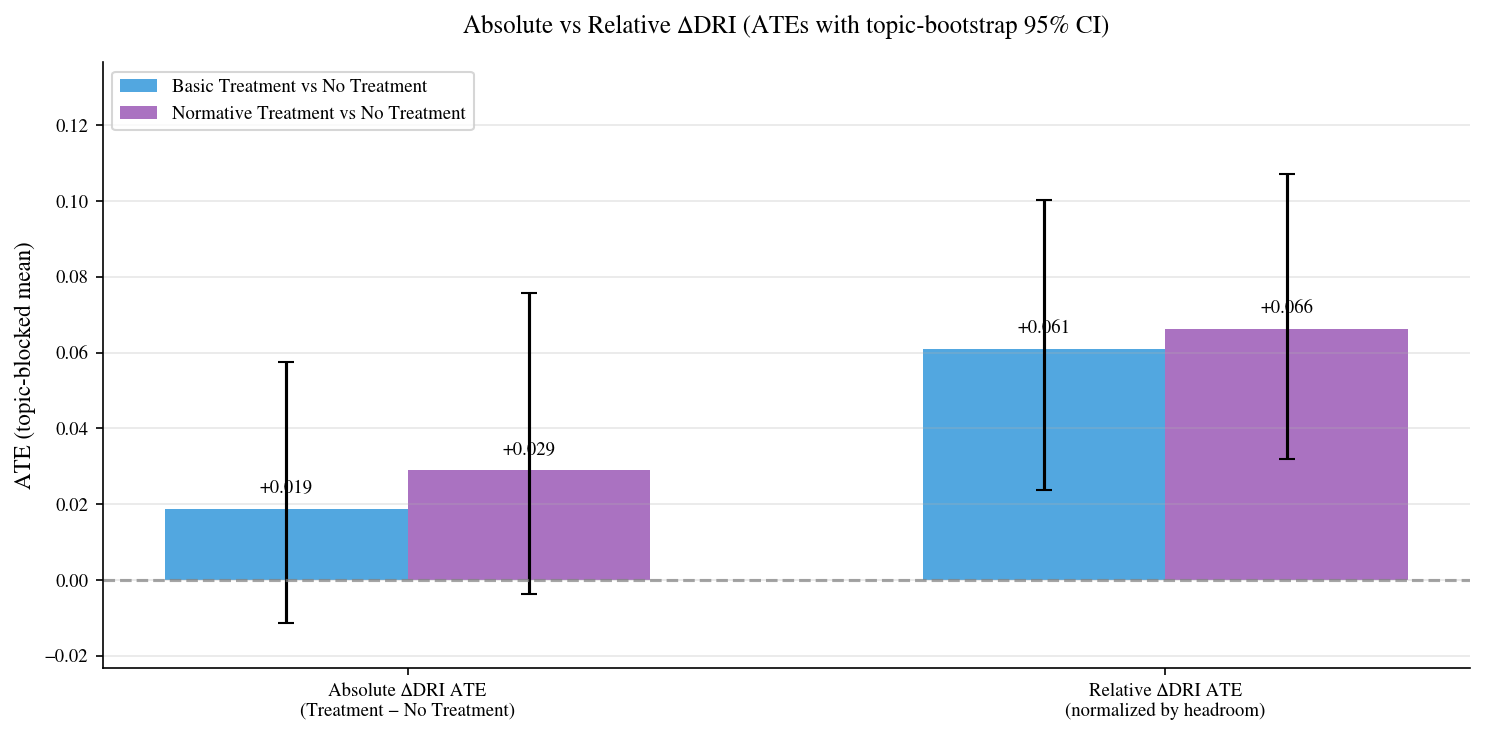


FIGURE SUMMARY (ATE_block_mean with topic-boot 95% CI)
Basic vs No | delta_dri      mean=+0.0187  CI95=[-0.0114, +0.0575]
Normative vs No | delta_dri  mean=+0.0290  CI95=[-0.0038, +0.0757]
Basic vs No | delta_dri_relative mean=+0.0609  CI95=[+0.0236, +0.1002]
Normative vs No | delta_dri_relative mean=+0.0663  CI95=[+0.0320, +0.1070]


In [104]:
# Figure Absolute vs Relative ΔDRI (ATE contrasts with topic-boot 95% CI)


CONDITION_COLORS = {
    "No Treatment": "#7f8c8d",
    "Basic Treatment": "#3498db",
    "Normative Treatment": "#9b59b6",
    "Human": "#2ecc71",
}

# ---------
# Helpers
# ---------
def get_contrast_row(df: pd.DataFrame, contrast: str, outcome: str) -> pd.Series:
    sub = df[(df["contrast"] == contrast) & (df["outcome"] == outcome)]
    if len(sub) == 0:
        avail_contrasts = sorted(df["contrast"].dropna().unique().tolist())
        avail_outcomes = sorted(df["outcome"].dropna().unique().tolist())
        raise ValueError(
            f"No row found for contrast='{contrast}', outcome='{outcome}'.\n"
            f"Available contrasts: {avail_contrasts}\n"
            f"Available outcomes: {avail_outcomes}"
        )
    if len(sub) > 1:
        print(f"[Warning] Multiple rows found for contrast='{contrast}', outcome='{outcome}'. Taking first.")
        sub = sub.iloc[[0]]
    return sub.iloc[0]

def mean_and_yerr_from_row(row: pd.Series):
    mean = float(row["ATE_block_mean"])
    lo = float(row["CI95_topic_boot_low"])
    hi = float(row["CI95_topic_boot_high"])
    # matplotlib asymmetric yerr = [[lower...], [upper...]]
    lower = max(0.0, mean - lo) if np.isfinite(lo) else 0.0
    upper = max(0.0, hi - mean) if np.isfinite(hi) else 0.0
    return mean, lower, upper, lo, hi

# ---------
# Choose what to show in Figure 8
# ---------
OUTCOME_ABS = "delta_dri"
OUTCOME_REL = "delta_dri_relative"

# These are the two "treatment effects vs control" you usually want
CONTRAST_BASIC = "Basic vs No Treatment"
CONTRAST_NORM  = "Normative vs No Treatment"

# Pull rows
basic_abs_row = get_contrast_row(pooled_results, CONTRAST_BASIC, OUTCOME_ABS)
norm_abs_row  = get_contrast_row(pooled_results, CONTRAST_NORM,  OUTCOME_ABS)

basic_rel_row = get_contrast_row(pooled_results, CONTRAST_BASIC, OUTCOME_REL)
norm_rel_row  = get_contrast_row(pooled_results, CONTRAST_NORM,  OUTCOME_REL)

# Extract means + yerr
basic_abs_mean, basic_abs_loerr, basic_abs_hierr, basic_abs_lo, basic_abs_hi = mean_and_yerr_from_row(basic_abs_row)
norm_abs_mean,  norm_abs_loerr,  norm_abs_hierr,  norm_abs_lo,  norm_abs_hi  = mean_and_yerr_from_row(norm_abs_row)

basic_rel_mean, basic_rel_loerr, basic_rel_hierr, basic_rel_lo, basic_rel_hi = mean_and_yerr_from_row(basic_rel_row)
norm_rel_mean,  norm_rel_loerr,  norm_rel_hierr,  norm_rel_lo,  norm_rel_hi  = mean_and_yerr_from_row(norm_rel_row)

# Pack into plotting structures
x = np.array([0, 1])
width = 0.32

basic_means = [basic_abs_mean, basic_rel_mean]
norm_means  = [norm_abs_mean,  norm_rel_mean]

basic_yerr = np.array([
    [basic_abs_loerr, basic_rel_loerr],
    [basic_abs_hierr, basic_rel_hierr],
], dtype=float)

norm_yerr = np.array([
    [norm_abs_loerr, norm_rel_loerr],
    [norm_abs_hierr, norm_rel_hierr],
], dtype=float)

# ---------
# Plot
# ---------
fig, ax = plt.subplots(figsize=(10, 5))

bars_b = ax.bar(
    x - width/2,
    basic_means,
    width,
    yerr=basic_yerr,
    capsize=4,
    label="Basic Treatment vs No Treatment",
    alpha=0.85,
    color=CONDITION_COLORS["Basic Treatment"],
)

bars_n = ax.bar(
    x + width/2,
    norm_means,
    width,
    yerr=norm_yerr,
    capsize=4,
    label="Normative Treatment vs No Treatment",
    alpha=0.85,
    color=CONDITION_COLORS["Normative Treatment"],
)

# --- Headroom based on CI whiskers ---
all_lower = np.concatenate([
    np.array(basic_means) - basic_yerr[0],
    np.array(norm_means)  - norm_yerr[0],
])
all_upper = np.concatenate([
    np.array(basic_means) + basic_yerr[1],
    np.array(norm_means)  + norm_yerr[1],
])

y_min = float(np.nanmin(all_lower))
y_max = float(np.nanmax(all_upper))
y_range = max(1e-6, y_max - y_min)

ax.set_ylim(y_min - 0.10 * y_range, y_max + 0.25 * y_range)

ax.set_xticks(x)
ax.set_xticklabels([
    "Absolute ΔDRI ATE\n(Treatment − No Treatment)",
    "Relative ΔDRI ATE\n(normalized by headroom)"
])

ax.set_ylabel("ATE (topic-blocked mean)", fontsize=11)
ax.set_title("Absolute vs Relative ΔDRI (ATEs with topic-bootstrap 95% CI)", fontsize=12, pad=14)
ax.axhline(y=0, color="gray", linestyle="--", alpha=0.7)
ax.grid(True, alpha=0.3, axis="y")
ax.legend(loc="upper left")

# Value labels
for bars in [bars_b, bars_n]:
    for bar in bars:
        h = bar.get_height()
        yr = ax.get_ylim()[1] - ax.get_ylim()[0]
        offset = 0.02 * yr if h >= 0 else -0.02 * yr
        va = "bottom" if h >= 0 else "top"
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + offset,
            f"{h:+.3f}",
            ha="center",
            va=va,
            fontsize=9,
        )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "abs_vs_rel_ATE.pdf", format="pdf")
plt.savefig(FIGURES_DIR / "abs_vs_rel_ATE.png", format="png")
plt.show()

# ---------
# Summary print
# ---------
print("\n" + "=" * 70)
print("FIGURE SUMMARY (ATE_block_mean with topic-boot 95% CI)")
print("=" * 70)

def fmt(label, mean, lo, hi):
    return f"{label:<28} mean={mean:+.4f}  CI95=[{lo:+.4f}, {hi:+.4f}]"

print(fmt("Basic vs No | delta_dri",           basic_abs_mean, basic_abs_lo, basic_abs_hi))
print(fmt("Normative vs No | delta_dri",       norm_abs_mean,  norm_abs_lo,  norm_abs_hi))
print(fmt("Basic vs No | delta_dri_relative",  basic_rel_mean, basic_rel_lo, basic_rel_hi))
print(fmt("Normative vs No | delta_dri_relative", norm_rel_mean, norm_rel_lo, norm_rel_hi))


---

# 7. Participant Heterogeneity: Average Euclidean Distance Analysis

In [37]:
# Definitions

def compute_mean_pairwise_euclidean(vectors: np.ndarray) -> float:
    """
    Compute mean pairwise Euclidean distance between rows of a matrix.

    Args:
        vectors: numpy array of shape (n_participants, n_features)

    Returns:
        Mean pairwise Euclidean distance
    """
    if vectors.shape[0] < 2:
        return np.nan
    distances = pdist(vectors, metric='euclidean')
    return np.mean(distances)

def extract_response_vectors_llm(parsed_responses: dict) -> np.ndarray:
    """
    Extract and align response vectors from LLM parsed responses.
    Combines considerations and preferences into a single vector per participant.
    """
    if not parsed_responses:
        return np.array([])

    vectors = []
    for pid, data in parsed_responses.items():
        if not isinstance(data, dict):
            continue

        # Get considerations
        cons = data.get('consideration_ratings', data.get('considerations', {}))
        if not cons:
            continue

        # Get preferences
        prefs = data.get('preference_rankings', data.get('preferences', {}))
        if not prefs:
            continue

        # Sort by key and extract values
        c_keys = sorted([k for k in cons.keys() if k.startswith('C')], 
                       key=lambda x: int(x[1:]))
        p_keys = sorted([k for k in prefs.keys() if k.startswith('P')], 
                       key=lambda x: int(x[1:]))

        try:
            c_vals = [float(cons[k]) for k in c_keys]
            p_vals = [float(prefs[k]) for k in p_keys]
            vectors.append(c_vals + p_vals)
        except (TypeError, ValueError):
            continue

    if not vectors:
        return np.array([])

    # Ensure all vectors have same length
    min_len = min(len(v) for v in vectors)
    vectors = [v[:min_len] for v in vectors]

    return np.array(vectors)


In [38]:
# Data Preparation

print("=" * 70)
print("MEAN PAIRWISE EUCLIDEAN DISTANCE ANALYSIS")
print("=" * 70)

llm_by_condition = defaultdict(lambda: {"pre": [], "post": []})
llm_by_model_condition = defaultdict(lambda: {"pre": [], "post": []})
llm_by_topic_condition = defaultdict(lambda: {"pre": [], "post": []})
llm_by_topic_model_condition = defaultdict(lambda: {"pre": [], "post": []})
llm_topics_seen = set()

model_dirs = [d for d in Path(FINAL_DATA_DIR).iterdir() if d.is_dir() and not d.name.startswith(".")]

for model_dir in sorted(model_dirs):
    model_name = model_dir.name
    if model_name in ["dqi_scores_summary.csv", "dqi_scores_summary.json"]:
        continue

    for topic_dir in model_dir.iterdir():
        if not topic_dir.is_dir():
            continue

        topic_name = str(topic_dir.name)
        llm_topics_seen.add(topic_name)

        for condition_dir in topic_dir.iterdir():
            if not condition_dir.is_dir():
                continue

            cond_label = canon_condition_label(condition_dir.name)

            for json_file in condition_dir.glob("simulation_results*.json"):
                try:
                    with open(json_file, "r") as f:
                        sim_data = json_module.load(f)

                    for iteration_data in sim_data.get("detailed_results", []):
                        # pre
                        pre_parsed = (iteration_data.get("pre_deliberation", {}) or {}).get("parsed_responses", {}) or {}
                        if pre_parsed:
                            vecs = extract_response_vectors_llm(pre_parsed)
                            if vecs.shape[0] >= 2:
                                dist = compute_mean_pairwise_euclidean(vecs)
                                if np.isfinite(dist):
                                    llm_by_condition[cond_label]["pre"].append(dist)
                                    llm_by_model_condition[(model_name, cond_label)]["pre"].append(dist)
                                    llm_by_topic_condition[(topic_name, cond_label)]["pre"].append(dist)
                                    llm_by_topic_model_condition[(topic_name, model_name, cond_label)]["pre"].append(dist)

                        # post
                        post_parsed = (iteration_data.get("post_deliberation", {}) or {}).get("parsed_responses", {}) or {}
                        if post_parsed:
                            vecs = extract_response_vectors_llm(post_parsed)
                            if vecs.shape[0] >= 2:
                                dist = compute_mean_pairwise_euclidean(vecs)
                                if np.isfinite(dist):
                                    llm_by_condition[cond_label]["post"].append(dist)
                                    llm_by_model_condition[(model_name, cond_label)]["post"].append(dist)
                                    llm_by_topic_condition[(topic_name, cond_label)]["post"].append(dist)
                                    llm_by_topic_model_condition[(topic_name, model_name, cond_label)]["post"].append(dist)

                except Exception:
                    continue

print(f"\nLLM topics found (n={len(llm_topics_seen)}): {sorted(llm_topics_seen)}")

condition_order = ["No Treatment", "Basic Treatment", "Normative Treatment"]

human_distances_pre = []
human_distances_post = []

# Response columns
response_cols = c_cols + p_cols

for survey in human_raw_filtered["survey"].astype(str).unique():
    sdat = human_raw_filtered[human_raw_filtered["survey"].astype(str) == survey].copy()

    for stage in ["Pre-Delib", "Post-Delib"]:
        stage_dat = sdat[sdat["stage_canon"] == stage].copy()
        if len(stage_dat) < 2:
            continue

        vecs = stage_dat[response_cols].to_numpy(dtype=float)

        # drop rows all-NaN
        keep = ~np.all(np.isnan(vecs), axis=1)
        vecs = vecs[keep]
        if vecs.shape[0] < 2:
            continue

        # impute NaN with column mean (fallback 0)
        col_means = np.nanmean(vecs, axis=0)
        for j in range(vecs.shape[1]):
            nan_mask = np.isnan(vecs[:, j])
            fill = col_means[j] if np.isfinite(col_means[j]) else 0.0
            vecs[nan_mask, j] = fill

        dist = compute_mean_pairwise_euclidean(vecs)
        if np.isfinite(dist):
            if stage == "Pre-Delib":
                human_distances_pre.append(dist)
            else:
                human_distances_post.append(dist)

human_distances_pre = np.array(human_distances_pre, dtype=float)
human_distances_post = np.array(human_distances_post, dtype=float)

MEAN PAIRWISE EUCLIDEAN DISTANCE ANALYSIS

LLM topics found (n=12): ['acp', 'auscj', 'bep', 'biobanking_wa', 'ccps', 'energy_futures', 'fnqcj', 'forestera', 'fremantle', 'swiss_health', 'uppsala_speaks', 'zukunft']


In [39]:
# Average Pairwise Euclidean Distance (Opinion Diversity)

print(f"\n{'='*70}")
print("HUMAN MC DISJOINT GROUPS OF 5 - MEAN PAIRWISE EUCLIDEAN DISTANCE")
print("="*70)

# --- Parameters ---
GROUP_SIZE = 5
N_DRAWS = 2000
SEED = RNG_SEED
PARTICIPANT_BOOTSTRAP = True   # recommended (topic-level participant bootstrap)
AGGREGATION = "topic_equal"    # "topic_equal" or "pooled_groups"

rng_master = np.random.default_rng(SEED)

# Use the canonical stage column you already created above
if "stage_canon" not in human_raw_filtered.columns:
    raise ValueError("Expected 'stage_canon' in human_raw_filtered. Did you run the stage normalization cell?")


def _impute_group(arr: np.ndarray) -> np.ndarray:
    """Impute NaNs within a group by column means (fallback to 0)."""
    out = arr.astype(float, copy=True)
    col_means = np.nanmean(out, axis=0)
    for j in range(out.shape[1]):
        nan_mask = np.isnan(out[:, j])
        fill = col_means[j] if np.isfinite(col_means[j]) else 0.0
        out[nan_mask, j] = fill
    return out

def _partition_disjoint(rng: np.random.Generator, n: int, group_size: int):
    """Random disjoint partition indices 0..n-1 into groups of size=group_size."""
    if n < group_size:
        return []
    k = n // group_size
    perm = rng.permutation(n)
    take = perm[: k * group_size]
    return [take[i*group_size:(i+1)*group_size] for i in range(k)]

# --- Build paired participant matrices per topic (pre/post aligned by pnum) ---
human_topic_pairs = {}  # topic -> (pre_mat, post_mat)
topics_human = sorted(human_raw_filtered["survey"].astype(str).unique().tolist())

for topic in topics_human:
    topic_df = human_raw_filtered[human_raw_filtered["survey"].astype(str) == str(topic)].copy()

    pre_df = topic_df[topic_df["stage_canon"] == "Pre-Delib"].copy()
    post_df = topic_df[topic_df["stage_canon"] == "Post-Delib"].copy()
    if len(pre_df) == 0 or len(post_df) == 0:
        continue

    # Pair by pnum (participant observed pre+post)
    pre_keep = pre_df[["pnum"] + response_cols].copy()
    post_keep = post_df[["pnum"] + response_cols].copy()

    paired = pre_keep.merge(
        post_keep,
        on="pnum",
        how="inner",
        suffixes=("_pre", "_post"),
        validate="one_to_one"
    )
    if len(paired) < GROUP_SIZE:
        continue

    pre_cols = [c + "_pre" for c in response_cols]
    post_cols = [c + "_post" for c in response_cols]
    pre_mat = paired[pre_cols].to_numpy(dtype=float)
    post_mat = paired[post_cols].to_numpy(dtype=float)

    human_topic_pairs[str(topic)] = (pre_mat, post_mat)

print(f"Topics with >= {GROUP_SIZE} paired participants: {len(human_topic_pairs)} / {len(topics_human)}")
print(f"Topics: {sorted(human_topic_pairs.keys())}")

# --- Monte Carlo draws (overall + per-topic tracking) ---
draw_pre = []
draw_post = []
draw_delta = []
draw_topics_used = []
draw_groups_used = []

# NEW: per-topic distributions across draws
human_topic_draws = defaultdict(lambda: {"pre": [], "post": [], "delta": [], "n_groups": []})

for _ in range(N_DRAWS):
    draw_seed = int(rng_master.integers(0, 2**31 - 1))
    rng = np.random.default_rng(draw_seed)

    topic_means_pre = []
    topic_means_post = []
    pooled_pre = []
    pooled_post = []

    topics_used = 0
    groups_used = 0

    for topic, (pre_mat, post_mat) in human_topic_pairs.items():
        n = pre_mat.shape[0]
        if n < GROUP_SIZE:
            continue

        # Participant bootstrap (topic-level) to reflect sampling uncertainty
        if PARTICIPANT_BOOTSTRAP:
            boot_idx = rng.integers(0, n, size=n)
            pre_eff = pre_mat[boot_idx]
            post_eff = post_mat[boot_idx]
            n_eff = n
        else:
            pre_eff = pre_mat
            post_eff = post_mat
            n_eff = n

        groups = _partition_disjoint(rng, n_eff, GROUP_SIZE)
        if len(groups) == 0:
            continue

        g_pre = []
        g_post = []

        for idx in groups:
            pre_g = _impute_group(pre_eff[idx])
            post_g = _impute_group(post_eff[idx])

            dist_pre = compute_mean_pairwise_euclidean(pre_g) if pre_g.shape[0] >= 2 else np.nan
            dist_post = compute_mean_pairwise_euclidean(post_g) if post_g.shape[0] >= 2 else np.nan

            if np.isfinite(dist_pre):
                g_pre.append(dist_pre)
                pooled_pre.append(dist_pre)
            if np.isfinite(dist_post):
                g_post.append(dist_post)
                pooled_post.append(dist_post)

        # Topic contributes only if both stages have at least one valid group distance
        if len(g_pre) > 0 and len(g_post) > 0:
            t_pre = float(np.mean(g_pre))
            t_post = float(np.mean(g_post))
            t_delta = t_post - t_pre

            topic_means_pre.append(t_pre)
            topic_means_post.append(t_post)
            topics_used += 1
            groups_used += len(groups)

            # NEW: per-topic distribution across draws
            human_topic_draws[topic]["pre"].append(t_pre)
            human_topic_draws[topic]["post"].append(t_post)
            human_topic_draws[topic]["delta"].append(t_delta)
            human_topic_draws[topic]["n_groups"].append(len(groups))

    if AGGREGATION == "topic_equal":
        if topics_used >= 1:
            pre_m = float(np.mean(topic_means_pre))
            post_m = float(np.mean(topic_means_post))
        else:
            continue
    elif AGGREGATION == "pooled_groups":
        if len(pooled_pre) >= 1 and len(pooled_post) >= 1:
            pre_m = float(np.mean(pooled_pre))
            post_m = float(np.mean(pooled_post))
        else:
            continue
    else:
        raise ValueError("AGGREGATION must be 'topic_equal' or 'pooled_groups'")

    draw_pre.append(pre_m)
    draw_post.append(post_m)
    draw_delta.append(post_m - pre_m)
    draw_topics_used.append(topics_used)
    draw_groups_used.append(groups_used)

draw_pre = np.array(draw_pre, dtype=float)
draw_post = np.array(draw_post, dtype=float)
draw_delta = np.array(draw_delta, dtype=float)

print(f"\nMC draws used: {len(draw_pre)} / {N_DRAWS} (aggregation={AGGREGATION}, participant_bootstrap={PARTICIPANT_BOOTSTRAP})")
if len(draw_pre):
    print(f"Avg topics used per draw: {np.mean(draw_topics_used):.2f}")
    print(f"Avg disjoint groups per draw: {np.mean(draw_groups_used):.1f}")

    pre_mean, pre_sd = float(np.mean(draw_pre)), float(np.std(draw_pre, ddof=1))
    post_mean, post_sd = float(np.mean(draw_post)), float(np.std(draw_post, ddof=1))
    delta_mean, delta_sd = float(np.mean(draw_delta)), float(np.std(draw_delta, ddof=1))

    pre_ci = (float(np.percentile(draw_pre, 2.5)), float(np.percentile(draw_pre, 97.5)))
    post_ci = (float(np.percentile(draw_post, 2.5)), float(np.percentile(draw_post, 97.5)))
    delta_ci = (float(np.percentile(draw_delta, 2.5)), float(np.percentile(draw_delta, 97.5)))

    print(f"\nHuman (MC disjoint n=5) Pre:  mean={pre_mean:.3f}, SD={pre_sd:.3f}, 95% CI={pre_ci}")
    print(f"Human (MC disjoint n=5) Post: mean={post_mean:.3f}, SD={post_sd:.3f}, 95% CI={post_ci}")
    print(f"Human (MC disjoint n=5) Δ:    mean={delta_mean:+.3f}, SD={delta_sd:.3f}, 95% CI={delta_ci}")

# ============================================================
# NEW: Human per-topic analysis (MC disjoint n=5)
# ============================================================
print(f"\n{'='*70}")
print("HUMAN (MC disjoint n=5) — PER TOPIC")
print("="*70)
print(f"{'Topic':<20} {'Draws':>6} {'AvgGroups':>10} {'Pre':>9} {'Post':>9} {'Δ':>9} {'Δ 95% CI':>22}")
print("-"*70)

human_topic_rows = []
for topic in sorted(human_topic_draws.keys()):
    arr_pre = np.array(human_topic_draws[topic]["pre"], dtype=float)
    arr_post = np.array(human_topic_draws[topic]["post"], dtype=float)
    arr_delta = np.array(human_topic_draws[topic]["delta"], dtype=float)
    n_groups = np.array(human_topic_draws[topic]["n_groups"], dtype=float)

    if len(arr_delta) == 0:
        continue

    delta_ci = (float(np.percentile(arr_delta, 2.5)), float(np.percentile(arr_delta, 97.5)))
    row = {
        "topic": topic,
        "draws": int(len(arr_delta)),
        "avg_groups": float(np.mean(n_groups)) if len(n_groups) else np.nan,
        "pre_mean": float(np.mean(arr_pre)),
        "post_mean": float(np.mean(arr_post)),
        "delta_mean": float(np.mean(arr_delta)),
        "delta_ci_low": delta_ci[0],
        "delta_ci_high": delta_ci[1],
    }
    human_topic_rows.append(row)

    print(f"{topic:<20} {row['draws']:>6d} {row['avg_groups']:>10.2f} "
          f"{row['pre_mean']:>9.3f} {row['post_mean']:>9.3f} {row['delta_mean']:>+9.3f} "
          f"[{row['delta_ci_low']:>+7.3f}, {row['delta_ci_high']:>+7.3f}]")

human_topic_mc_df = pd.DataFrame(human_topic_rows)

# ============================================================
# NEW: LLM per-topic analysis (by condition) + per-model analysis
# ============================================================
# For per-topic breakdown, we need to have stored per-run distances by topic+condition.
# If your earlier parsing cell didn't store them, we (re)compute them here.
# This re-walks FINAL_DATA_DIR but only computes Euclidean distances (no DRI).
# ============================================================

need_topic_level_llm = "llm_by_topic_condition" not in globals()

if need_topic_level_llm:
    print(f"\n{'='*70}")
    print("Computing LLM per-topic distances (topic + condition + model) ...")
    print("="*70)

    llm_by_topic_condition = defaultdict(lambda: {'pre': [], 'post': []})
    llm_by_topic_model_condition = defaultdict(lambda: {'pre': [], 'post': []})

    model_dirs = [d for d in FINAL_DATA_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")]

    for model_dir in sorted(model_dirs):
        model_name = model_dir.name
        if model_name in ["dqi_scores_summary.csv", "dqi_scores_summary.json"]:
            continue

        for topic_dir in model_dir.iterdir():
            if not topic_dir.is_dir():
                continue
            topic_name = str(topic_dir.name)

            for condition_dir in topic_dir.iterdir():
                if not condition_dir.is_dir():
                    continue

                condition_label = canon_condition_label(condition_dir.name)

                for json_file in condition_dir.glob("simulation_results*.json"):
                    try:
                        with open(json_file, "r") as f:
                            sim_data = json_module.load(f)

                        for iteration_data in sim_data.get("detailed_results", []):
                            pre_data = iteration_data.get("pre_deliberation", {})
                            pre_parsed = pre_data.get("parsed_responses", {})
                            if pre_parsed:
                                vecs = extract_response_vectors_llm(pre_parsed)
                                if len(vecs) >= 2:
                                    dist = compute_mean_pairwise_euclidean(vecs)
                                    if np.isfinite(dist):
                                        llm_by_topic_condition[(topic_name, condition_label)]['pre'].append(dist)
                                        llm_by_topic_model_condition[(topic_name, model_name, condition_label)]['pre'].append(dist)

                            post_data = iteration_data.get("post_deliberation", {})
                            post_parsed = post_data.get("parsed_responses", {})
                            if post_parsed:
                                vecs = extract_response_vectors_llm(post_parsed)
                                if len(vecs) >= 2:
                                    dist = compute_mean_pairwise_euclidean(vecs)
                                    if np.isfinite(dist):
                                        llm_by_topic_condition[(topic_name, condition_label)]['post'].append(dist)
                                        llm_by_topic_model_condition[(topic_name, model_name, condition_label)]['post'].append(dist)

                    except Exception:
                        continue

# --- LLM PER TOPIC x CONDITION ---
print(f"\n{'='*70}")
print("LLM — PER TOPIC x CONDITION (Mean pairwise Euclidean distance)")
print("="*70)
print(f"{'Topic':<20} {'Condition':<18} {'N':>6} {'Pre':>9} {'Post':>9} {'Δ':>9}")
print("-"*70)

topic_cond_rows = []
for (topic, cond), dd in sorted(llm_by_topic_condition.items(), key=lambda x: (x[0][0], x[0][1])):
    pre = np.array(dd["pre"], dtype=float)
    post = np.array(dd["post"], dtype=float)
    if len(pre) == 0 or len(post) == 0:
        continue
    delta = float(np.mean(post) - np.mean(pre))
    topic_cond_rows.append({
        "topic": topic,
        "condition": cond,
        "n": int(min(len(pre), len(post))),
        "pre": float(np.mean(pre)),
        "post": float(np.mean(post)),
        "delta": delta,
    })
    print(f"{topic:<20} {cond:<18} {len(pre):>6} {np.mean(pre):>9.3f} {np.mean(post):>9.3f} {delta:>+9.3f}")

llm_topic_condition_df = pd.DataFrame(topic_cond_rows)

# --- LLM PER MODEL x CONDITION (you already computed llm_by_model_condition earlier; print again here) ---
print(f"\n{'='*70}")
print("LLM — PER MODEL x CONDITION (Mean pairwise Euclidean distance)")
print("="*70)
print(f"{'Model':<25} {'Condition':<18} {'N':>6} {'Pre':>9} {'Post':>9} {'Δ':>9}")
print("-"*70)

model_cond_rows = []
for (model_name, condition), data in sorted(llm_by_model_condition.items()):
    pre = np.array(data['pre'], dtype=float)
    post = np.array(data['post'], dtype=float)
    if len(pre) == 0 or len(post) == 0:
        continue
    delta = float(np.mean(post) - np.mean(pre))
    model_cond_rows.append({
        "model": model_name,
        "condition": condition,
        "n": int(min(len(pre), len(post))),
        "pre": float(np.mean(pre)),
        "post": float(np.mean(post)),
        "delta": delta,
    })
    print(f"{model_name:<25} {condition:<18} {len(pre):>6} {np.mean(pre):>9.3f} {np.mean(post):>9.3f} {delta:>+9.3f}")

llm_model_condition_df = pd.DataFrame(model_cond_rows)

# ============================================================
# Summary comparison table
# ============================================================
print(f"\n{'='*70}")
print("SUMMARY: LLM vs Human Pairwise Euclidean Distance")
print("="*70)
print(f"{'Source':<30} {'N':>6} {'Pre':>10} {'Post':>10} {'Change':>10}")
print("-"*70)

# Human (full topics)
print(f"{'Human (full topics)':<30} {len(human_distances_pre):>6} "
      f"{np.mean(human_distances_pre):>10.3f} {np.mean(human_distances_post):>10.3f} "
      f"{np.mean(human_distances_post)-np.mean(human_distances_pre):>+10.3f}")

# Human (MC disjoint groups of 5)
if len(draw_pre):
    print(f"{'Human (MC disjoint n=5)':<30} {len(draw_pre):>6} "
          f"{np.mean(draw_pre):>10.3f} {np.mean(draw_post):>10.3f} {np.mean(draw_delta):>+10.3f}")
else:
    print(f"{'Human (MC disjoint n=5)':<30} {0:>6} {'NA':>10} {'NA':>10} {'NA':>10}")

print("-"*70)

# LLM by condition (existing)
for cond in condition_order:
    if cond in llm_by_condition:
        pre = np.array(llm_by_condition[cond]['pre'], dtype=float)
        post = np.array(llm_by_condition[cond]['post'], dtype=float)
        if len(pre) and len(post):
            print(f"{('LLM ' + cond):<30} {len(pre):>6} "
                  f"{np.mean(pre):>10.3f} {np.mean(post):>10.3f} {np.mean(post)-np.mean(pre):>+10.3f}")

print(f"\nInterpretation:")
print(f"  - Lower distance = more agreement/similarity between participants")
print(f"  - Negative change = convergence during deliberation")
print(f"  - Positive change = divergence during deliberation")
print(f"  - Human (MC disjoint n=5): disjoint 5-person partitions per draw (optionally participant-bootstrapped);")
print(f"    uncertainty should be based on the distribution over draws, not on treating synthetic groups as i.i.d.")



HUMAN MC DISJOINT GROUPS OF 5 - MEAN PAIRWISE EUCLIDEAN DISTANCE
Topics with >= 5 paired participants: 12 / 12
Topics: ['acp', 'auscj', 'bep', 'biobanking_wa', 'ccps', 'energy_futures', 'fnqcj', 'forestera', 'fremantle', 'swiss_health', 'uppsala_speaks', 'zukunft']

MC draws used: 2000 / 2000 (aggregation=topic_equal, participant_bootstrap=True)
Avg topics used per draw: 12.00
Avg disjoint groups per draw: 77.0

Human (MC disjoint n=5) Pre:  mean=18.047, SD=0.315, 95% CI=(17.421806812679133, 18.67167727579633)
Human (MC disjoint n=5) Post: mean=16.887, SD=0.267, 95% CI=(16.37096954115765, 17.41185379583308)
Human (MC disjoint n=5) Δ:    mean=-1.160, SD=0.268, 95% CI=(-1.6882849297935536, -0.6502908490964885)

HUMAN (MC disjoint n=5) — PER TOPIC
Topic                 Draws  AvgGroups       Pre      Post         Δ               Δ 95% CI
----------------------------------------------------------------------
acp                    2000       9.00    23.360    23.963    +0.603 [ -0.656,  +

findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not found because none of the following families were found: Nimbus Roman
findfont: Generic family 'serif' not 

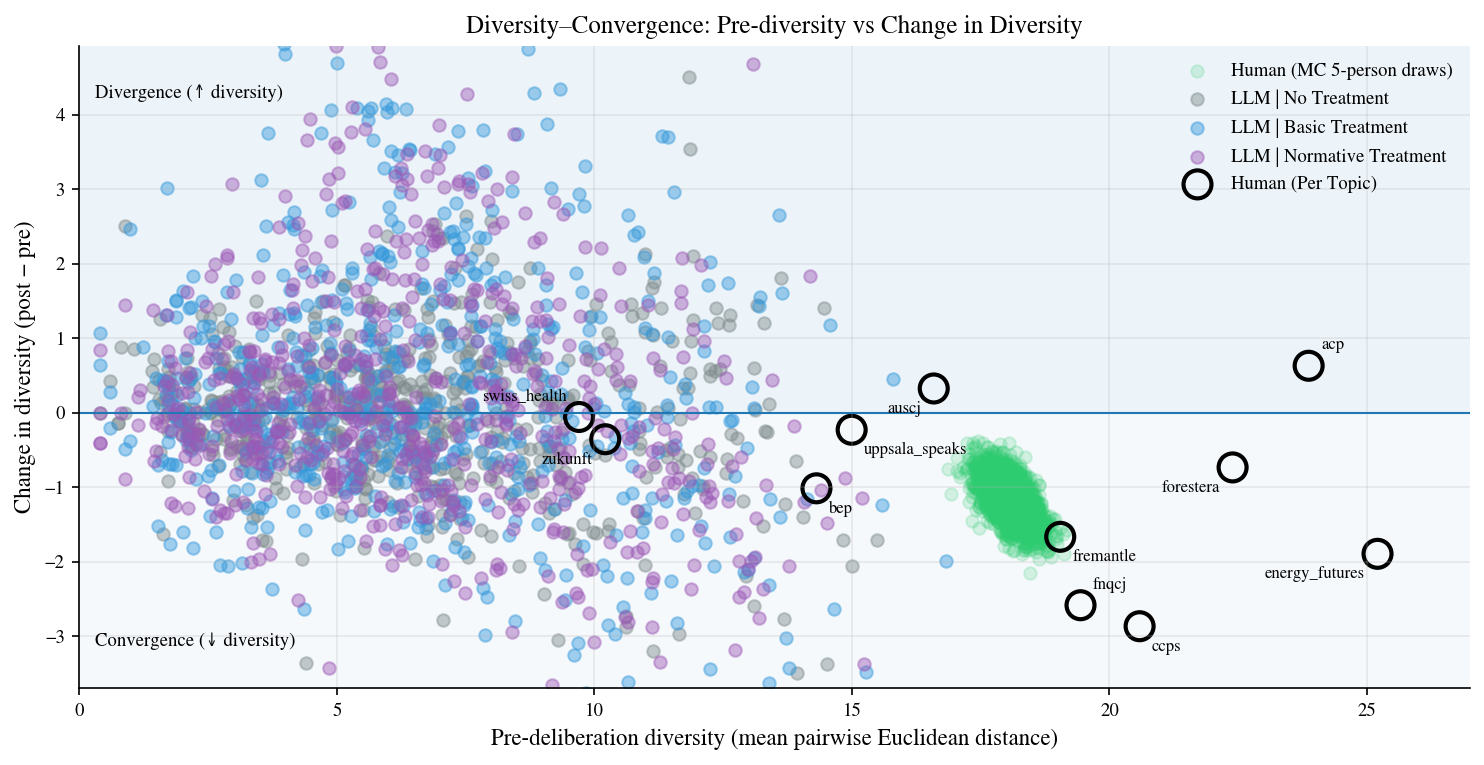

In [106]:
# Figure Diversity-Convergence


CONDITION_COLORS = {
    "No Treatment": "#7f8c8d",
    "Basic Treatment": "#3498db",
    "Normative Treatment": "#9b59b6",
    "Human": "#2ecc71",
}

need = ["llm_by_condition", "draw_pre", "draw_delta", "human_topic_pairs"]
missing = [k for k in need if k not in globals()]
if missing:
    raise NameError(f"Missing required objects: {missing}")

for fn in ["compute_mean_pairwise_euclidean", "_impute_group"]:
    if fn not in globals():
        raise NameError(f"Missing required function `{fn}` from your diversity section.")

# -------------------------
# Helpers
# -------------------------
def _canon_cond_for_colors(cond: str) -> str:
    c = str(cond).strip().lower()
    if "norm" in c:
        return "Normative Treatment"
    if "basic" in c:
        return "Basic Treatment"
    if "no" in c or "control" in c:
        return "No Treatment"
    return str(cond)

def _cond_sort_key(cond: str):
    c = str(cond).lower()
    if "norm" in c:   return 2
    if "basic" in c:  return 1
    if "no" in c or "control" in c: return 0
    return 1

# -------------------------
# Human MC draws
# -------------------------
x_mc = np.asarray(draw_pre, dtype=float)
y_mc = np.asarray(draw_delta, dtype=float)
m = np.isfinite(x_mc) & np.isfinite(y_mc)
x_mc, y_mc = x_mc[m], y_mc[m]

# -------------------------
# Human whole-topic points (one point per topic: all paired participants)
# -------------------------
topic_pts = []
for topic, (pre_mat, post_mat) in human_topic_pairs.items():
    pre_full = _impute_group(pre_mat)
    post_full = _impute_group(post_mat)

    pre_div = compute_mean_pairwise_euclidean(pre_full) if pre_full.shape[0] >= 2 else np.nan
    post_div = compute_mean_pairwise_euclidean(post_full) if post_full.shape[0] >= 2 else np.nan
    if np.isfinite(pre_div) and np.isfinite(post_div):
        topic_pts.append((str(topic), float(pre_div), float(post_div - pre_div)))

if len(topic_pts):
    x_topic = np.array([x for _, x, _ in topic_pts], dtype=float)
    y_topic = np.array([y for _, _, y in topic_pts], dtype=float)
else:
    x_topic = np.array([])
    y_topic = np.array([])

# -------------------------
# LLM points by condition
# -------------------------
llm_points = []  # (cond_raw, cond_canon, pre, delta)
for cond, v in llm_by_condition.items():
    pre = np.asarray(v.get("pre", []), dtype=float)
    post = np.asarray(v.get("post", []), dtype=float)
    mm = np.isfinite(pre) & np.isfinite(post)
    pre, post = pre[mm], post[mm]
    if len(pre) == 0 or len(post) == 0:
        continue
    n = min(len(pre), len(post))
    pre, post = pre[:n], post[:n]
    llm_points.append((str(cond), _canon_cond_for_colors(cond), pre, post - pre))

# sort so Normative is plotted last (on top)
llm_points = sorted(llm_points, key=lambda t: _cond_sort_key(t[1]))

# -------------------------
# Axis limits and compact sizing
# -------------------------
X_MIN, X_MAX = 0.0, 27.0

ys = [y_mc[(x_mc >= X_MIN) & (x_mc <= X_MAX)]]
if len(x_topic):
    ys.append(y_topic[(x_topic >= X_MIN) & (x_topic <= X_MAX)])
for _, _, pre, delta in llm_points:
    mask = np.isfinite(pre) & np.isfinite(delta) & (pre >= X_MIN) & (pre <= X_MAX)
    ys.append(delta[mask])

y_all = np.concatenate([a for a in ys if a is not None and len(a)]) if any(len(a) for a in ys) else np.array([])
y_all = y_all[np.isfinite(y_all)]
if len(y_all):
    lo, hi = np.quantile(y_all, [0.01, 0.99])
    pad = (hi - lo) * 0.12 if hi > lo else 1e-6
    Y_MIN, Y_MAX = float(lo - pad), float(hi + pad)
else:
    Y_MIN, Y_MAX = -1.0, 1.0

# Make figure only as wide as needed: set width proportional to data aspect
x_range = (X_MAX - X_MIN)
y_range = max(1e-6, (Y_MAX - Y_MIN))
aspect = x_range / y_range  # wider if x_range dominates
base_h = 5.2
fig_w = min(10.0, max(6.0, base_h * aspect))  # clamp to avoid absurd sizes

fig, ax = plt.subplots(figsize=(fig_w, base_h))
# Reduce outer margins so canvas hugs axes
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.14, top=0.92)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)

# quadrant shading
ax.axhspan(0, Y_MAX, alpha=0.08)
ax.axhspan(Y_MIN, 0, alpha=0.04)
ax.axhline(0.0, linewidth=1)

# Human MC draws (green)
ax.scatter(
    x_mc, y_mc,
    alpha=0.18,
    color=CONDITION_COLORS["Human"],
    label="Human (MC 5-person draws)"
)

# LLM points by condition (use provided palette)
seen = set()
for cond_raw, cond_canon, pre, delta in llm_points:
    color = CONDITION_COLORS.get(cond_canon, "#000000")
    lbl = f"LLM | {cond_canon}"
    # avoid duplicate legend entries if multiple keys map to same canon condition
    label = lbl if lbl not in seen else None
    seen.add(lbl)
    ax.scatter(pre, delta, alpha=0.45, color=color, label=label)

# Human whole-topic points
if len(x_topic):
    ax.scatter(
        x_topic, y_topic,
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=2,
        label="Human (Per Topic)"
    )

    # --- Topic labels (black dots) ---
    # topic_pts = [(topic, pre_div, delta), ...]
    for i, (t, x, y) in enumerate(topic_pts):
        # small alternating offsets to reduce overlap a bit
        dx = 6 if (i % 2 == 0) else -6
        dy = 6 if (i % 3 == 0) else -6
        ax.annotate(
            t,
            (x, y),
            textcoords="offset points",
            xytext=(dx, dy),
            ha="left" if dx > 0 else "right",
            va="bottom" if dy > 0 else "top",
            fontsize=8,
            color="black",
        )

ax.set_title("Diversity–Convergence: Pre-diversity vs Change in Diversity")
ax.set_xlabel("Pre-deliberation diversity (mean pairwise Euclidean distance)")
ax.set_ylabel("Change in diversity (post − pre)")
ax.grid(True, alpha=0.25)

ax.text(X_MIN + 0.3, Y_MAX - 0.06*(Y_MAX - Y_MIN), "Divergence (↑ diversity)", fontsize=9, va="top")
ax.text(X_MIN + 0.3, Y_MIN + 0.06*(Y_MAX - Y_MIN), "Convergence (↓ diversity)", fontsize=9, va="bottom")

ax.legend(loc="best", frameon=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "diversity_convergence.pdf", format="pdf")
plt.savefig(FIGURES_DIR / "diversity_convergence.png", format="png")
plt.show()



# 8. Descriptives

NO-TREATMENT BASELINE: ΔDRI VARIATION / MEASUREMENT NOISE
Runs (N): 660
Unique topic×model blocks: 132

Run-level ΔDRI distribution (survey-only baseline):
  mean      :  0.0021
  sd        :  0.1746
  median    : -0.0019
  p05       : -0.2276
  p25       : -0.0471
  p75       :  0.0329
  p95       :  0.2423
  min       : -0.7734
  max       :  1.2138
  frac_pos  :  0.4848
  frac_neg  :  0.5136
  mean_abs  :  0.0942
  rmse      :  0.1745

Topic-clustered mean(ΔDRI) with 95% CI:
  mean = 0.0021
  95% CI (topic bootstrap) = [-0.0122, 0.0231]
  95% CI (design t over topic means) = [-0.0199, 0.0241]
  clusters (topics) = 12

Within-(topic×model) replicate variability (No Treatment):
  mean SD within block      = 0.1117
  median SD within block    = 0.0797
  mean range within block   = 0.2769
  median range within block = 0.1952
  mean |block mean ΔDRI|    = 0.0456


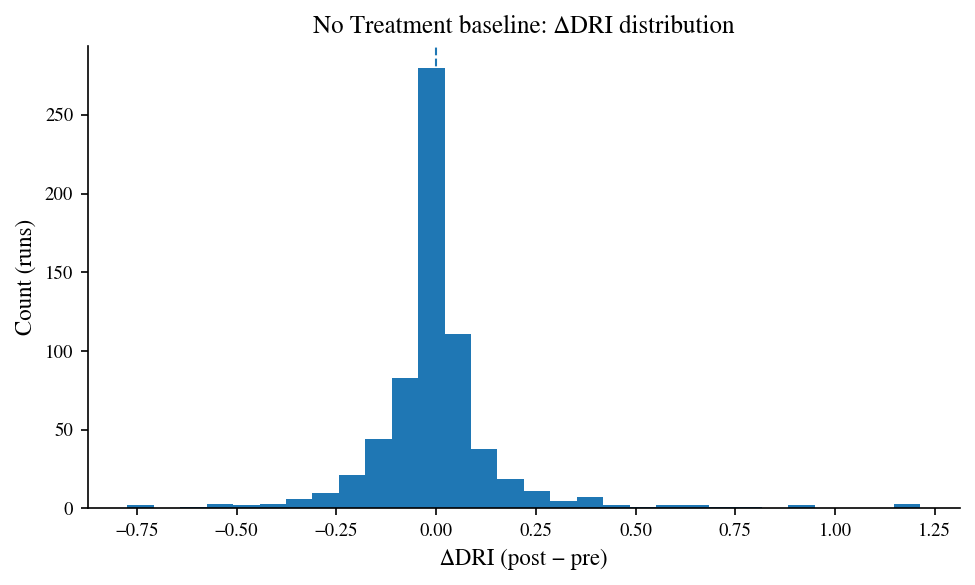


Top 10 noisiest topic×model blocks (by SD across repeats):
    topic     model_label  n    mean     sd     min    max  range  abs_mean
fremantle Claude Opus 4.5  5  0.3313 0.6307 -0.4705 1.1970 1.6676    0.3313
fremantle      Kimi-K2-NR  5 -0.0401 0.4949 -0.4407 0.7916 1.2324    0.0401
fremantle      DeepSeek-R  5  0.8616 0.4913  0.0177 1.2138 1.1962    0.8616
fremantle       Kimi-K2-R  5 -0.0266 0.4805 -0.7734 0.4977 1.2711    0.0266
fremantle         Mixed-R  5  0.0616 0.4484 -0.5119 0.6432 1.1551    0.0616
    fnqcj       Kimi-K2-R  5  0.2172 0.4412 -0.4677 0.7003 1.1679    0.2172
      acp       Kimi-K2-R  5 -0.1533 0.3766 -0.5519 0.3795 0.9313    0.1533
      acp        Mixed-NR  5  0.1621 0.3602 -0.2581 0.6225 0.8806    0.1621
      acp      Gemini-3-R  5 -0.0032 0.3434 -0.2760 0.5625 0.8386    0.0032
fremantle        Mixed-NR  5 -0.0028 0.3314 -0.5396 0.2419 0.7815    0.0028


{'condition': 'No Treatment',
 'n_runs': 660,
 'n_blocks': 132,
 'run_mean': 0.002134005612070883,
 'run_sd': 0.17464582980261348,
 'run_rmse': 0.17452651935943098,
 'run_mean_abs': 0.09415511952199211,
 'topic_cluster_mean': 0.0021340056120708827,
 'topic_ci_boot_low': -0.012240423159011976,
 'topic_ci_boot_high': 0.023139474966922143,
 'within_block_sd_mean': 0.11169653830794755,
 'within_block_sd_median': 0.07965438158458096,
 'within_block_range_mean': 0.2769187563106037,
 'within_block_range_median': 0.195173375918693}

In [107]:
# NO-TREATMENT BASELINE NOISE (ΔDRI at temperature=0.0)

BASELINE_COND = "No Treatment"

# --- Filter baseline runs
d0 = llm_df[llm_df["condition_label"] == BASELINE_COND].copy()
assert len(d0) > 0, "No 'No Treatment' rows found in llm_df."

d0 = d0.dropna(subset=["delta_dri", TOPIC_COL, MODEL_COL])
d0 = d0[np.isfinite(d0["delta_dri"].to_numpy())]

print("=" * 78)
print("NO-TREATMENT BASELINE: ΔDRI VARIATION / MEASUREMENT NOISE")
print("=" * 78)
print(f"Runs (N): {len(d0)}")
print(f"Unique topic×model blocks: {d0.groupby([TOPIC_COL, MODEL_COL]).ngroups}")

# --- Run-level distribution (noise magnitude under survey-only baseline)
x = d0["delta_dri"].to_numpy()

run_summary = {
    "mean": float(np.mean(x)),
    "sd": float(np.std(x, ddof=1)),
    "median": float(np.median(x)),
    "p05": float(np.percentile(x, 5)),
    "p25": float(np.percentile(x, 25)),
    "p75": float(np.percentile(x, 75)),
    "p95": float(np.percentile(x, 95)),
    "min": float(np.min(x)),
    "max": float(np.max(x)),
    "frac_pos": float(np.mean(x > 0)),
    "frac_neg": float(np.mean(x < 0)),
    "mean_abs": float(np.mean(np.abs(x))),
    "rmse": float(np.sqrt(np.mean(x**2))),  # typical deviation from 0
}

print("\nRun-level ΔDRI distribution (survey-only baseline):")
for k, v in run_summary.items():
    print(f"  {k:<10}: {v: .4f}")

# --- Topic-clustered uncertainty of the mean (should be ~0 under the null)
tc = topic_cluster_mean_ci(
    d0,
    value_col="delta_dri",
    topic_col=TOPIC_COL,
    B=BOOT_B,
    seed=RNG_SEED,
)

print("\nTopic-clustered mean(ΔDRI) with 95% CI:")
print(f"  mean = {tc['mean']:.4f}")
print(f"  95% CI (topic bootstrap) = [{tc['ci_boot'][0]:.4f}, {tc['ci_boot'][1]:.4f}]")
print(f"  95% CI (design t over topic means) = [{tc['ci_design'][0]:.4f}, {tc['ci_design'][1]:.4f}]")
print(f"  clusters (topics) = {tc['n_clusters']}")

# --- Within-(topic×model) replicate variability (same prompts/settings repeated)
# This directly supports: "non-negligible noise even at temperature=0.0"
block = (
    d0.groupby([TOPIC_COL, MODEL_COL])["delta_dri"]
      .agg(n="count", mean="mean", sd="std", min="min", max="max")
      .reset_index()
)

block["range"] = block["max"] - block["min"]
block["abs_mean"] = block["mean"].abs()

print("\nWithin-(topic×model) replicate variability (No Treatment):")
print(f"  mean SD within block      = {block['sd'].mean():.4f}")
print(f"  median SD within block    = {block['sd'].median():.4f}")
print(f"  mean range within block   = {block['range'].mean():.4f}")
print(f"  median range within block = {block['range'].median():.4f}")
print(f"  mean |block mean ΔDRI|    = {block['abs_mean'].mean():.4f}")

# --- Optional visualization: baseline ΔDRI histogram
fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.hist(x, bins=30)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_title("No Treatment baseline: ΔDRI distribution")
ax.set_xlabel("ΔDRI (post − pre)")
ax.set_ylabel("Count (runs)")
plt.tight_layout()
plt.show()

# --- Optional: show the noisiest blocks (largest within-block SD)
print("\nTop 10 noisiest topic×model blocks (by SD across repeats):")
print(
    block.sort_values("sd", ascending=False)
         .head(10)
         .to_string(index=False, float_format=lambda z: f"{z:.4f}")
)

# --- Store a compact dict for paper reporting / debugging
baseline_noise = {
    "condition": BASELINE_COND,
    "n_runs": int(len(d0)),
    "n_blocks": int(len(block)),
    "run_mean": run_summary["mean"],
    "run_sd": run_summary["sd"],
    "run_rmse": run_summary["rmse"],
    "run_mean_abs": run_summary["mean_abs"],
    "topic_cluster_mean": float(tc["mean"]),
    "topic_ci_boot_low": float(tc["ci_boot"][0]),
    "topic_ci_boot_high": float(tc["ci_boot"][1]),
    "within_block_sd_mean": float(block["sd"].mean()),
    "within_block_sd_median": float(block["sd"].median()),
    "within_block_range_mean": float(block["range"].mean()),
    "within_block_range_median": float(block["range"].median()),
}

baseline_noise